# Thực hành Bài 09 — Double DQN và REINFORCE trên Breakout (Atari)

Học phần Học tăng cường · Học kỳ 1, năm học 2026–2027.

Notebook thực hành thứ nhất của Bài 09 (`thuc-hanh-double-dqn-reinforce-cartpole-lunarlander-flappybird.ipynb`) đo độ chệch của phép cực đại (maximization bias) và cài đặt REINFORCE trên ba môi trường có quan sát là vector ngắn. Notebook này đưa hai thuật toán đó lên bài toán mà DQN được thiết kế cho nó: trò chơi Atari Breakout của Arcade Learning Environment (ALE), với quan sát là ảnh. Mnih và cộng sự (2015) huấn luyện DQN trên $5\cdot10^7$ khung hình, tức khoảng $1{,}25\cdot10^7$ bước tác tử khi mỗi hành động lặp bốn khung; van Hasselt, Guez và Silver (2016) dùng cùng tiền xử lý và siêu tham số cho Double DQN. Trên CPU, một triệu bước mất khoảng $7$–$9$ giờ, nên notebook gồm hai phần: các bước dựng và kiểm chạy trực tiếp trong vài phút, và kết quả của các lần huấn luyện một triệu bước chạy khi soạn, nhúng sẵn dưới dạng bảng và đường học.

Phần lý thuyết (độ chệch của phép cực đại, mục tiêu Double DQN, hàm điểm, REINFORCE, phương sai của ước lượng gradient) đã có ở notebook thứ nhất và ở ghi chú; notebook này chỉ nhắc lại công thức khi dùng.

**Mục tiêu.** Sau bài thực hành, người học có thể:

1. dựng chuỗi tiền xử lý Atari (lặp mỗi hành động qua bốn khung (frame skipping), ảnh xám $84\times84$, xếp chồng bốn khung (frame stacking), cắt phần thưởng (reward clipping), coi mất mạng là kết thúc khi huấn luyện (episodic life)) và phân biệt bài toán huấn luyện với bài toán đánh giá;
2. cài đặt bộ nhớ phát lại (experience replay) lưu mỗi khung một lần và mạng nơ-ron tích chập (convolutional neural network, CNN) của Mnih và cộng sự (2015), kiểm kích thước từng tầng;
3. tính tay mục tiêu Double DQN với mặt nạ kết thúc theo mất mạng và phần thưởng đã cắt, kiểm bằng `assert`;
4. đọc đường học, điểm trên trò chơi đầy đủ và độ lệch $\max_aQ_\theta-G_t$ của DQN và Double DQN sau một triệu bước, so với mốc công bố của Dopamine;
5. đọc kết quả của ba lần chạy REINFORCE trên Breakout (bước học lớn làm chính sách sụp, bản thuần, bản chuẩn hóa lợi tức) qua entropy, điểm và tần suất hành động, so với các chính sách hành động hằng.

**Tiên quyết.** Ghi chú Bài 09: Mục 2–3 (Mệnh đề 09.2, 09.4, Thuật toán 09.5, Nhận xét 09.6, Tình huống 09.1), Mục 5–6 (Định lý 09.23, Thuật toán 09.25, Hệ quả 09.26). Notebook thứ nhất của Bài 09: các mục 5 (mục tiêu Double DQN, phép đo độ lệch), 8–10 (REINFORCE, cấu hình `pytorch/examples`) và 12 (phương sai). Ghi chú Bài 08: Nhận xét 08.2 và Ví dụ 08.4 (xếp khung để quan sát gần Markov), Thuật toán 08.13.

**Bảng ký hiệu** (thống nhất với ghi chú Bài 09 và notebook thứ nhất):

| Ký hiệu | Ý nghĩa | Biến trong mã, kích thước |
|---|---|---|
| $X_t$ | ảnh gốc của trò chơi ở bước $t$ | `ale.getScreenRGB()`, cỡ `(210, 160, 3)`, `uint8` |
| $x_t$ | ảnh xám thu nhỏ, lấy cực đại hai khung cuối của bốn khung lặp cùng hành động | cỡ `(84, 84)`, `uint8` |
| $O_t$ | quan sát: bốn ảnh $x_{t-3},\dots,x_t$ xếp chồng | `o`, cỡ `(4, 84, 84)`, `uint8` |
| $A_t\in\mathcal A$, $m$ | hành động; $m=4$: `NOOP`, `FIRE`, `RIGHT`, `LEFT` | `a`; `n_act` |
| $R_{t+1}$, $\tilde R_{t+1}$ | phần thưởng gốc (điểm của gạch: $1$, $4$, $7$); phần thưởng đã cắt $\operatorname{sign}(R_{t+1})$ | `r`; `np.sign(r)` |
| $Z$, $U$ | cờ kết thúc dùng trong mục tiêu khi huấn luyện (hết ván hoặc mất mạng); cờ cắt ngắn ($27\,000$ bước tác tử) | `z`; `trunc` |
| $G_t$ | lợi tức chiết khấu tính bằng $\tilde R$ và $Z$ của bài toán huấn luyện | `G`, cỡ `(L,)` |
| $\theta$, $\theta^-$ | tham số mạng trực tuyến và mạng mục tiêu (mục 4–6) | `q_net`, `tgt` |
| $Q_\theta(O,\cdot)$ | vector giá trị hành động | `q_net(O)`, cỡ `(b, 4)` |
| $(O_i,A_i,\tilde R_i,O'_i,Z_i)$, $b$ | mẫu chuyển của mini-batch; cỡ mini-batch $32$ | `O, A, R, O2, Z`: `(32,4,84,84)`, `(32,)`, `(32,)`, `(32,4,84,84)`, `(32,)` |
| $a_i^*$, $y_i$ | hành động mạng trực tuyến chọn tại $O'_i$; mục tiêu | `(32, 1)`; `(32,)` |
| $N$, $N_{\mathrm{start}}$, $F$, $C$, $t_{\mathrm{end}}$ | dung lượng bộ nhớ (số khung); số bước trước bước tối ưu đầu; số bước môi trường giữa hai bước tối ưu; số bước tối ưu giữa hai lần đồng bộ; ngân sách | `cfg["N"]`, `cfg["N_start"]`, `cfg["F"]`, `cfg["C"]`, `cfg["T"]` |
| $\eta$, $\epsilon_{\mathrm{exp}}$, $\epsilon_{\mathrm{ev}}$ | tốc độ học của Adam; xác suất thăm dò khi huấn luyện; khi đánh giá ($0{,}05$) | `cfg["lr"]`; `eps`; `eps=0.05` |
| $\pi_\theta$, $\alpha$ | (mục 8) chính sách softmax trên đầu ra của cùng mạng tích chập; bước học của Adam | `net`; `cfg["lr"]` |
| $\mathcal H(\pi_\theta(\cdot\mid O))$ | entropy $-\sum_a\pi_\theta(a\mid O)\log\pi_\theta(a\mid O)$, tối đa $\log4\approx1{,}386$ | `entropy` |
| TB, sd, SE, df | trung bình; độ lệch chuẩn (standard deviation); sai số chuẩn (standard error) $\mathrm{sd}/\sqrt n$; số bậc tự do (degrees of freedom) của phân phối Student | (in trong bảng) |

Notebook dùng $t_{\mathrm{end}}$ cho ngân sách, như Thuật toán 09.5; trong mã khóa vẫn là `cfg["T"]` để khớp các tệp nhật ký chạy khi soạn. Hai đơn vị được tách bằng hai từ: ván (game) là một trò chơi đầy đủ năm mạng, dùng khi đánh giá và khi đặt lại môi trường; lượt huấn luyện (episode) là một mạng, kết thúc khi mất mạng hoặc hết ván (mục 2).

**Cách dùng.** Chạy các ô theo thứ tự; ô ở mục 1 tự cài các gói (ROM của Atari có sẵn trong gói `ale-py` từ phiên bản 0.9). Mọi phép ngẫu nhiên dùng hạt giống cố định. Các số dẫn trong văn bản được tạo với gymnasium 1.4.0, ale-py 0.12.1, torch 2.15.0+cpu; ô chạy trực tiếp in kèm số tham chiếu khi soạn để đối chiếu. Lần huấn luyện Double DQN chạy trực tiếp không phải lúc nào cũng lặp lại từng chữ số giữa các lần chạy (mục 6), nên số của nó chỉ được đọc như một hiện thực. Phần chạy trực tiếp gồm một lần Double DQN $40\,000$ bước và một lần REINFORCE $25\,000$ bước; với ngân sách đó, điểm kỳ vọng gần điểm của chính sách ngẫu nhiên. Các kết luận về thuật toán dựa trên các lần chạy một triệu bước ở mục 7 và 8. Thời gian chạy in ở cuối notebook. Không cần GPU. Khi có GPU (chẳng hạn Colab), biến `DEVICE` ở mục 1 tự chọn GPU cho mạng và mini-batch, giúp các nhiệm vụ dài ở mục 11; số tham chiếu chỉ tái lập trên CPU. Notebook không nạp trọng số mạng từ tệp hay đường dẫn ngoài.

## 1. Cài đặt và chuẩn bị

Ô mã dưới cài Gymnasium kèm phần mở rộng `atari` (gói `ale-py`, có sẵn ROM), OpenCV (dùng để thu nhỏ ảnh trong `AtariPreprocessing`), NumPy và Matplotlib, rồi cài PyTorch bản CPU nếu chưa có (Colab có sẵn). Cận trên phiên bản giữ API đã dùng khi soạn (gymnasium 1.4.0, ale-py 0.12.1, opencv-python-headless 5.0.0.93). Dòng *Note: you may need to restart the kernel* của `pip` không cần làm theo khi ô này chạy trước mọi lệnh `import`.

In [1]:
%pip install -q "gymnasium[atari]>=1.0,<2" "ale-py>=0.9,<0.13" "opencv-python-headless>=4,<6" numpy matplotlib
import importlib.util
if importlib.util.find_spec("torch") is None:       # Colab có sẵn torch; máy cục bộ chưa có thì cài bản CPU
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


Ô mã dưới nhập các gói, in phiên bản và đặt hằng số. Quy ước hạt giống (seed) giống notebook thứ nhất: ván huấn luyện thứ $k$ dùng `20_000 + 100_000 * s + k` với hạt giống tác tử $s$; mốc kiểm định trong lúc huấn luyện dùng $5$ ván `VALID_SEED + i`; đánh giá cuối dùng $30$ ván `TEST_SEED + i`. Mỗi ván Breakout dài hàng trăm tới hàng nghìn bước, nên số ván đánh giá nhỏ hơn notebook thứ nhất. `DEVICE` là GPU nếu có, ngược lại là CPU; mạng và mini-batch được chuyển sang `DEVICE`, còn môi trường và bộ nhớ phát lại luôn ở CPU.

In [2]:
import copy, hashlib, json, time
from importlib.metadata import version

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import patches
import gymnasium as gym
import ale_py
import torch
import torch.nn as nn
from IPython.display import HTML, display

ale_py.ALEInterface.setLoggerMode(ale_py.LoggerMode.Error)   # tắt dòng giới thiệu ALE in ra stderr
gym.register_envs(ale_py)                  # Gymnasium >= 1.0: đăng ký các môi trường ALE/...
T_START = time.time()
torch.set_num_threads(2)                   # số liệu huấn luyện phụ thuộc số luồng
print("gymnasium", gym.__version__, "| ale-py", ale_py.__version__, "| torch", torch.__version__,
      "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)

GAMMA = 0.99
VALID_SEED, TEST_SEED = 40_000, 30_000    # 5 ván kiểm định mỗi mốc; 30 ván đánh giá cuối
AGENT_SEED = 1
N_TEST = 30
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # GPU nếu có
print("thiết bị:", DEVICE)

gymnasium 1.4.0 | ale-py 0.12.1 | torch 2.15.0+cpu | numpy 2.5.4 | matplotlib 3.11.2
thiết bị: cpu


## 2. Breakout và chuỗi tiền xử lý

**Vấn đề.** Một ảnh $X_t$ cỡ $210\times160\times3$ không cho biết bóng đang đi lên hay đi xuống, nên ảnh đơn không là trạng thái Markov (Nhận xét 08.2). Ảnh cũng lớn: $100\,800$ byte, so với $4$–$12$ số thực ở notebook thứ nhất. Bảng dưới ghép chuỗi tiền xử lý của Mnih và cộng sự (2015) với lặp hành động ngẫu nhiên của Machado và cộng sự (2018), như Dopamine; CleanRL dùng cùng chuỗi nhưng không lặp hành động ngẫu nhiên. Ô mã dưới dựng chuỗi đó bằng các lớp bao (wrapper) của Gymnasium:

| Bước | Lớp bao | Tác dụng |
|---|---|---|
| 1 | `gym.make("ALE/Breakout-v5", frameskip=1, repeat_action_probability=0.25)` | trò chơi gốc; với xác suất $0{,}25$, mỗi khung lặp hành động trước thay cho hành động mới (lặp hành động ngẫu nhiên, sticky actions) |
| 2 | `AtariPreprocessing(noop_max=30, frame_skip=4, screen_size=84, grayscale_obs=True)` | đầu ván làm $1$–$30$ khung `NOOP` ngẫu nhiên (bắt đầu bằng thao tác rỗng, no-op starts); mỗi hành động lặp $4$ khung (frame skipping), ảnh là cực đại từng điểm ảnh của hai khung cuối (tránh nhấp nháy), đổi sang xám, thu về $84\times84$ |
| 3 | `FireOnStart` (viết trong notebook) | tự bấm `FIRE` (chỉ số $1$) sau khi đặt lại và sau mỗi lần mất mạng để phóng bóng; bước `FIRE` sau mất mạng được gộp vào mẫu chuyển của lần mất mạng (phần thưởng cộng vào); ghi cờ `life_lost`. Với lặp hành động ngẫu nhiên, `FIRE` có thể bị thay bằng hành động trước, khi đó tác tử tự chọn `FIRE` |
| 4 | `FrameStackObservation(4)` | xếp chồng khung (frame stacking): $O_t$ là bốn ảnh $x_{t-3},\dots,x_t$, cỡ $(4,84,84)$; đầu ván lặp ảnh đầu |

Giới hạn $108\,000$ khung, tức $27\,000$ bước tác tử, cắt ngắn ván ($U=1$). Ba quy ước sau chỉ áp dụng khi huấn luyện và không thay đổi môi trường:

- **Mất mạng là kết thúc** (episodic life): mẫu chuyển ở bước mất mạng có $Z=1$, nên mục tiêu không bootstrap qua lần mất mạng; môi trường không đặt lại, ván tiếp tục với mạng kế tiếp.
- **Cắt phần thưởng**: mục tiêu dùng $\tilde R=\operatorname{sign}(R)\in\{0,1\}$ thay cho điểm của gạch ($1$, $4$, $7$ tùy hàng).
- **Cắt ngắn**: khi $U=1$ (hết $27\,000$ bước), ván được đặt lại; mẫu chuyển cuối không có $O'$ nên không được rút.

Khi đánh giá, chính sách chơi trọn ván năm mạng, điểm là tổng phần thưởng gốc. Bài toán mà $Q_\theta$ học (phần thưởng cắt, kết thúc ở mỗi lần mất mạng) vì vậy khác bài toán dùng để chấm điểm; phép đo độ lệch ở mục 6–7 dùng bài toán huấn luyện, vì đó là đại lượng $Q_\theta$ ước lượng.

quan sát: (4, 84, 84) uint8 | hành động: ['NOOP', 'FIRE', 'RIGHT', 'LEFT'] | số mạng: 5 | giới hạn khung: 108000


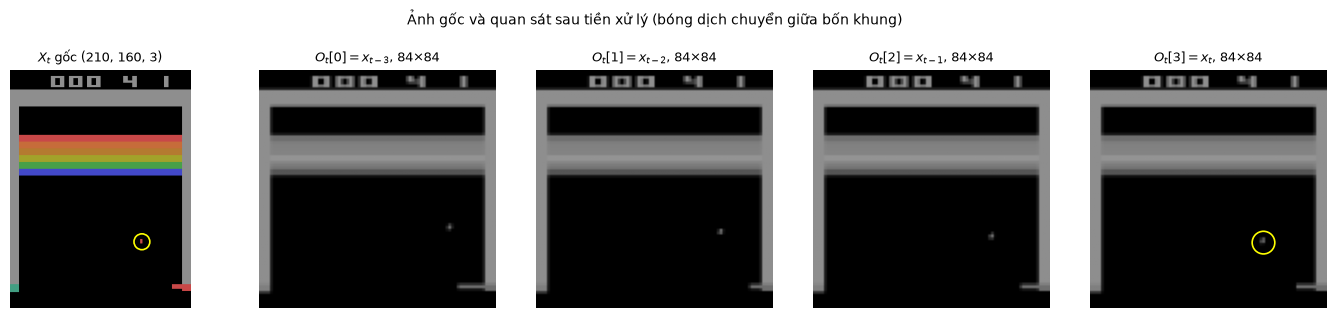

In [3]:
class FireOnStart(gym.Wrapper):
    # Breakout cần hành động FIRE (chỉ số 1) để phóng bóng: tự bấm sau reset và sau mỗi lần mất mạng
    def reset(self, **kw):
        o, info = self.env.reset(**kw)
        self.lives = info["lives"]
        o, _, term, trunc, info = self.env.step(1)
        return o, info

    def step(self, a):
        o, r, term, trunc, info = self.env.step(a)
        if info["lives"] < self.lives and not (term or trunc):
            o, r2, term, trunc, info = self.env.step(1)       # phóng bóng cho mạng mới
            r += r2
        info["life_lost"] = info["lives"] < self.lives          # dùng làm Z khi huấn luyện
        self.lives = info["lives"]
        return o, r, term, trunc, info


def make_breakout(sticky=0.25, max_steps=27_000, noop_max=30):
    env = gym.make("ALE/Breakout-v5", frameskip=1, repeat_action_probability=sticky,
                   max_episode_steps=max_steps * 4, full_action_space=False)            # giới hạn tính theo khung
    env = gym.wrappers.AtariPreprocessing(env, noop_max=noop_max, frame_skip=4, screen_size=84,
                                          terminal_on_life_loss=False, grayscale_obs=True, scale_obs=False)
    env = FireOnStart(env)
    return gym.wrappers.FrameStackObservation(env, 4)                                    # O_t: (4, 84, 84) uint8


env = make_breakout()
o, info = env.reset(seed=TEST_SEED)
print("quan sát:", np.asarray(o).shape, np.asarray(o).dtype, "| hành động:", env.unwrapped.get_action_meanings(),
      "| số mạng:", info["lives"], "| giới hạn khung:", env.spec.max_episode_steps)
assert np.asarray(o).shape == (4, 84, 84) and env.action_space.n == 4
rng = np.random.default_rng(0)
for _ in range(30):
    o, r, term, trunc, info = env.step(int(rng.integers(4)))
raw = env.unwrapped.ale.getScreenRGB()                       # X_t: (210, 160, 3)
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2))
ram = env.unwrapped.ale.getRAM(); bx, by = int(ram[99]) - 49, int(ram[101]) + 9       # vị trí bóng (mục 3)
axes[0].imshow(raw); axes[0].set_title(rf"$X_t$ gốc {raw.shape}", fontsize=9)
axes[0].add_patch(patches.Circle((bx + 1, by + 2), 7, fill=False, ec="yellow", lw=1.2))
for k in range(4):
    axes[k + 1].imshow(np.asarray(o)[k], cmap="gray", vmin=0, vmax=255)
    axes[k + 1].set_title((rf"$O_t[{k}]=x_{{t-{3 - k}}}$" if k < 3 else r"$O_t[3]=x_t$") + ", 84×84", fontsize=9)
axes[4].add_patch(patches.Circle(((bx + 1) * 84 / 160, (by + 2) * 84 / 210), 4, fill=False, ec="yellow", lw=1.2))
for ax in axes:
    ax.axis("off")
fig.suptitle("Ảnh gốc và quan sát sau tiền xử lý (bóng dịch chuyển giữa bốn khung)", fontsize=10); fig.tight_layout(); plt.show()

**Kiểm tra ba quy ước.** Ô mã dưới chạy chính sách chọn đều cho tới hết một ván, ghi mỗi bước phần thưởng gốc, cờ `life_lost` và hai cờ của môi trường, rồi kiểm: (i) có bước mất mạng mà ván chưa kết thúc, nên $Z=1$ khi huấn luyện còn `term` của môi trường bằng $0$; (ii) ở bước cuối ván, `term` $=1$ và số mạng về $0$; (iii) phép cắt đưa mọi điểm gạch $1$, $4$, $7$ về $1$ (kiểm trên số đặt sẵn, vì ván chọn đều hiếm khi phá gạch; mục 7 kiểm lại trên phần thưởng của một ván do DQN chơi). Ô cũng in các giá trị phần thưởng gốc gặp trong ván.

In [4]:
o, info = env.reset(seed=TEST_SEED)
rng = np.random.default_rng(TEST_SEED)
log = []                                                     # (phần thưởng gốc, life_lost, term, trunc, số mạng)
while True:
    o, r, term, trunc, info = env.step(int(rng.integers(4)))
    log.append((r, info["life_lost"], term, trunc, info["lives"]))
    if term or trunc:
        break
R = np.array([x[0] for x in log]); LL = np.array([x[1] for x in log]); TERM = np.array([x[2] for x in log])
Z_train = (LL | TERM).astype(float)                          # Z khi huấn luyện: mất mạng hoặc hết ván
print(f"{len(log)} bước | điểm gốc {R.sum():.0f} | phần thưởng gốc gặp: {sorted(set(R.tolist()))} | "
      f"số lần mất mạng {int(LL.sum())} | Z_train = 1 ở các bước {np.flatnonzero(Z_train).tolist()}")
k = int(np.flatnonzero(LL & ~TERM)[0])
print(f"bước {k}: life_lost = {LL[k]}, term của môi trường = {TERM[k]}, số mạng còn {log[k][4]} -> Z_train = {Z_train[k]:.0f}")
assert LL[k] and not TERM[k] and Z_train[k] == 1.0          # (i) mất mạng: Z = 1 khi huấn luyện, ván chưa hết
assert TERM[-1] and log[-1][4] == 0                          # (ii) hết ván ở bước cuối
assert np.sign([0.0, 1.0, 4.0, 7.0]).tolist() == [0.0, 1.0, 1.0, 1.0]   # (iii) cắt phần thưởng

119 bước | điểm gốc 0 | phần thưởng gốc gặp: [0.0] | số lần mất mạng 5 | Z_train = 1 ở các bước [23, 47, 71, 95, 118]
bước 23: life_lost = True, term của môi trường = False, số mạng còn 4 -> Z_train = 1


## 3. Đánh giá trên ván đầy đủ và trình phát

**Thước đo.** Hàm `evaluate` chơi $n$ ván, ván thứ $i$ dùng hạt giống `seed + i` cho cả `reset` lẫn bộ sinh số ngẫu nhiên của chính sách, và trả điểm gốc của từng ván cùng độ dài và cờ cắt ngắn. Chính sách theo $Q_\theta$ được đánh giá với $\epsilon_{\mathrm{ev}}=0{,}05$ như Mnih và cộng sự (2015): với xác suất $0{,}05$ chọn đều, ngược lại chọn $\arg\max_aQ_\theta(O_t,a)$. Với `value=True`, hàm ghi thêm $\max_aQ_\theta(O_t,a)$ ở mỗi bước và lợi tức $G_t$ của bài toán huấn luyện (phần thưởng cắt, $G_t$ dừng ở mỗi lần mất mạng), rồi tính $Q_0-G_0$ và độ lệch theo bước như notebook thứ nhất (mục 5): mọi bước của ván kết thúc thật, chỉ $t<L-300$ với ván bị cắt ngắn. Chính sách softmax (mục 8) được đánh giá bằng cách lấy mẫu từ $\pi_\theta$ (`eps=None`) hoặc tham lam (`eps=0`).

Mốc so sánh là chính sách chọn đều trên $30$ ván `TEST_SEED`.

In [5]:
def obs_tensor(o):
    # O_t (4, 84, 84) uint8 -> tensor (1, 4, 84, 84) trên DEVICE
    return torch.from_numpy(np.asarray(o)).unsqueeze(0).to(DEVICE)


def act_eps(net, o, eps, rng, n_act):
    # epsilon-tham lam theo Q_theta; o: (4, 84, 84) uint8
    if rng.random() < eps:
        return int(rng.integers(n_act))
    with torch.no_grad():
        return int(net(obs_tensor(o)).argmax())


def evaluate(net, n_episodes, seed, eps=0.05, max_steps=27_000, value=False, kind="q", sticky=0.25):
    # Ván đầy đủ 5 mạng, điểm gốc; kind="q": epsilon-tham lam theo Q; kind="pi": lấy mẫu từ pi (eps=None) hoặc tham lam
    env = make_breakout(sticky=sticky, max_steps=max_steps)
    n_act = env.action_space.n
    res = dict(score=[], length=[], trunc=[], Q0=[], G0=[], gap=[])
    for e in range(n_episodes):
        rng = np.random.default_rng(seed + e)
        o, info = env.reset(seed=seed + e)
        score, L, qs, rs, lifeend = 0.0, 0, [], [], []
        while True:
            if net is None:                                                  # chính sách chọn đều
                a = int(rng.integers(n_act))
            elif kind == "q":
                with torch.no_grad():
                    qv = net(obs_tensor(o))[0]                                   # Q_theta(O_t, .), (4,)
                qs.append(float(qv.max()))
                a = int(rng.integers(n_act)) if rng.random() < eps else int(qv.argmax())
            else:
                with torch.no_grad():
                    p = torch.softmax(net(obs_tensor(o))[0], -1).cpu().numpy().astype(float)
                a = int(min(np.searchsorted(np.cumsum(p), rng.random() * p.sum(), side="right"), n_act - 1)) \
                    if eps is None else int(p.argmax())
            o, r, term, trunc, info = env.step(a)
            score += r; L += 1; rs.append(float(np.sign(r))); lifeend.append(info["life_lost"] or term)
            if term or trunc:
                break
        res["score"].append(score); res["length"].append(L); res["trunc"].append(bool(trunc))
        if value and kind == "q" and net is not None:
            G = np.zeros(L); acc = 0.0
            for t in range(L - 1, -1, -1):                                   # G_t của bài toán huấn luyện
                acc = rs[t] + (0.0 if lifeend[t] else GAMMA * acc); G[t] = acc
            qs = np.array(qs); valid = L if not trunc else max(0, L - 300)
            res["Q0"].append(float(qs[0])); res["G0"].append(float(G[0])); res["gap"].append(float((qs[:valid] - G[:valid]).mean()))
    return {k: np.array(v) for k, v in res.items()}


def summarize(name, res):
    s = res["score"]; n = len(s)
    print(f"{name:<34} điểm {s.mean():6.2f} ± {s.std(ddof=1) / np.sqrt(n):5.2f} (sd {s.std(ddof=1):5.2f}, {n} ván) | "
          f"dài TB {res['length'].mean():6.0f} bước | cắt ngắn {res['trunc'].mean():4.0%}")


t0 = time.time()
res_random = evaluate(None, N_TEST, TEST_SEED)
summarize("chọn đều", res_random)
print(f"({time.time() - t0:.0f} giây) | tham chiếu khi soạn: chọn đều 1,40 ± 0,18 điểm, dài TB 170 bước")

chọn đều                           điểm   1.40 ±  0.18 (sd  0.97, 30 ván) | dài TB    170 bước | cắt ngắn   0%
(10 giây) | tham chiếu khi soạn: chọn đều 1,40 ± 0,18 điểm, dài TB 170 bước


**Trình phát.** Lưu ảnh của cả ván để phát lại sẽ nặng (mỗi khung $84\times84$ byte, một ván dài vài nghìn bước). Trình phát dưới vẽ lại khung hình từ một mảng nhẹ cho mỗi bước: tọa độ vợt, tọa độ bóng, số mạng và điểm, đọc từ bộ nhớ RAM $128$ byte của máy Atari, cùng lưới $6\times18$ gạch đọc từ ảnh gốc mỗi khi lưới đổi. Địa chỉ RAM của vợt và bóng không có trong tài liệu của ALE; bộ chú thích AtariARI (Anand và cộng sự, 2019) ghi cùng ba địa chỉ. Ô mã dưới kiểm chúng bằng thực nghiệm: chạy $3000$ bước chọn đều, tìm bóng và vợt trên ảnh gốc, rồi so với giá trị đọc từ RAM qua phép đổi tọa độ

$$x_{\text{bóng}}=\mathrm{RAM}[99]-49,\qquad y_{\text{bóng}}=\mathrm{RAM}[101]+9,\qquad x_{\text{vợt}}=\mathrm{RAM}[72]-47,$$

với $\mathrm{RAM}[101]=0$ khi không có bóng trên sân. Bóng được tìm trong vùng dưới hàng gạch (hàng $100$–$187$ của ảnh), vợt ở hàng $190$. Tỉ lệ khớp in ra là số liệu đo. Khi soạn, các lần không khớp của bóng là các khung bóng nằm sát mép vùng tìm (hàng $100$, hoặc sát tường trái với $x=7$); các lần không khớp của vợt là các khung có $\mathrm{RAM}[72]=191$ ($x=144$) trong khi ảnh có vợt ở vị trí khác. Trình phát vì vậy cắt tọa độ vợt vào khoảng $[8;136]$ để vợt không đè lên tường.

In [6]:
env_c = make_breakout(); ale = env_c.unwrapped.ale
o, _ = env_c.reset(seed=0); rng = np.random.default_rng(0)
n_ball = ok_bx = ok_by = n_pad = ok_pad = 0
for _ in range(3000):
    o, r, term, trunc, info = env_c.step(int(rng.integers(4)))
    if term or trunc:
        o, _ = env_c.reset()
    X, ram = ale.getScreenRGB(), ale.getRAM()                      # (210, 160, 3), (128,)
    ball = np.argwhere(X[100:188, 8:152].sum(2) > 0)               # điểm ảnh khác nền trong vùng giữa sân
    if len(ball) and ram[101] > 0:
        n_ball += 1; ok_bx += ball[:, 1].min() + 8 == ram[99] - 49; ok_by += ball[:, 0].min() + 100 == ram[101] + 9
    pad = np.flatnonzero(X[190, 8:152].sum(1) > 0)
    if 0 < len(pad) <= 16:                                         # chỉ vợt (rộng 16 điểm ảnh) trên hàng 190
        n_pad += 1; ok_pad += pad.min() + 8 == ram[72] - 47
print(f"bóng: {n_ball} khung, x khớp {ok_bx / n_ball:.1%}, y khớp {ok_by / n_ball:.1%} | vợt: {n_pad} khung, x khớp {ok_pad / n_pad:.1%}")

bóng: 2266 khung, x khớp 99.8%, y khớp 98.8% | vợt: 2935 khung, x khớp 99.1%


Hàm `record_breakout` ghi một ván theo cùng quy ước hạt giống với `evaluate` và trả: mảng `states` cỡ $(L+1,5)$ gồm (x vợt, x bóng, y bóng, số mạng, điểm), $-1$ cho bóng khi không có bóng; danh sách `grids` các cặp (bước, lưới gạch dạng chuỗi $108$ ký tự $0/1$) mỗi khi lưới đổi; mảng hành động. Hàm `breakout_player` dựng trình phát `<canvas>` (Phát/Dừng, thanh tua, tốc độ) từ các mảng đó; `breakout_strip` vẽ dải ảnh tĩnh bằng Matplotlib, hiển thị được khi không có JavaScript. Hình vẽ theo tọa độ của ảnh gốc $210\times160$; màu gạch theo hàng của trò chơi.

In [7]:
BRICK_COLORS = ["#c84848", "#c66c3a", "#b47a30", "#a2a22a", "#48a048", "#4248c8"]   # màu 6 hàng gạch, trên xuống


def read_bricks(ale):
    X = ale.getScreenRGB()
    ys, xs = 57 + 6 * np.arange(6) + 2, 8 + 8 * np.arange(18) + 3                  # tâm ô gạch (hàng 57-92, cột 8-151)
    return "".join("1" if v else "0" for v in (X[ys][:, xs].sum(2) > 0).ravel())   # 108 ký tự


def record_breakout(policy, seed, max_steps=27_000):
    # policy(o, rng) -> hành động; một ván đầy đủ, cùng quy ước hạt giống với evaluate
    env = make_breakout(max_steps=max_steps); ale = env.unwrapped.ale
    rng = np.random.default_rng(seed)
    o, info = env.reset(seed=seed)

    def state(score, lives):
        r = ale.getRAM()
        return [int(r[72]) - 47, int(r[99]) - 49 if r[101] else -1, int(r[101]) + 9 if r[101] else -1, lives, int(score)]

    S, A, score, grids = [state(0, info["lives"])], [], 0.0, [(0, read_bricks(ale))]
    while True:
        a = policy(o, rng); o, r, term, trunc, info = env.step(a)
        score += r; A.append(a); S.append(state(score, info["lives"]))
        g = read_bricks(ale)
        if g != grids[-1][1]:
            grids.append((len(A), g))
        if term or trunc:
            break
    return dict(states=np.array(S), actions=np.array(A), grids=grids, score=score, truncated=bool(trunc))


def grid_at(ep, k):
    g = ep["grids"][0][1]
    for step, gg in ep["grids"]:
        if step > k:
            break
        g = gg
    return g

Trình phát: 1 ván, HTML nhúng 7 kB


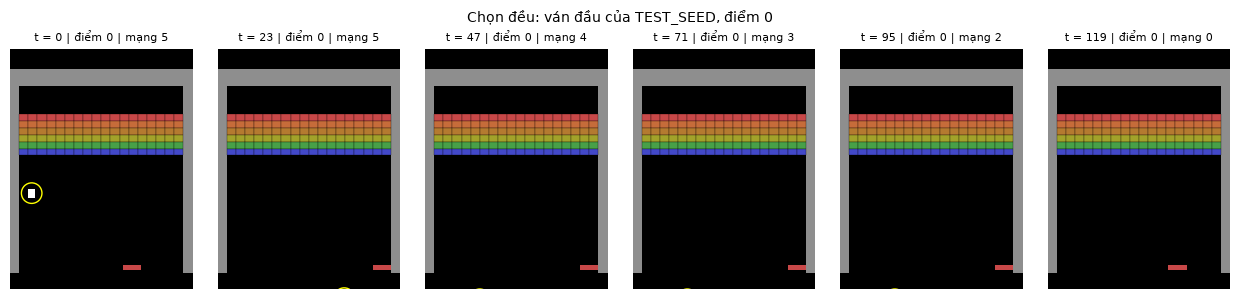

In [8]:
BREAKOUT_HTML = r"""
<div id="__ID__" style="font-family: sans-serif; font-size: 13px;">
  <div class="pl-nojs" style="color: #a00;">Trình phát cần JavaScript: tin cậy notebook hoặc chạy lại ô này.</div>
  <div class="pl-panels" style="display: flex; flex-wrap: wrap; gap: 8px;"></div>
  <div style="display: flex; align-items: center; gap: 8px; margin-top: 6px; max-width: 900px;">
    <button class="pl-play" style="font-size: 13px;">Phát</button>
    <input class="pl-slider" type="range" min="0" value="0" style="flex: 1;">
    <span class="pl-label" style="min-width: 150px;"></span>
    <select class="pl-speed" style="font-size: 13px;">
      <option value="0.5">0,5×</option><option value="1" selected>1× (15 bước/giây)</option>
      <option value="2">2×</option><option value="4">4×</option>
    </select>
  </div>
</div>
<script>
(function () {
  const root = document.getElementById('__ID__'); const D = __DATA__;
  root.querySelector('.pl-nojs').style.display = 'none';
  const SC = 1.6, W = 160 * SC, H = 210 * SC, dpr = window.devicePixelRatio || 1;
  const COL = D.colors;
  const panels = D.eps.map(function (ep) {
    const box = document.createElement('div');
    const title = document.createElement('div'); title.textContent = ep.name; title.style.fontWeight = 'bold';
    const cv = document.createElement('canvas'); cv.width = W * dpr; cv.height = H * dpr;
    cv.style.width = W + 'px'; cv.style.height = H + 'px'; cv.style.border = '1px solid #999';
    const st = document.createElement('div'); st.textContent = ep.reason;
    box.appendChild(title); box.appendChild(cv); box.appendChild(st);
    root.querySelector('.pl-panels').appendChild(box);
    const ctx = cv.getContext('2d'); ctx.scale(dpr * SC, dpr * SC);
    return {ep: ep, ctx: ctx};
  });
  const T = Math.max.apply(null, D.eps.map(function (e) { return e.s.length - 1; }));
  const slider = root.querySelector('.pl-slider'); slider.max = T;
  function gridAt(ep, k) {
    let g = ep.g[0][1];
    for (let i = 0; i < ep.g.length && ep.g[i][0] <= k; i++) g = ep.g[i][1];
    return g;
  }
  function draw(k) {
    panels.forEach(function (p) {
      const ep = p.ep, c = p.ctx, kk = Math.min(k, ep.s.length - 1), s = ep.s[kk], g = gridAt(ep, ep.steps[kk]);
      c.fillStyle = '#000'; c.fillRect(0, 0, 160, 210);
      c.fillStyle = '#8e8e8e'; c.fillRect(0, 17, 160, 15); c.fillRect(0, 32, 8, 164); c.fillRect(152, 32, 8, 164);
      for (let r = 0; r < 6; r++) for (let j = 0; j < 18; j++)
        if (g[18 * r + j] === '1') { c.fillStyle = COL[r]; c.fillRect(8 + 8 * j, 57 + 6 * r, 8, 6); }
      c.fillStyle = '#c84848'; c.fillRect(Math.min(Math.max(s[0], 8), 136), 189, 16, 4);   // vợt, trong khoảng sân
      if (s[1] >= 0) { c.fillStyle = '#ffffff'; c.fillRect(s[1] - 1, s[2] - 1, 4, 6); }   // bóng, phóng to để dễ thấy
      c.fillStyle = '#fff'; c.font = '9px sans-serif';
      c.fillText('điểm ' + s[4] + '   mạng ' + s[3], 10, 12);
    });
    root.querySelector('.pl-label').textContent = 'bước ' + panels[0].ep.steps[Math.min(k, panels[0].ep.s.length - 1)] +
      ' / ' + D.T_max;
  }
  let timer = null;
  const btn = root.querySelector('.pl-play');
  function stop() { clearInterval(timer); timer = null; btn.textContent = 'Phát'; }
  btn.onclick = function () {
    if (timer) { stop(); return; }
    btn.textContent = 'Dừng';
    const sp = parseFloat(root.querySelector('.pl-speed').value);
    timer = setInterval(function () {
      let k = parseInt(slider.value) + 1;
      if (k > T) { stop(); return; }
      slider.value = k; draw(k);
    }, 1000 / (15 * sp) * D.stride);
  };
  slider.oninput = function () { draw(parseInt(slider.value)); };
  root.querySelector('.pl-speed').onchange = function () { if (timer) { stop(); btn.click(); } };
  draw(0);
})();
</script>
"""
_BP_COUNT = [0]


def breakout_player(episodes, max_frames=1500):
    # episodes: {tên: lượt do record_breakout trả}; lượt dài được vẽ cách quãng để giữ HTML nhẹ
    L_max = max(len(e["actions"]) for e in episodes.values())
    stride = int(np.ceil(L_max / max_frames))
    eps = []
    for name, ep in episodes.items():
        L = len(ep["actions"]); idx = np.unique(np.r_[np.arange(0, L + 1, stride), L])
        eps.append({"name": name, "s": ep["states"][idx].tolist(), "steps": idx.tolist(), "g": ep["grids"],
                    "reason": f"{L} bước, điểm {ep['score']:.0f}" + (", cắt ngắn" if ep["truncated"] else ", hết mạng")})
    payload = json.dumps({"eps": eps, "stride": stride, "T_max": L_max, "colors": BRICK_COLORS}, separators=(",", ":"))
    _BP_COUNT[0] += 1
    uid = f"bp{_BP_COUNT[0]}_" + hashlib.md5(payload.encode()).hexdigest()[:8]
    html = BREAKOUT_HTML.replace("__ID__", uid).replace("__DATA__", payload)
    print(f"Trình phát: {len(episodes)} ván, HTML nhúng {len(html) / 1e3:.0f} kB"
          + ("" if stride == 1 else f"; vẽ mỗi {stride} bước để hiển thị trọn ván dài {L_max} bước"))
    return HTML(html)


def draw_breakout(ax, ep, k):
    s, g = ep["states"][k], grid_at(ep, k)
    ax.set_xlim(0, 160); ax.set_ylim(210, 0); ax.set_aspect("equal"); ax.axis("off")
    ax.add_patch(patches.Rectangle((0, 0), 160, 210, fc="black"))
    for rect in [(0, 17, 160, 15), (0, 32, 8, 164), (152, 32, 8, 164)]:
        ax.add_patch(patches.Rectangle(rect[:2], *rect[2:], fc="#8e8e8e"))
    for r in range(6):
        for j in range(18):
            if g[18 * r + j] == "1":
                ax.add_patch(patches.Rectangle((8 + 8 * j, 57 + 6 * r), 8, 6, fc=BRICK_COLORS[r], ec="black", lw=0.2))
    ax.add_patch(patches.Rectangle((min(max(s[0], 8), 136), 189), 16, 4, fc="#c84848"))   # vợt, trong khoảng sân
    if s[1] >= 0:
        ax.add_patch(patches.Rectangle((s[1] - 2, s[2] - 2), 6, 8, fc="white"))           # bóng, phóng to
        ax.add_patch(patches.Circle((s[1] + 1, s[2] + 2), 9, fill=False, ec="yellow", lw=1))
    ax.set_title(f"t = {k} | điểm {s[4]} | mạng {s[3]}", fontsize=8)


def breakout_strip(ep, n=6, title=""):
    L = len(ep["actions"]); ts = np.linspace(0, L, n).astype(int)
    fig, axes = plt.subplots(1, n, figsize=(2.1 * n, 3.0))
    for ax, k in zip(axes, ts):
        draw_breakout(ax, ep, k)
    fig.suptitle(title, fontsize=10); fig.tight_layout(); plt.show()


ep_random = record_breakout(lambda o, rng: int(rng.integers(4)), TEST_SEED)
assert len(ep_random["actions"]) == res_random["length"][0]     # trùng ván đầu của phép đánh giá
display(breakout_player({"chọn đều": ep_random}))
breakout_strip(ep_random, 6, f"Chọn đều: ván đầu của TEST_SEED, điểm {ep_random['score']:.0f}")

Mục 3 cho thước đo trên ván đầy đủ, mốc $1{,}40$ điểm của chính sách chọn đều và trình phát. Mục 4 dựng hai thành phần mà ảnh làm thay đổi so với notebook thứ nhất: mạng tích chập và bộ nhớ phát lại.

## 4. Mạng tích chập và bộ nhớ phát lại theo khung

**Mạng.** $Q_\theta$ dùng kiến trúc của Mnih và cộng sự (2015): ba tầng tích chập và một tầng ẩn $512$ nút, ReLU sau mỗi tầng trừ tầng ra. Ảnh `uint8` được chia cho $255$ ngay trong mạng.

| Tầng | Tham số | Đầu ra (một quan sát) |
|---|---|---|
| vào | — | $(4,84,84)$ |
| tích chập 1 | $32$ bộ lọc $8\times8$, bước $4$ | $(32,20,20)$ |
| tích chập 2 | $64$ bộ lọc $4\times4$, bước $2$ | $(64,9,9)$ |
| tích chập 3 | $64$ bộ lọc $3\times3$, bước $1$ | $(64,7,7)$, trải phẳng $3136$ |
| ẩn | $3136\to512$ | $512$ |
| ra | $512\to m$ | $m=4$ |

Kích thước theo công thức $\lfloor(n-k)/s\rfloor+1$: $(84-8)/4+1=20$, $(20-4)/2+1=9$, $9-3+1=7$. Số tham số $d=(4\cdot64\cdot32+32)+(32\cdot16\cdot64+64)+(64\cdot9\cdot64+64)+(3136\cdot512+512)+(512\cdot4+4)=1\,686\,180$.

**Bộ nhớ.** Một mẫu chuyển chứa hai quan sát $(4,84,84)$, tức $56\,448$ byte; $10^5$ mẫu chiếm $5{,}6$ GB. Bốn khung của $O'_i$ trùng ba khung của $O_i$ và trùng khung mới nhất của quan sát kế tiếp, nên `FrameReplay` chỉ lưu khung mới nhất $x_t$ của mỗi $O_t$ ($7\,056$ byte) cùng $A_t$, $\tilde R_{t+1}$, $Z_{t+1}$, cờ `first` (ô $i$ là quan sát đầu sau đặt lại) và cờ `nxt` (ô $i+1$ chứa $O'_i$). Hàm `_stack` dựng lại $O_i$ từ các ô $i-3,\dots,i$, không lùi qua đầu ván; $O'_i$ là chồng khung của ô $i+1$. Một chỉ số $i$ chỉ được rút khi ô $i+1$ đã ghi, khi lịch sử ba khung trước chưa bị ghi đè, và khi $Z_i=1$ hoặc ô $i+1$ chứa $O'_i$; mẫu cuối của ván bị cắt ngắn không có $O'$ nên không được rút. Ô mã kiểm `_stack` bằng cách so mọi chồng khung dựng lại với quan sát thật trên $2500$ bước, với bộ nhớ dung lượng $1000$ (đã quay vòng).

In [9]:
class NatureCNN(nn.Module):
    # Q_theta: (b, 4, 84, 84) uint8 -> (b, m); Mnih và cộng sự (2015)
    def __init__(self, n_act):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(4, 32, 8, 4), nn.ReLU(), nn.Conv2d(32, 64, 4, 2), nn.ReLU(),
                                  nn.Conv2d(64, 64, 3, 1), nn.ReLU(), nn.Flatten())       # (b, 3136)
        self.head = nn.Sequential(nn.Linear(64 * 7 * 7, 512), nn.ReLU(), nn.Linear(512, n_act))

    def forward(self, o):
        return self.head(self.conv(o.float() / 255.0))


class FrameReplay:
    # Ô i: khung mới nhất của O_i (84, 84), A_i, R_i (đã cắt), Z_i, first_i, nxt_i
    def __init__(self, N, stack=4):
        self.N, self.S, self.k, self.size = N, stack, 0, 0
        self.F = np.zeros((N, 84, 84), np.uint8)
        self.A = np.zeros(N, np.int64); self.R = np.zeros(N, np.float32); self.Z = np.zeros(N, np.float32)
        self.first = np.zeros(N, bool); self.nxt = np.zeros(N, bool)

    def add(self, o_stack, a, r, z, first, next_valid):
        i = self.k
        self.F[i] = o_stack[-1]; self.A[i], self.R[i], self.Z[i] = a, r, z
        self.first[i], self.nxt[i] = first, next_valid
        self.k = (i + 1) % self.N; self.size = min(self.size + 1, self.N)

    def _stack(self, idx):                                    # idx: (b,) -> (b, 4, 84, 84)
        cols = [idx]
        for _ in range(self.S - 1):
            prev = (cols[0] - 1) % self.N
            cols.insert(0, np.where(self.first[cols[0]], cols[0], prev))   # không lùi qua đầu ván
        return self.F[np.stack(cols, axis=1)]

    def sample(self, b, rng):
        out = []
        while len(out) < b:
            i = rng.integers(0, self.size, size=2 * b)
            age = (self.k - 1 - i) % self.N                   # 0: ô vừa ghi
            ok = (age >= 1) & ((self.Z[i] > 0) | self.nxt[i])
            if self.size == self.N:
                ok &= age <= self.N - self.S                  # ba khung trước chưa bị ghi đè
            out.extend(i[ok].tolist())
        idx = np.array(out[:b]); f = torch.from_numpy
        return (f(self._stack(idx)), f(self.A[idx]), f(self.R[idx]), f(self._stack((idx + 1) % self.N)), f(self.Z[idx]))


q_test = NatureCNN(4)
n_params = sum(p.numel() for p in q_test.parameters())
print("số tham số d =", n_params, "| Q_theta(O) cỡ", tuple(q_test(torch.from_numpy(np.asarray(o)).unsqueeze(0)).shape))
assert n_params == 1_686_180

# Kiểm bộ nhớ: so chồng khung dựng lại với quan sát thật
env_r = make_breakout(); Dm = FrameReplay(1000); rng = np.random.default_rng(0)
true_O, true_O2 = {}, {}
o, _ = env_r.reset(seed=0); first = True
for t in range(2500):
    a = int(rng.integers(4)); o2, r, term, trunc, info = env_r.step(a)
    i = Dm.k; Dm.add(o, a, np.sign(r), float(term or info["life_lost"]), first, not (term or trunc))
    true_O[i] = np.array(o); true_O2[i] = np.array(o2); first = False
    if term or trunc:
        o, _ = env_r.reset(); first = True
    else:
        o = o2
n_checked = 0
for i in range(Dm.N):
    if 1 <= (Dm.k - 1 - i) % Dm.N <= Dm.N - 4:                # chỉ các ô được phép rút
        assert np.array_equal(Dm._stack(np.array([i]))[0], true_O[i])
        if Dm.nxt[i]:
            assert np.array_equal(Dm._stack(np.array([(i + 1) % Dm.N]))[0], true_O2[i])
        n_checked += 1
O_, A_, R_, O2_, Z_ = Dm.sample(32, rng)
print(f"đã kiểm {n_checked} ô: O và O' dựng lại trùng quan sát thật | mini-batch:", tuple(O_.shape), tuple(A_.shape),
      tuple(O2_.shape), tuple(Z_.shape), f"| bộ nhớ {Dm.F.nbytes / 1e6:.1f} MB cho {Dm.N} khung")
assert O_.shape == (32, 4, 84, 84) and O2_.shape == (32, 4, 84, 84) and A_.shape == (32,)

số tham số d = 1686180 | Q_theta(O) cỡ (1, 4)


đã kiểm 996 ô: O và O' dựng lại trùng quan sát thật | mini-batch: (32, 4, 84, 84) (32,) (32, 4, 84, 84) (32,) | bộ nhớ 7.1 MB cho 1000 khung


## 5. Mục tiêu Double DQN với mặt nạ mất mạng

**Vấn đề.** Mục tiêu của Thuật toán 09.5 không đổi, $y_i=\tilde R_i+\gamma(1-Z_i)\,Q_{\theta^-}(O'_i,a_i^*)$ với $a_i^*=\arg\max_aQ_\theta(O'_i,a)$; điều mới là ý nghĩa của $\tilde R_i$ và $Z_i$ ở Breakout. Ô mã dưới kiểm bằng tính tay trên ba mẫu chuyển, với hai mạng tuyến tính đặt sẵn giá trị tại $O'$: $Q_\theta(O',\cdot)=(1;\,3;\,2;\,0)$ và $Q_{\theta^-}(O',\cdot)=(2;\,1{,}5;\,2{,}5;\,0)$, $\gamma=0{,}99$.

| Mẫu | Tình huống | $R$ gốc | $\tilde R$ | $Z$ khi huấn luyện | Double DQN $y$ | DQN $y$ |
|---|---|---|---|---|---|---|
| 1 | phá gạch hàng giữa, bóng còn | $4$ | $1$ | $0$ | $1+0{,}99\cdot1{,}5=2{,}485$ | $1+0{,}99\cdot2{,}5=3{,}475$ |
| 2 | mất mạng, ván còn | $0$ | $0$ | $1$ | $0$ | $0$ |
| 3 | phá gạch hàng trên rồi mất mạng | $7$ | $1$ | $1$ | $1$ | $1$ |

Ở mẫu 1, mạng trực tuyến chọn `FIRE` (chỉ số $1$ trong mã, giá trị $3$), mạng mục tiêu đánh giá nó bằng $1{,}5$; DQN lấy cực đại $2{,}5$ của mạng mục tiêu. Nếu mất mạng không được coi là kết thúc, mẫu 2 sẽ có $y=0+0{,}99\cdot1{,}5=1{,}485$: mục tiêu khi đó cộng giá trị của mạng kế tiếp vào lần mất mạng.

In [10]:
def dqn_loss(q_net, tgt_net, batch, gamma, double):
    O, A, R, O2, Z = batch                                    # R đã cắt; Z = 1 khi hết ván hoặc mất mạng
    q = q_net(O).gather(1, A.unsqueeze(1)).squeeze(1)         # Q_theta(O_i, A_i), (b,)
    with torch.no_grad():
        q2 = tgt_net(O2)                                      # Q_{theta^-}(O'_i, .), (b, m)
        boot = q2.gather(1, q_net(O2).argmax(1, keepdim=True)).squeeze(1) if double else q2.max(1).values
        y = R + gamma * (1 - Z) * boot
    return ((y - q) ** 2).mean(), q.detach(), y


on, tg = nn.Linear(1, 4, bias=False), nn.Linear(1, 4, bias=False)
with torch.no_grad():
    on.weight.copy_(torch.tensor([[1.0], [3.0], [2.0], [0.0]])); tg.weight.copy_(torch.tensor([[2.0], [1.5], [2.5], [0.0]]))
ones = torch.ones(3, 1)
R_raw = np.array([4.0, 0.0, 7.0]); Z_tr = torch.tensor([0.0, 1.0, 1.0])
batch3 = (ones, torch.zeros(3, dtype=torch.int64), torch.tensor(np.sign(R_raw), dtype=torch.float32), ones, Z_tr)
y_dd = dqn_loss(on, tg, batch3, 0.99, True)[2]; y_dq = dqn_loss(on, tg, batch3, 0.99, False)[2]
y_nolife = dqn_loss(on, tg, (*batch3[:4], torch.tensor([0.0, 0.0, 1.0])), 0.99, True)[2]   # bỏ quy ước mất mạng ở mẫu 2
print("Double DQN y =", y_dd.numpy().round(4), "| DQN y =", y_dq.numpy().round(4), "| mẫu 2 khi không coi mất mạng là kết thúc:",
      round(y_nolife[1].item(), 4))
assert torch.allclose(y_dd, torch.tensor([2.485, 0.0, 1.0])) and torch.allclose(y_dq, torch.tensor([3.475, 0.0, 1.0]))
assert abs(y_nolife[1].item() - 1.485) < 1e-6

Double DQN y = [2.485 0.    1.   ] | DQN y = [3.475 0.    1.   ] | mẫu 2 khi không coi mất mạng là kết thúc: 1.485


## 6. Double DQN chạy trực tiếp

**Vòng huấn luyện.** Hàm `train_dqn_atari` theo đúng thứ tự của Thuật toán 09.5, như `train_dqn` của notebook thứ nhất, với ba khác biệt của Atari: mẫu lưu vào `FrameReplay` có $\tilde R=\operatorname{sign}(R)$ và $Z=1$ khi hết ván hoặc mất mạng; ván chỉ đặt lại khi hết ván hoặc bị cắt ngắn; bước tối ưu bắt đầu khi $t\ge N_{\mathrm{start}}$. $\epsilon_{\mathrm{exp}}$ giảm tuyến tính từ $1$ tới $\epsilon_{\text{cuối}}$ trong phần $f_\epsilon$ của ngân sách. Mỗi $10\,000$ bước, hàm ghi trung bình điểm của $20$ ván huấn luyện gần nhất (điểm gốc, hành vi $\epsilon_{\mathrm{exp}}$-tham lam), trung bình $q_i$ và $y_i$ trên các mini-batch; mỗi `eval_every` bước, chạy $5$ ván `VALID_SEED` và giữ bản sao ở mốc tốt nhất.

**Cấu hình một triệu bước** (mục 7) và nguồn của từng tham số. Không thư viện nào được kiểm có Double DQN riêng cho Breakout; van Hasselt, Guez và Silver (2016) dùng cùng siêu tham số cho DQN và Double DQN, nên hai thuật toán ở đây chỉ khác mục tiêu. Cấu hình ghép từ ba nguồn, không trùng hoàn toàn nguồn nào:

| Tham số | Giá trị | Nguồn |
|---|---|---|
| tiền xử lý, $84\times84$, lặp hành động $4$ khung, xếp chồng $4$ khung, `NOOP` $1$–$30$ khung đầu ván, cắt phần thưởng, mất mạng là kết thúc | như bảng ở mục 2 | Mnih và cộng sự (2015); CleanRL `dqn_atari.py`; RL Baselines3 Zoo (`AtariWrapper`) |
| lặp hành động ngẫu nhiên, giới hạn $27\,000$ bước | $0{,}25$ | Machado và cộng sự (2018); Dopamine |
| mạng | Nature CNN | Mnih và cộng sự (2015) |
| bộ tối ưu, $\eta$; hàm mất mát | Adam $10^{-4}$; bình phương, không cắt gradient | CleanRL `dqn_atari.py` |
| $b$; $F$ | $32$; $4$ | Mnih và cộng sự (2015); CleanRL |
| $C$ | $250$ bước tối ưu ($1000$ bước môi trường) | CleanRL, RL Baselines3 Zoo |
| $N$ | $10^5$ khung | RL Baselines3 Zoo (CleanRL và Dopamine dùng $10^6$) |
| $N_{\mathrm{start}}$; lịch $\epsilon_{\mathrm{exp}}$ | $20\,000$; $1\to0{,}01$ trong $250\,000$ bước | Dopamine |
| $\epsilon_{\mathrm{ev}}$ | $0{,}05$ | Mnih và cộng sự (2015) |
| $t_{\mathrm{end}}$ | $10^6$ bước tác tử | ngân sách CPU khi soạn; CleanRL và RL Baselines3 Zoo dùng $10^7$ bước tác tử, Dopamine $5\cdot10^7$ bước tác tử ($200$ vòng × $2{,}5\cdot10^5$), Mnih và cộng sự (2015) $5\cdot10^7$ khung |

**Lần chạy trực tiếp** dùng $t_{\mathrm{end}}=40\,000$, $N=40\,000$, $N_{\mathrm{start}}=10\,000$, $\epsilon_{\mathrm{exp}}$ từ $1$ xuống $0{,}1$ trong cả ngân sách, các tham số khác như trên: $7\,501$ bước tối ưu, khoảng $7$–$10$ phút trên CPU hai luồng. Theo đường học của Dopamine (mục 7), điểm sau $2{,}5\cdot10^5$ bước còn khoảng $1{,}8$; sau $4\cdot10^4$ bước, điểm kỳ vọng gần điểm của chính sách chọn đều. Lần chạy này kiểm rằng vòng huấn luyện chạy đúng và cho thấy điểm xuất phát của đường học, không cho một chính sách chơi tốt.

In [11]:
def train_dqn_atari(cfg, seed=1, eval_every=None, verbose=False):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    env = make_breakout(sticky=cfg.get("sticky", 0.25)); n_act = env.action_space.n
    q_net, tgt = NatureCNN(n_act).to(DEVICE), NatureCNN(n_act).to(DEVICE)
    tgt.load_state_dict(q_net.state_dict())                                  # theta^- <- theta
    opt = torch.optim.Adam(q_net.parameters(), lr=cfg["lr"])
    D = FrameReplay(cfg["N"])
    T, b, F, C, N_start = cfg["T"], cfg["b"], cfg["F"], cfg["C"], cfg["N_start"]
    ep, t, k_opt, score, t0 = 0, 0, 0, 0.0, time.time()
    o, info = env.reset(seed=20_000 + 100_000 * seed + ep); first = True
    log = dict(ep_t=[], ep_score=[], loss_t=[], qmean=[], ymean=[], ck_t=[], ck_score=[])
    acc, best = [0.0, 0.0, 0], (-1e9, None)
    while t < T:
        eps = max(cfg["eps_end"], 1.0 - (1.0 - cfg["eps_end"]) * t / (cfg["eps_frac"] * T))
        a = act_eps(q_net, o, eps, rng, n_act)                               # bước 1
        o2, r, term, trunc, info = env.step(a); score += r
        z = float(term or info["life_lost"])                                 # mất mạng = kết thúc khi huấn luyện
        D.add(o, a, float(np.sign(r)), z, first, next_valid=not (term or trunc)); first = False
        if term or trunc:                                                    # chỉ đặt lại khi hết ván hoặc cắt ngắn
            log["ep_t"].append(t + 1); log["ep_score"].append(score); score = 0.0; ep += 1
            o, info = env.reset(seed=20_000 + 100_000 * seed + ep); first = True
        else:
            o = o2
        t += 1
        if t >= N_start and t % F == 0:                                      # bước 2-5
            batch = tuple(x.to(DEVICE) for x in D.sample(b, rng))           # mini-batch lên DEVICE
            L, q, y = dqn_loss(q_net, tgt, batch, GAMMA, cfg["double"])
            opt.zero_grad(); L.backward(); opt.step(); k_opt += 1
            if k_opt % C == 0:
                tgt.load_state_dict(q_net.state_dict())
            acc[0] += float(q.mean()); acc[1] += float(y.mean()); acc[2] += 1
        if t % 10_000 == 0 and acc[2]:
            log["loss_t"].append(t); log["qmean"].append(acc[0] / acc[2]); log["ymean"].append(acc[1] / acc[2]); acc = [0.0, 0.0, 0]
            if verbose:
                print(f"t = {t:6d} | {time.time() - t0:5.0f} giây | eps = {eps:.2f} | {ep} ván | điểm 20 ván cuối "
                      f"{np.mean(log['ep_score'][-20:]):5.2f} | TB q_i {log['qmean'][-1]:.3f}")
        if eval_every and t % eval_every == 0:
            ev = evaluate(q_net, 5, VALID_SEED, eps=0.05)
            log["ck_t"].append(t); log["ck_score"].append(float(ev["score"].mean()))
            if ev["score"].mean() > best[0]:
                best = (ev["score"].mean(), copy.deepcopy(q_net))
    log.update(k_opt=k_opt, n_episodes=ep, train_secs=time.time() - t0)
    return q_net, log, (best[1] if best[1] is not None else q_net)


CFG_1M = dict(T=1_000_000, N=100_000, N_start=20_000, b=32, F=4, C=250, lr=1e-4, eps_end=0.01, eps_frac=0.25, double=True)
CFG_LIVE = dict(CFG_1M, T=40_000, N=40_000, N_start=10_000, eps_end=0.1, eps_frac=1.0)
q_live, log_live, _ = train_dqn_atari(CFG_LIVE, seed=AGENT_SEED, verbose=True)
print(f"{log_live['train_secs']:.0f} giây | k_opt = {log_live['k_opt']} | {log_live['n_episodes']} ván huấn luyện")
assert log_live["k_opt"] == (CFG_LIVE["T"] - CFG_LIVE["N_start"]) // CFG_LIVE["F"] + 1

t =  10000 |    20 giây | eps = 0.78 | 54 ván | điểm 20 ván cuối  1.95 | TB q_i 0.018


t =  20000 |   160 giây | eps = 0.55 | 111 ván | điểm 20 ván cuối  1.55 | TB q_i 0.037


t =  30000 |   304 giây | eps = 0.33 | 169 ván | điểm 20 ván cuối  1.40 | TB q_i 0.087


t =  40000 |   451 giây | eps = 0.10 | 228 ván | điểm 20 ván cuối  1.25 | TB q_i 0.181
451 giây | k_opt = 7501 | 228 ván huấn luyện


Ô mã dưới đánh giá mạng vừa học trên $30$ ván `TEST_SEED` với $\epsilon_{\mathrm{ev}}=0{,}05$, đo $Q_0-G_0$ và độ lệch theo bước, so ghép cặp với chính sách chọn đều, rồi phát ván đầu của `TEST_SEED`.

In [12]:
res_live = evaluate(q_live, N_TEST, TEST_SEED, eps=0.05, value=True)
summarize("Double DQN, 40 000 bước", res_live)
d = res_live["score"] - res_random["score"]
print(f"  - chọn đều: {d.mean():+.2f} ± {1.96 * d.std(ddof=1) / np.sqrt(len(d)):.2f} (khoảng 95%, ghép cặp)")
print(f"  Q_0 = {res_live['Q0'].mean():.3f}, G_0 = {res_live['G0'].mean():.3f}, Q_0 - G_0 = {(res_live['Q0'] - res_live['G0']).mean():+.3f}, "
      f"độ lệch theo bước = {res_live['gap'].mean():+.3f}")
print("Tham chiếu khi soạn (torch 2.15.0+cpu, hai luồng, ba lần chạy): hai lần điểm 1,60 ± 0,52, hiệu với chọn đều "
      "+0,20 ± 1,04, Q_0 - G_0 = -0,061; một lần (máy tải nặng) 0,60 ± 0,11, hiệu -0,80 ± 0,45, Q_0 - G_0 = +0,073")
ep_live = record_breakout(lambda o, rng: act_eps(q_live, o, 0.05, rng, 4), TEST_SEED)
display(breakout_player({"chọn đều": ep_random, "Double DQN, 40 000 bước": ep_live}))

Double DQN, 40 000 bước            điểm   1.60 ±  0.52 (sd  2.84, 30 ván) | dài TB    162 bước | cắt ngắn   0%
  - chọn đều: +0.20 ± 1.04 (khoảng 95%, ghép cặp)
  Q_0 = 0.084, G_0 = 0.145, Q_0 - G_0 = -0.061, độ lệch theo bước = -0.033
Tham chiếu khi soạn (torch 2.15.0+cpu, hai luồng, ba lần chạy): hai lần điểm 1,60 ± 0,52, hiệu với chọn đều +0,20 ± 1,04, Q_0 - G_0 = -0,061; một lần (máy tải nặng) 0,60 ± 0,11, hiệu -0,80 ± 0,45, Q_0 - G_0 = +0,073


Trình phát: 2 ván, HTML nhúng 9 kB


**Đọc kết quả.** Khi soạn, ô huấn luyện và ô này được chạy ba lần với cùng phiên bản gói và hai luồng CPU. Hai lần cho đúng cùng các số: điểm $1{,}60\pm0{,}52$, hiệu ghép cặp với chính sách chọn đều $+0{,}20\pm1{,}04$, $228$ ván huấn luyện. Một lần, chạy khi máy đang chạy song song nhiều lần huấn luyện khác, cho $0{,}60\pm0{,}11$ và hiệu $-0{,}80\pm0{,}45$, thấp hơn chọn đều một cách phân biệt được; nhật ký của lần đó tách khỏi hai lần kia từ mốc $20\,000$ bước ($113$ so với $111$ ván). Nguyên nhân chưa được xác định, nên số in ở ô trên có thể khác số tham chiếu. Các khoảng ghép cặp này chỉ nói về một mạng cụ thể trên $30$ ván, không nói về thuật toán. Kết quả phù hợp với kỳ vọng đã nêu: sau $7\,501$ bước tối ưu, mạng mới thấy khoảng $225$ ván, phần lớn do hành vi gần ngẫu nhiên sinh ra, và điểm 20 ván huấn luyện gần nhất vẫn quanh $1{,}2$–$2$. Giá trị mạng báo còn rất nhỏ ($Q_0\approx0{,}1$), nên $Q_0-G_0$ ở đây chưa có ý nghĩa so sánh. Mục 7 cho thấy cùng thuật toán và cấu hình đi tiếp tới đâu khi có một triệu bước.

## 7. Kết quả một triệu bước: DQN và Double DQN

**Cách chạy khi soạn.** Hàm `train_dqn_atari` với cấu hình `CFG_1M` ở mục 6, hạt giống tác tử $1$, $2$, $3$ cho mỗi thuật toán, sáu lần chạy song song cùng các thí nghiệm khác; mỗi lần mất khoảng $7$–$9$ giờ. Mỗi $10\,000$ bước, nhật ký ghi điểm trung bình của $20$ ván huấn luyện gần nhất và trung bình $q_i$; mỗi $10^5$ bước, $5$ ván `VALID_SEED` với $\epsilon_{\mathrm{ev}}=0{,}05$. Sau huấn luyện, chính sách cuối được đánh giá trên $30$ ván `TEST_SEED` bằng `evaluate(..., value=True)`. Ô mã dưới nạp dữ liệu đã nhúng, gồm toàn bộ nhật ký, không gồm trọng số mạng.

**Mốc so sánh.** Dopamine (Castro và cộng sự, 2018) công bố đường học của DQN trên Breakout với lặp hành động ngẫu nhiên $0{,}25$, năm hạt giống (tệp `baselines/atari/data/breakout.json`). Mỗi số của Dopamine là trung bình điểm của mọi ván huấn luyện trong một vòng $250\,000$ bước tác tử: số ghi ở "$1$ triệu bước" là trung bình các ván trong khoảng $750\,000$–$10^6$ bước, số ở "$0{,}25$ triệu bước" là trung bình khoảng $0$–$250\,000$, gồm cả giai đoạn $\epsilon_{\mathrm{exp}}$ còn lớn. Bản Adam với hàm mất mát bình phương đạt $1{,}8$; $6{,}5$; $18{,}9$; $38{,}3$ ở bốn vòng kết thúc tại $0{,}25$; $0{,}5$; $1$; $2$ triệu bước; bản RMSProp đạt $1{,}6$; $3{,}1$; $6{,}7$; $16{,}3$. Hình vẽ mỗi số của Dopamine thành một đoạn ngang trên cả vòng tương ứng. Notebook đo trung bình $20$ ván huấn luyện gần nhất tại đúng bước $t$, nên tại cùng một mốc, số của notebook đến từ giai đoạn muộn hơn trong vòng tương ứng. Ngoài giao thức đo, cấu hình khác Dopamine ở: mất mạng là kết thúc (Dopamine không dùng); bắt đầu bằng thao tác rỗng (Dopamine không dùng); Adam với $\eta=10^{-4}$ (Dopamine: $6{,}25\cdot10^{-5}$, hằng số ổn định $1{,}5\cdot10^{-4}$); chu kỳ đồng bộ $1000$ bước môi trường (Dopamine: $8000$); $N=10^5$ khung (Dopamine: $10^6$). Phép so vì vậy chỉ cho biết các lần chạy ở đây có nằm trong vùng hợp lý hay không.

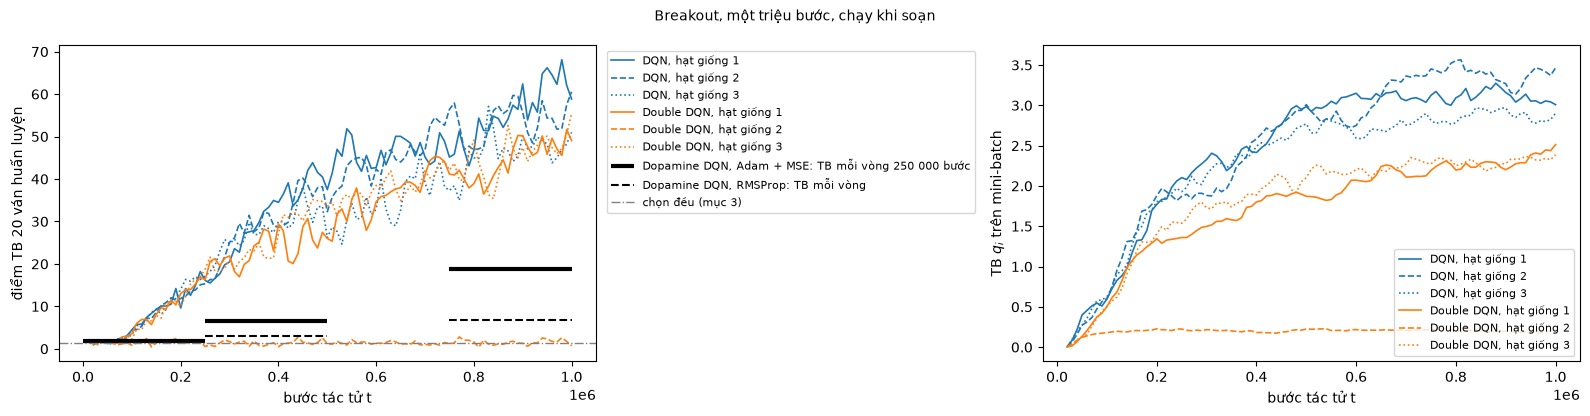

In [13]:
TABLES = json.loads(r'''{"dqn":{"dqn":{"1":{"prog":[[20000,1.4,0.005,0.921],[30000,1.55,0.083,0.881],[40000,2.0,0.216,0.842],[50000,1.25,0.397,0.802],[60000,1.55,0.456,0.762],[70000,1.75,0.512,0.723],[80000,1.75,0.546,0.683],[90000,3.0,0.51,0.644],[100000,4.5,0.597,0.604],[110000,5.75,0.724,0.564],[120000,5.8,0.828,0.525],[130000,7.4,0.885,0.485],[140000,8.35,0.973,0.446],[150000,9.3,1.16,0.406],[160000,10.1,1.322,0.366],[170000,10.1,1.331,0.327],[180000,10.5,1.446,0.287],[190000,14.2,1.695,0.248],[200000,9.6,1.771,0.208],[210000,14.2,1.833,0.168],[220000,12.6,1.839,0.129],[230000,14.9,1.984,0.089],[240000,18.2,2.061,0.05],[250000,16.1,2.103,0.01],[260000,15.5,2.079,0.01],[270000,16.6,2.163,0.01],[280000,17.65,2.224,0.01],[290000,19.8,2.274,0.01],[300000,20.5,2.328,0.01],[310000,23.6,2.406,0.01],[320000,22.75,2.374,0.01],[330000,27.25,2.303,0.01],[340000,27.55,2.19,0.01],[350000,27.85,2.238,0.01],[360000,29.75,2.332,0.01],[370000,32.4,2.455,0.01],[380000,33.35,2.49,0.01],[390000,34.95,2.426,0.01],[400000,34.5,2.414,0.01],[410000,36.45,2.474,0.01],[420000,39.1,2.522,0.01],[430000,33.65,2.617,0.01],[440000,35.05,2.73,0.01],[450000,37.75,2.759,0.01],[460000,42.05,2.852,0.01],[470000,43.85,2.956,0.01],[480000,41.55,2.994,0.01],[490000,40.5,2.95,0.01],[500000,37.5,2.983,0.01],[510000,41.4,2.926,0.01],[520000,47.0,2.974,0.01],[530000,45.35,2.962,0.01],[540000,51.85,2.995,0.01],[550000,50.4,3.05,0.01],[560000,43.9,3.018,0.01],[570000,41.8,3.095,0.01],[580000,45.55,3.104,0.01],[590000,42.5,3.127,0.01],[600000,42.7,3.15,0.01],[610000,46.75,3.086,0.01],[620000,43.35,3.083,0.01],[630000,46.1,3.075,0.01],[640000,50.05,3.145,0.01],[650000,50.05,3.106,0.01],[660000,49.3,3.154,0.01],[670000,48.45,3.159,0.01],[680000,45.4,3.178,0.01],[690000,48.6,3.084,0.01],[700000,45.2,3.058,0.01],[710000,43.4,3.084,0.01],[720000,44.25,3.095,0.01],[730000,50.9,3.07,0.01],[740000,48.85,3.037,0.01],[750000,45.15,3.124,0.01],[760000,45.85,3.172,0.01],[770000,51.25,3.099,0.01],[780000,46.9,3.022,0.01],[790000,43.1,3.001,0.01],[800000,46.7,3.093,0.01],[810000,54.35,3.128,0.01],[820000,51.45,3.209,0.01],[830000,51.35,3.059,0.01],[840000,54.8,3.101,0.01],[850000,54.25,3.159,0.01],[860000,52.15,3.234,0.01],[870000,54.15,3.201,0.01],[880000,57.4,3.274,0.01],[890000,56.4,3.22,0.01],[900000,62.4,3.159,0.01],[910000,53.9,3.118,0.01],[920000,58.0,3.04,0.01],[930000,55.75,3.083,0.01],[940000,64.8,3.139,0.01],[950000,66.2,3.052,0.01],[960000,64.5,3.056,0.01],[970000,62.3,3.024,0.01],[980000,68.1,3.055,0.01],[990000,62.05,3.042,0.01],[1000000,58.85,3.008,0.01]],"secs":29602.0,"done":true,"ck_t":[100000,200000,300000,400000,500000,600000,700000,800000,900000,1000000],"ck_score":[8.0,19.4,9.6,46.4,34.8,48.0,29.2,38.8,41.2,61.4],"best_t":1000000,"train_secs":29623.287937879562,"final":{"score":[49.0,58.0,56.0,26.0,78.0,46.0,41.0,98.0,49.0,59.0,76.0,52.0,88.0,36.0,55.0,74.0,50.0,87.0,58.0,57.0,53.0,70.0,66.0,86.0,44.0,55.0,48.0,226.0,51.0,75.0],"length":[1134.0,1199.0,1234.0,729.0,1218.0,1236.0,1144.0,1782.0,1276.0,1214.0,1277.0,1110.0,1235.0,1002.0,1355.0,1489.0,1383.0,1553.0,1354.0,1082.0,1343.0,1352.0,1309.0,1398.0,802.0,1459.0,1171.0,1194.0,1155.0,1073.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[3.106,3.192,3.017,3.192,3.102,3.061,3.102,3.061,3.074,3.102,3.074,3.192,3.061,3.102,2.286,3.153,3.102,3.245,3.102,3.192,3.061,3.153,3.061,3.102,3.102,3.061,3.106,3.102,3.106,3.16],"G0":[2.661,2.355,2.473,2.268,1.144,2.427,2.082,2.736,2.1,1.891,2.454,2.567,2.279,1.478,2.341,2.204,1.144,0.732,2.167,1.931,1.577,2.382,2.282,2.257,2.349,2.245,2.258,2.268,2.815,2.811],"gap":[0.888,1.083,1.204,1.654,0.236,1.139,1.366,0.768,1.162,1.32,0.65,1.429,0.779,1.824,0.915,0.81,1.347,0.476,1.019,0.496,1.335,0.684,1.205,1.003,1.305,1.403,1.298,-0.026,1.208,0.63]},"best":{"score":[49.0,58.0,56.0,26.0,78.0,46.0,41.0,98.0,49.0,59.0,76.0,52.0,88.0,36.0,55.0,74.0,50.0,87.0,58.0,57.0,53.0,70.0,66.0,86.0,44.0,55.0,48.0,226.0,51.0,75.0],"length":[1134.0,1199.0,1234.0,729.0,1218.0,1236.0,1144.0,1782.0,1276.0,1214.0,1277.0,1110.0,1235.0,1002.0,1355.0,1489.0,1383.0,1553.0,1354.0,1082.0,1343.0,1352.0,1309.0,1398.0,802.0,1459.0,1171.0,1194.0,1155.0,1073.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[3.106,3.192,3.017,3.192,3.102,3.061,3.102,3.061,3.074,3.102,3.074,3.192,3.061,3.102,2.286,3.153,3.102,3.245,3.102,3.192,3.061,3.153,3.061,3.102,3.102,3.061,3.106,3.102,3.106,3.16],"G0":[2.661,2.355,2.473,2.268,1.144,2.427,2.082,2.736,2.1,1.891,2.454,2.567,2.279,1.478,2.341,2.204,1.144,0.732,2.167,1.931,1.577,2.382,2.282,2.257,2.349,2.245,2.258,2.268,2.815,2.811],"gap":[0.888,1.083,1.204,1.654,0.236,1.139,1.366,0.768,1.162,1.32,0.65,1.429,0.779,1.824,0.915,0.81,1.347,0.476,1.019,0.496,1.335,0.684,1.205,1.003,1.305,1.403,1.298,-0.026,1.208,0.63]},"ymean":[0.041,0.083,0.217,0.397,0.456,0.512,0.546,0.51,0.597,0.724,0.828,0.885,0.973,1.16,1.322,1.332,1.447,1.696,1.771,1.833,1.839,1.985,2.061,2.103,2.079,2.164,2.224,2.274,2.329,2.407,2.374,2.303,2.19,2.238,2.333,2.455,2.491,2.427,2.414,2.475,2.522,2.617,2.731,2.76,2.853,2.956,2.994,2.95,2.983,2.926,2.974,2.962,2.996,3.05,3.018,3.096,3.104,3.127,3.15,3.086,3.084,3.075,3.145,3.106,3.154,3.16,3.178,3.084,3.058,3.084,3.096,3.07,3.037,3.124,3.172,3.099,3.023,3.001,3.093,3.129,3.21,3.059,3.102,3.159,3.235,3.201,3.274,3.22,3.159,3.118,3.04,3.084,3.14,3.053,3.056,3.024,3.056,3.042,3.008],"qmean":[0.005,0.083,0.216,0.397,0.456,0.512,0.546,0.51,0.597,0.724,0.828,0.885,0.973,1.16,1.322,1.331,1.446,1.695,1.771,1.833,1.839,1.984,2.061,2.103,2.079,2.163,2.224,2.274,2.328,2.406,2.374,2.303,2.19,2.238,2.332,2.455,2.49,2.426,2.414,2.474,2.522,2.617,2.73,2.759,2.852,2.956,2.994,2.95,2.983,2.926,2.974,2.962,2.995,3.05,3.018,3.095,3.104,3.127,3.15,3.086,3.083,3.075,3.145,3.106,3.154,3.159,3.178,3.084,3.058,3.084,3.095,3.07,3.037,3.124,3.172,3.099,3.022,3.001,3.093,3.128,3.209,3.059,3.101,3.159,3.234,3.201,3.274,3.22,3.159,3.118,3.04,3.083,3.139,3.052,3.056,3.024,3.055,3.042,3.008],"loss_t":[20000,30000,40000,50000,60000,70000,80000,90000,100000,110000,120000,130000,140000,150000,160000,170000,180000,190000,200000,210000,220000,230000,240000,250000,260000,270000,280000,290000,300000,310000,320000,330000,340000,350000,360000,370000,380000,390000,400000,410000,420000,430000,440000,450000,460000,470000,480000,490000,500000,510000,520000,530000,540000,550000,560000,570000,580000,590000,600000,610000,620000,630000,640000,650000,660000,670000,680000,690000,700000,710000,720000,730000,740000,750000,760000,770000,780000,790000,800000,810000,820000,830000,840000,850000,860000,870000,880000,890000,900000,910000,920000,930000,940000,950000,960000,970000,980000,990000,1000000]},"2":{"prog":[[20000,0.85,0.002,0.921],[30000,1.7,0.066,0.881],[40000,1.55,0.157,0.842],[50000,1.75,0.271,0.802],[60000,1.6,0.313,0.762],[70000,2.3,0.368,0.723],[80000,2.6,0.475,0.683],[90000,3.1,0.564,0.644],[100000,4.4,0.602,0.604],[110000,4.55,0.748,0.564],[120000,5.3,0.951,0.525],[130000,7.25,1.104,0.485],[140000,7.1,1.309,0.446],[150000,8.6,1.321,0.406],[160000,10.2,1.44,0.366],[170000,10.9,1.687,0.327],[180000,12.0,1.706,0.287],[190000,11.45,1.77,0.248],[200000,11.85,1.879,0.208],[210000,12.4,1.969,0.168],[220000,13.55,1.926,0.129],[230000,13.85,1.876,0.089],[240000,15.1,1.818,0.05],[250000,15.35,1.871,0.01],[260000,16.3,1.897,0.01],[270000,16.45,1.841,0.01],[280000,19.4,1.907,0.01],[290000,21.65,1.909,0.01],[300000,25.1,1.882,0.01],[310000,26.15,1.876,0.01],[320000,29.55,1.974,0.01],[330000,27.25,1.928,0.01],[340000,31.45,1.967,0.01],[350000,27.6,2.076,0.01],[360000,28.45,2.243,0.01],[370000,32.15,2.295,0.01],[380000,31.9,2.366,0.01],[390000,29.1,2.54,0.01],[400000,28.65,2.582,0.01],[410000,29.05,2.646,0.01],[420000,29.8,2.719,0.01],[430000,34.35,2.679,0.01],[440000,39.65,2.712,0.01],[450000,40.2,2.765,0.01],[460000,38.55,2.819,0.01],[470000,35.85,2.869,0.01],[480000,37.95,2.936,0.01],[490000,38.2,2.937,0.01],[500000,32.3,3.009,0.01],[510000,35.75,2.924,0.01],[520000,37.45,2.86,0.01],[530000,38.3,2.791,0.01],[540000,43.1,2.832,0.01],[550000,44.35,2.826,0.01],[560000,44.95,2.928,0.01],[570000,45.05,2.813,0.01],[580000,43.2,2.744,0.01],[590000,38.35,2.725,0.01],[600000,42.35,2.749,0.01],[610000,41.1,2.844,0.01],[620000,46.2,2.87,0.01],[630000,46.9,2.971,0.01],[640000,44.6,3.02,0.01],[650000,44.0,3.125,0.01],[660000,45.2,3.244,0.01],[670000,48.1,3.313,0.01],[680000,46.35,3.308,0.01],[690000,45.55,3.289,0.01],[700000,46.8,3.364,0.01],[710000,52.55,3.35,0.01],[720000,54.5,3.372,0.01],[730000,53.45,3.358,0.01],[740000,52.65,3.367,0.01],[750000,56.4,3.451,0.01],[760000,57.9,3.434,0.01],[770000,52.9,3.405,0.01],[780000,46.9,3.432,0.01],[790000,47.75,3.521,0.01],[800000,46.85,3.554,0.01],[810000,47.1,3.566,0.01],[820000,47.65,3.415,0.01],[830000,52.1,3.435,0.01],[840000,56.1,3.398,0.01],[850000,57.2,3.432,0.01],[860000,55.4,3.387,0.01],[870000,56.25,3.41,0.01],[880000,59.7,3.319,0.01],[890000,59.5,3.295,0.01],[900000,55.65,3.268,0.01],[910000,50.95,3.159,0.01],[920000,48.5,3.14,0.01],[930000,52.0,3.21,0.01],[940000,58.45,3.338,0.01],[950000,54.35,3.403,0.01],[960000,54.3,3.467,0.01],[970000,51.75,3.448,0.01],[980000,51.85,3.416,0.01],[990000,57.5,3.371,0.01],[1000000,60.55,3.465,0.01]],"secs":27480.0,"done":true,"ck_t":[100000,200000,300000,400000,500000,600000,700000,800000,900000,1000000],"ck_score":[10.0,14.2,27.8,20.2,41.2,31.8,35.6,27.0,45.4,35.4],"best_t":900000,"train_secs":27495.354546785355,"final":{"score":[42.0,53.0,71.0,43.0,65.0,42.0,65.0,50.0,49.0,73.0,53.0,14.0,63.0,33.0,43.0,59.0,50.0,29.0,60.0,46.0,54.0,49.0,58.0,60.0,60.0,50.0,43.0,60.0,64.0,70.0],"length":[1272.0,1228.0,1172.0,1096.0,1322.0,1164.0,1281.0,1246.0,1283.0,1465.0,1375.0,518.0,1089.0,1130.0,1239.0,1279.0,1220.0,702.0,1550.0,1078.0,1177.0,1317.0,1339.0,1364.0,1359.0,1435.0,1108.0,1390.0,1176.0,1526.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[3.649,3.676,3.624,3.676,3.664,3.652,3.664,3.652,3.706,3.664,3.706,3.676,3.652,3.664,3.137,3.651,3.664,3.632,3.664,3.676,3.652,3.651,3.652,3.664,3.664,3.652,3.649,3.664,3.649,3.712],"G0":[2.241,2.292,1.718,1.24,1.574,1.515,1.899,2.011,2.309,2.228,0.683,1.24,2.253,0.683,1.532,1.517,2.328,1.574,2.012,1.932,1.636,2.089,1.906,1.578,2.056,2.069,1.121,2.28,1.812,2.064],"gap":[1.849,1.654,1.379,1.894,1.626,1.905,1.388,1.94,1.926,1.571,1.665,2.816,1.213,2.284,1.848,1.236,1.811,2.389,1.597,1.606,1.766,1.834,1.374,1.696,1.488,1.605,1.891,1.756,1.281,1.566]},"best":{"score":[22.0,63.0,59.0,24.0,46.0,70.0,25.0,76.0,70.0,24.0,53.0,57.0,38.0,26.0,33.0,22.0,91.0,34.0,55.0,47.0,58.0,72.0,23.0,33.0,71.0,48.0,72.0,45.0,50.0,34.0],"length":[935.0,1477.0,1208.0,708.0,1199.0,1683.0,752.0,1633.0,1249.0,832.0,1274.0,1225.0,927.0,870.0,996.0,954.0,1524.0,862.0,1286.0,973.0,1431.0,1377.0,755.0,995.0,1169.0,1416.0,1268.0,1190.0,1145.0,1100.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[3.376,3.411,3.457,3.411,3.338,3.413,3.338,3.413,3.347,3.338,3.347,3.411,3.413,3.338,2.977,3.411,3.338,3.397,3.338,3.411,3.413,3.411,3.413,3.338,3.338,3.413,3.376,3.338,3.376,3.352],"G0":[1.756,2.482,2.423,0.74,2.029,2.715,1.675,2.284,2.074,1.449,2.246,2.395,0.74,1.985,2.106,0.74,2.255,2.055,2.261,2.185,2.568,2.107,1.647,2.264,2.3,2.05,2.322,2.092,1.847,2.489],"gap":[1.843,0.933,1.324,1.58,1.285,1.167,2.163,1.154,0.889,1.627,1.181,1.072,1.757,2.015,1.652,1.99,1.189,1.635,1.084,1.231,1.114,1.074,1.676,1.774,0.967,0.983,0.861,1.426,1.373,1.45]},"ymean":[0.009,0.067,0.157,0.271,0.313,0.368,0.475,0.564,0.602,0.748,0.951,1.104,1.31,1.322,1.44,1.687,1.707,1.77,1.879,1.969,1.926,1.877,1.818,1.871,1.897,1.841,1.907,1.909,1.882,1.876,1.975,1.928,1.967,2.076,2.244,2.295,2.366,2.541,2.582,2.647,2.719,2.679,2.713,2.765,2.82,2.869,2.937,2.937,3.009,2.924,2.86,2.791,2.832,2.827,2.928,2.813,2.744,2.725,2.749,2.844,2.87,2.971,3.02,3.125,3.245,3.313,3.309,3.29,3.364,3.35,3.372,3.359,3.367,3.451,3.435,3.405,3.433,3.521,3.554,3.567,3.416,3.435,3.398,3.432,3.387,3.411,3.319,3.295,3.268,3.16,3.14,3.21,3.339,3.404,3.467,3.448,3.416,3.371,3.465],"qmean":[0.002,0.066,0.157,0.271,0.313,0.368,0.475,0.564,0.602,0.748,0.951,1.104,1.309,1.321,1.44,1.687,1.706,1.77,1.879,1.969,1.926,1.876,1.818,1.871,1.897,1.841,1.907,1.909,1.882,1.876,1.974,1.928,1.967,2.076,2.243,2.295,2.366,2.54,2.582,2.646,2.719,2.679,2.712,2.765,2.819,2.869,2.936,2.937,3.009,2.924,2.86,2.791,2.832,2.826,2.928,2.813,2.744,2.725,2.749,2.844,2.87,2.971,3.02,3.125,3.244,3.313,3.308,3.289,3.364,3.35,3.372,3.358,3.367,3.451,3.434,3.405,3.432,3.521,3.554,3.566,3.415,3.435,3.398,3.432,3.387,3.41,3.319,3.295,3.268,3.159,3.14,3.21,3.338,3.403,3.467,3.448,3.416,3.371,3.465],"loss_t":[20000,30000,40000,50000,60000,70000,80000,90000,100000,110000,120000,130000,140000,150000,160000,170000,180000,190000,200000,210000,220000,230000,240000,250000,260000,270000,280000,290000,300000,310000,320000,330000,340000,350000,360000,370000,380000,390000,400000,410000,420000,430000,440000,450000,460000,470000,480000,490000,500000,510000,520000,530000,540000,550000,560000,570000,580000,590000,600000,610000,620000,630000,640000,650000,660000,670000,680000,690000,700000,710000,720000,730000,740000,750000,760000,770000,780000,790000,800000,810000,820000,830000,840000,850000,860000,870000,880000,890000,900000,910000,920000,930000,940000,950000,960000,970000,980000,990000,1000000]},"3":{"prog":[[20000,1.6,-0.0,0.921],[30000,1.15,0.094,0.881],[40000,1.65,0.201,0.842],[50000,1.4,0.271,0.802],[60000,1.1,0.358,0.762],[70000,1.6,0.48,0.723],[80000,2.45,0.576,0.683],[90000,2.6,0.587,0.644],[100000,3.3,0.624,0.604],[110000,5.5,0.733,0.564],[120000,5.45,0.908,0.525],[130000,7.1,0.946,0.485],[140000,8.55,1.018,0.446],[150000,9.35,1.261,0.406],[160000,8.15,1.43,0.366],[170000,9.25,1.5,0.327],[180000,11.95,1.659,0.287],[190000,11.8,1.701,0.248],[200000,14.05,1.807,0.208],[210000,16.35,1.808,0.168],[220000,15.95,1.872,0.129],[230000,16.95,1.909,0.089],[240000,16.35,1.971,0.05],[250000,17.1,1.929,0.01],[260000,18.25,1.983,0.01],[270000,19.55,2.119,0.01],[280000,23.0,2.037,0.01],[290000,25.75,2.016,0.01],[300000,24.75,2.143,0.01],[310000,25.85,2.216,0.01],[320000,24.25,2.274,0.01],[330000,25.6,2.281,0.01],[340000,29.75,2.226,0.01],[350000,26.95,2.267,0.01],[360000,26.9,2.398,0.01],[370000,29.0,2.381,0.01],[380000,28.3,2.347,0.01],[390000,27.4,2.396,0.01],[400000,30.0,2.494,0.01],[410000,30.05,2.535,0.01],[420000,28.4,2.501,0.01],[430000,29.55,2.523,0.01],[440000,35.1,2.56,0.01],[450000,38.2,2.595,0.01],[460000,33.45,2.564,0.01],[470000,29.8,2.63,0.01],[480000,33.4,2.713,0.01],[490000,33.6,2.743,0.01],[500000,26.15,2.771,0.01],[510000,28.7,2.657,0.01],[520000,27.65,2.659,0.01],[530000,24.65,2.758,0.01],[540000,30.35,2.831,0.01],[550000,34.35,2.805,0.01],[560000,30.55,2.786,0.01],[570000,30.85,2.763,0.01],[580000,35.75,2.73,0.01],[590000,31.6,2.686,0.01],[600000,32.85,2.592,0.01],[610000,40.25,2.587,0.01],[620000,32.9,2.609,0.01],[630000,29.65,2.707,0.01],[640000,28.95,2.699,0.01],[650000,32.65,2.69,0.01],[660000,39.4,2.676,0.01],[670000,40.7,2.72,0.01],[680000,40.05,2.748,0.01],[690000,46.15,2.82,0.01],[700000,39.05,2.755,0.01],[710000,36.1,2.768,0.01],[720000,41.2,2.805,0.01],[730000,44.1,2.854,0.01],[740000,38.15,2.899,0.01],[750000,37.3,2.815,0.01],[760000,38.4,2.773,0.01],[770000,34.95,2.797,0.01],[780000,39.7,2.798,0.01],[790000,46.5,2.767,0.01],[800000,45.0,2.783,0.01],[810000,44.85,2.85,0.01],[820000,47.4,2.869,0.01],[830000,57.1,2.875,0.01],[840000,52.15,2.969,0.01],[850000,44.8,2.959,0.01],[860000,47.3,2.95,0.01],[870000,46.65,2.91,0.01],[880000,44.1,2.933,0.01],[890000,45.4,2.964,0.01],[900000,50.1,2.968,0.01],[910000,47.1,2.878,0.01],[920000,47.65,2.85,0.01],[930000,49.85,2.899,0.01],[940000,49.05,2.912,0.01],[950000,48.25,2.8,0.01],[960000,43.8,2.779,0.01],[970000,45.0,2.809,0.01],[980000,46.85,2.799,0.01],[990000,48.25,2.823,0.01],[1000000,51.0,2.903,0.01]],"secs":29201.0,"done":true,"ck_t":[100000,200000,300000,400000,500000,600000,700000,800000,900000,1000000],"ck_score":[3.6,17.8,18.4,18.2,27.8,29.0,25.2,35.2,30.2,32.0],"best_t":800000,"train_secs":29212.78240466118,"final":{"score":[13.0,20.0,26.0,11.0,14.0,20.0,31.0,23.0,6.0,21.0,40.0,29.0,8.0,29.0,9.0,25.0,19.0,15.0,21.0,15.0,11.0,31.0,16.0,9.0,19.0,32.0,18.0,14.0,8.0,30.0],"length":[579.0,758.0,686.0,550.0,605.0,816.0,763.0,970.0,350.0,653.0,1060.0,925.0,468.0,772.0,430.0,852.0,678.0,577.0,819.0,648.0,488.0,890.0,677.0,435.0,700.0,877.0,649.0,629.0,437.0,835.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[3.071,2.976,3.021,2.976,2.973,3.003,2.973,3.003,2.962,2.973,2.962,2.976,3.003,2.973,2.822,3.089,2.973,2.779,2.973,2.976,3.003,3.089,3.003,2.973,2.973,3.003,3.071,2.973,3.071,2.841],"G0":[1.739,1.215,0.0,0.74,1.281,2.186,2.084,1.618,1.232,1.571,2.085,0.74,1.144,1.731,1.919,0.0,2.037,1.861,1.981,0.74,0.0,1.11,1.369,1.984,1.979,1.739,0.0,1.849,1.576,1.227],"gap":[1.75,1.608,1.551,2.103,1.842,1.547,1.589,1.538,2.305,1.435,1.292,1.36,2.369,1.466,1.82,1.152,1.656,2.044,1.775,1.905,1.577,1.417,2.003,1.809,1.973,1.336,1.639,1.762,2.222,1.373]},"best":{"score":[64.0,27.0,17.0,42.0,18.0,25.0,30.0,27.0,23.0,62.0,32.0,21.0,30.0,51.0,27.0,27.0,15.0,35.0,50.0,38.0,33.0,29.0,36.0,39.0,42.0,53.0,45.0,34.0,55.0,23.0],"length":[1199.0,822.0,674.0,1164.0,799.0,925.0,831.0,790.0,781.0,1239.0,1080.0,853.0,977.0,1224.0,855.0,951.0,611.0,903.0,1091.0,1040.0,1029.0,755.0,934.0,909.0,1055.0,1179.0,1187.0,980.0,1167.0,857.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[2.992,2.964,2.869,2.964,3.1,2.904,3.1,2.904,3.063,3.1,3.063,2.964,2.904,3.1,2.75,3.029,3.1,2.977,3.1,2.964,2.904,3.029,2.904,3.1,3.1,2.904,2.992,3.1,2.992,3.011],"G0":[2.013,1.766,0.0,2.573,1.144,2.343,1.847,2.278,1.144,1.847,1.849,2.54,1.968,1.847,0.732,2.19,2.088,2.387,1.982,2.498,0.0,2.165,1.924,2.091,2.248,1.86,2.259,1.847,2.341,1.738],"gap":[0.553,1.198,1.59,0.808,1.725,1.246,1.613,1.388,1.39,0.752,1.164,1.168,1.204,1.158,1.272,1.352,1.53,1.106,0.795,1.016,0.947,1.24,1.3,1.231,1.234,0.901,0.77,1.381,0.667,1.533]},"ymean":[0.05,0.095,0.202,0.271,0.358,0.48,0.577,0.587,0.624,0.733,0.908,0.946,1.019,1.261,1.43,1.5,1.659,1.701,1.808,1.809,1.872,1.91,1.971,1.929,1.983,2.119,2.037,2.016,2.143,2.216,2.274,2.281,2.227,2.267,2.398,2.381,2.348,2.396,2.494,2.535,2.501,2.523,2.561,2.595,2.564,2.63,2.713,2.744,2.771,2.657,2.66,2.758,2.831,2.805,2.786,2.763,2.731,2.686,2.592,2.587,2.609,2.707,2.699,2.691,2.676,2.72,2.748,2.82,2.756,2.769,2.806,2.854,2.899,2.815,2.774,2.797,2.799,2.767,2.783,2.85,2.869,2.875,2.969,2.959,2.95,2.91,2.933,2.964,2.968,2.878,2.85,2.899,2.912,2.8,2.779,2.81,2.799,2.823,2.903],"qmean":[-0.0,0.094,0.201,0.271,0.358,0.48,0.576,0.587,0.624,0.733,0.908,0.946,1.018,1.261,1.43,1.5,1.659,1.701,1.807,1.808,1.872,1.909,1.971,1.929,1.983,2.119,2.037,2.016,2.143,2.216,2.274,2.281,2.226,2.267,2.398,2.381,2.347,2.396,2.494,2.535,2.501,2.523,2.56,2.595,2.564,2.63,2.713,2.743,2.771,2.657,2.659,2.758,2.831,2.805,2.786,2.763,2.73,2.686,2.592,2.587,2.609,2.707,2.699,2.69,2.676,2.72,2.748,2.82,2.755,2.768,2.805,2.854,2.899,2.815,2.773,2.797,2.798,2.767,2.783,2.85,2.869,2.875,2.969,2.959,2.95,2.91,2.933,2.964,2.968,2.878,2.85,2.899,2.912,2.8,2.779,2.809,2.799,2.823,2.903],"loss_t":[20000,30000,40000,50000,60000,70000,80000,90000,100000,110000,120000,130000,140000,150000,160000,170000,180000,190000,200000,210000,220000,230000,240000,250000,260000,270000,280000,290000,300000,310000,320000,330000,340000,350000,360000,370000,380000,390000,400000,410000,420000,430000,440000,450000,460000,470000,480000,490000,500000,510000,520000,530000,540000,550000,560000,570000,580000,590000,600000,610000,620000,630000,640000,650000,660000,670000,680000,690000,700000,710000,720000,730000,740000,750000,760000,770000,780000,790000,800000,810000,820000,830000,840000,850000,860000,870000,880000,890000,900000,910000,920000,930000,940000,950000,960000,970000,980000,990000,1000000]}},"ddqn":{"1":{"prog":[[20000,1.4,0.005,0.921],[30000,1.5,0.015,0.881],[40000,1.65,0.068,0.842],[50000,1.5,0.133,0.802],[60000,1.65,0.205,0.762],[70000,1.3,0.29,0.723],[80000,2.85,0.375,0.683],[90000,2.95,0.421,0.644],[100000,3.55,0.503,0.604],[110000,6.05,0.612,0.564],[120000,6.9,0.683,0.525],[130000,6.95,0.822,0.485],[140000,5.7,0.986,0.446],[150000,8.15,1.07,0.406],[160000,9.65,1.144,0.366],[170000,9.4,1.187,0.327],[180000,11.5,1.245,0.287],[190000,10.35,1.291,0.248],[200000,13.0,1.344,0.208],[210000,13.9,1.289,0.168],[220000,13.95,1.328,0.129],[230000,15.25,1.338,0.089],[240000,16.9,1.348,0.05],[250000,16.25,1.36,0.01],[260000,20.55,1.36,0.01],[270000,21.25,1.399,0.01],[280000,19.55,1.446,0.01],[290000,21.35,1.486,0.01],[300000,21.9,1.498,0.01],[310000,18.2,1.516,0.01],[320000,16.95,1.561,0.01],[330000,19.9,1.562,0.01],[340000,20.75,1.595,0.01],[350000,24.25,1.579,0.01],[360000,25.1,1.571,0.01],[370000,28.2,1.605,0.01],[380000,27.7,1.733,0.01],[390000,23.05,1.746,0.01],[400000,29.4,1.802,0.01],[410000,27.8,1.818,0.01],[420000,20.65,1.876,0.01],[430000,20.1,1.882,0.01],[440000,22.4,1.905,0.01],[450000,28.8,1.89,0.01],[460000,30.7,1.872,0.01],[470000,25.6,1.901,0.01],[480000,23.75,1.921,0.01],[490000,27.45,1.898,0.01],[500000,26.0,1.871,0.01],[510000,25.35,1.868,0.01],[520000,31.75,1.86,0.01],[530000,32.95,1.839,0.01],[540000,30.0,1.82,0.01],[550000,35.1,1.832,0.01],[560000,37.9,1.888,0.01],[570000,32.25,1.915,0.01],[580000,27.9,1.987,0.01],[590000,30.4,2.07,0.01],[600000,34.65,2.071,0.01],[610000,35.85,2.061,0.01],[620000,36.15,2.053,0.01],[630000,37.0,2.067,0.01],[640000,37.65,2.131,0.01],[650000,37.95,2.241,0.01],[660000,39.3,2.26,0.01],[670000,39.25,2.249,0.01],[680000,38.5,2.199,0.01],[690000,36.85,2.176,0.01],[700000,41.0,2.11,0.01],[710000,44.35,2.112,0.01],[720000,45.3,2.119,0.01],[730000,45.1,2.118,0.01],[740000,44.05,2.125,0.01],[750000,41.15,2.193,0.01],[760000,40.95,2.241,0.01],[770000,42.1,2.277,0.01],[780000,40.0,2.309,0.01],[790000,37.9,2.268,0.01],[800000,38.9,2.198,0.01],[810000,41.2,2.208,0.01],[820000,36.45,2.282,0.01],[830000,38.3,2.232,0.01],[840000,40.8,2.233,0.01],[850000,42.75,2.281,0.01],[860000,44.5,2.3,0.01],[870000,41.4,2.296,0.01],[880000,47.0,2.289,0.01],[890000,50.25,2.231,0.01],[900000,50.2,2.201,0.01],[910000,47.65,2.235,0.01],[920000,45.55,2.275,0.01],[930000,46.25,2.288,0.01],[940000,50.15,2.287,0.01],[950000,45.8,2.386,0.01],[960000,49.6,2.409,0.01],[970000,47.1,2.394,0.01],[980000,45.55,2.447,0.01],[990000,51.65,2.438,0.01],[1000000,49.05,2.512,0.01]],"secs":33274.0,"done":true,"ck_t":[100000,200000,300000,400000,500000,600000,700000,800000,900000,1000000],"ck_score":[5.0,15.4,19.4,28.2,26.2,34.2,38.6,40.4,30.2,43.4],"best_t":1000000,"train_secs":33288.90593600273,"final":{"score":[62.0,41.0,24.0,55.0,40.0,70.0,52.0,53.0,34.0,35.0,39.0,59.0,76.0,67.0,58.0,17.0,21.0,8.0,79.0,12.0,31.0,69.0,49.0,58.0,58.0,54.0,38.0,48.0,69.0,52.0],"length":[1306.0,1105.0,614.0,1080.0,932.0,1233.0,1257.0,1229.0,1087.0,1207.0,1065.0,1289.0,1661.0,1442.0,1269.0,721.0,682.0,446.0,1681.0,468.0,842.0,1282.0,1304.0,1206.0,1391.0,1383.0,878.0,1223.0,1367.0,1277.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[2.51,2.535,2.505,2.535,2.422,2.491,2.422,2.491,2.422,2.422,2.422,2.535,2.491,2.422,2.237,2.522,2.422,2.535,2.422,2.535,2.491,2.522,2.491,2.422,2.422,2.491,2.51,2.422,2.51,2.47],"G0":[2.726,1.891,1.948,2.169,1.574,2.387,0.669,2.531,1.895,2.16,0.0,2.491,1.276,2.152,2.069,2.225,2.09,0.676,2.309,0.74,1.886,2.017,2.522,2.089,1.982,2.371,1.482,2.163,2.509,2.318],"gap":[0.498,0.784,1.459,0.4,1.114,0.547,0.439,0.271,0.632,0.929,0.928,0.443,0.543,0.377,0.462,1.247,1.082,1.845,0.268,1.719,0.864,0.348,0.633,0.377,0.664,0.504,1.11,0.593,0.606,0.702]},"best":{"score":[62.0,41.0,24.0,55.0,40.0,70.0,52.0,53.0,34.0,35.0,39.0,59.0,76.0,67.0,58.0,17.0,21.0,8.0,79.0,12.0,31.0,69.0,49.0,58.0,58.0,54.0,38.0,48.0,69.0,52.0],"length":[1306.0,1105.0,614.0,1080.0,932.0,1233.0,1257.0,1229.0,1087.0,1207.0,1065.0,1289.0,1661.0,1442.0,1269.0,721.0,682.0,446.0,1681.0,468.0,842.0,1282.0,1304.0,1206.0,1391.0,1383.0,878.0,1223.0,1367.0,1277.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[2.51,2.535,2.505,2.535,2.422,2.491,2.422,2.491,2.422,2.422,2.422,2.535,2.491,2.422,2.237,2.522,2.422,2.535,2.422,2.535,2.491,2.522,2.491,2.422,2.422,2.491,2.51,2.422,2.51,2.47],"G0":[2.726,1.891,1.948,2.169,1.574,2.387,0.669,2.531,1.895,2.16,0.0,2.491,1.276,2.152,2.069,2.225,2.09,0.676,2.309,0.74,1.886,2.017,2.522,2.089,1.982,2.371,1.482,2.163,2.509,2.318],"gap":[0.498,0.784,1.459,0.4,1.114,0.547,0.439,0.271,0.632,0.929,0.928,0.443,0.543,0.377,0.462,1.247,1.082,1.845,0.268,1.719,0.864,0.348,0.633,0.377,0.664,0.504,1.11,0.593,0.606,0.702]},"ymean":[0.041,0.015,0.069,0.133,0.205,0.291,0.375,0.421,0.503,0.612,0.683,0.822,0.986,1.07,1.144,1.188,1.245,1.292,1.344,1.289,1.329,1.338,1.349,1.36,1.36,1.399,1.446,1.487,1.498,1.516,1.561,1.562,1.595,1.579,1.571,1.605,1.733,1.746,1.803,1.818,1.877,1.882,1.905,1.891,1.872,1.901,1.921,1.898,1.871,1.868,1.86,1.839,1.82,1.833,1.888,1.915,1.987,2.071,2.071,2.061,2.053,2.067,2.131,2.242,2.26,2.249,2.199,2.176,2.11,2.112,2.119,2.118,2.125,2.193,2.241,2.278,2.309,2.268,2.198,2.208,2.282,2.232,2.233,2.281,2.3,2.297,2.289,2.231,2.201,2.235,2.275,2.289,2.287,2.386,2.41,2.394,2.447,2.438,2.512],"qmean":[0.005,0.015,0.068,0.133,0.205,0.29,0.375,0.421,0.503,0.612,0.683,0.822,0.986,1.07,1.144,1.187,1.245,1.291,1.344,1.289,1.328,1.338,1.348,1.36,1.36,1.399,1.446,1.486,1.498,1.516,1.561,1.562,1.595,1.579,1.571,1.605,1.733,1.746,1.802,1.818,1.876,1.882,1.905,1.89,1.872,1.901,1.921,1.898,1.871,1.868,1.86,1.839,1.82,1.832,1.888,1.915,1.987,2.07,2.071,2.061,2.053,2.067,2.131,2.241,2.26,2.249,2.199,2.176,2.11,2.112,2.119,2.118,2.125,2.193,2.241,2.277,2.309,2.268,2.198,2.208,2.282,2.232,2.233,2.281,2.3,2.296,2.289,2.231,2.201,2.235,2.275,2.288,2.287,2.386,2.409,2.394,2.447,2.438,2.512],"loss_t":[20000,30000,40000,50000,60000,70000,80000,90000,100000,110000,120000,130000,140000,150000,160000,170000,180000,190000,200000,210000,220000,230000,240000,250000,260000,270000,280000,290000,300000,310000,320000,330000,340000,350000,360000,370000,380000,390000,400000,410000,420000,430000,440000,450000,460000,470000,480000,490000,500000,510000,520000,530000,540000,550000,560000,570000,580000,590000,600000,610000,620000,630000,640000,650000,660000,670000,680000,690000,700000,710000,720000,730000,740000,750000,760000,770000,780000,790000,800000,810000,820000,830000,840000,850000,860000,870000,880000,890000,900000,910000,920000,930000,940000,950000,960000,970000,980000,990000,1000000]},"2":{"prog":[[20000,0.85,0.002,0.921],[30000,1.4,0.037,0.881],[40000,1.4,0.086,0.842],[50000,1.65,0.12,0.802],[60000,1.3,0.14,0.762],[70000,0.9,0.156,0.723],[80000,1.2,0.168,0.683],[90000,1.4,0.173,0.644],[100000,0.85,0.179,0.604],[110000,1.4,0.189,0.564],[120000,1.55,0.196,0.525],[130000,2.45,0.192,0.485],[140000,0.45,0.189,0.446],[150000,1.4,0.2,0.406],[160000,1.95,0.207,0.366],[170000,2.0,0.203,0.327],[180000,1.95,0.208,0.287],[190000,2.4,0.211,0.248],[200000,1.4,0.228,0.208],[210000,1.35,0.216,0.168],[220000,1.6,0.215,0.129],[230000,1.7,0.206,0.089],[240000,1.6,0.225,0.05],[250000,0.55,0.224,0.01],[260000,0.9,0.209,0.01],[270000,0.55,0.203,0.01],[280000,1.4,0.211,0.01],[290000,2.1,0.204,0.01],[300000,1.7,0.217,0.01],[310000,1.15,0.213,0.01],[320000,1.6,0.206,0.01],[330000,1.8,0.205,0.01],[340000,0.6,0.208,0.01],[350000,1.9,0.201,0.01],[360000,0.8,0.195,0.01],[370000,0.65,0.19,0.01],[380000,1.05,0.204,0.01],[390000,1.45,0.201,0.01],[400000,0.5,0.181,0.01],[410000,1.2,0.182,0.01],[420000,1.35,0.178,0.01],[430000,1.5,0.178,0.01],[440000,2.75,0.173,0.01],[450000,1.55,0.187,0.01],[460000,1.4,0.191,0.01],[470000,1.05,0.207,0.01],[480000,1.45,0.216,0.01],[490000,2.6,0.21,0.01],[500000,1.2,0.225,0.01],[510000,1.1,0.222,0.01],[520000,1.75,0.224,0.01],[530000,1.25,0.226,0.01],[540000,0.9,0.227,0.01],[550000,2.2,0.206,0.01],[560000,1.45,0.208,0.01],[570000,1.6,0.208,0.01],[580000,1.6,0.202,0.01],[590000,1.1,0.216,0.01],[600000,1.35,0.217,0.01],[610000,1.3,0.211,0.01],[620000,1.5,0.209,0.01],[630000,1.95,0.211,0.01],[640000,1.65,0.21,0.01],[650000,1.05,0.212,0.01],[660000,1.2,0.216,0.01],[670000,1.0,0.21,0.01],[680000,1.85,0.212,0.01],[690000,0.9,0.216,0.01],[700000,1.05,0.212,0.01],[710000,0.9,0.198,0.01],[720000,1.2,0.213,0.01],[730000,0.85,0.221,0.01],[740000,1.5,0.214,0.01],[750000,1.2,0.214,0.01],[760000,1.4,0.22,0.01],[770000,2.8,0.231,0.01],[780000,2.05,0.222,0.01],[790000,2.0,0.221,0.01],[800000,1.6,0.212,0.01],[810000,0.4,0.199,0.01],[820000,2.05,0.204,0.01],[830000,1.1,0.211,0.01],[840000,0.85,0.204,0.01],[850000,1.15,0.201,0.01],[860000,1.05,0.19,0.01],[870000,1.55,0.19,0.01],[880000,1.8,0.193,0.01],[890000,1.35,0.193,0.01],[900000,1.3,0.198,0.01],[910000,0.6,0.194,0.01],[920000,1.45,0.19,0.01],[930000,1.4,0.185,0.01],[940000,2.55,0.189,0.01],[950000,2.35,0.187,0.01],[960000,1.75,0.191,0.01],[970000,1.6,0.179,0.01],[980000,2.6,0.185,0.01],[990000,1.75,0.206,0.01],[1000000,0.7,0.219,0.01]],"secs":34114.0,"done":true,"ck_t":[100000,200000,300000,400000,500000,600000,700000,800000,900000,1000000],"ck_score":[0.6,1.0,2.0,0.6,1.0,0.6,1.0,1.0,2.0,2.0],"best_t":300000,"train_secs":34116.865251779556,"final":{"score":[1.0,11.0,0.0,9.0,0.0,1.0,0.0,0.0,7.0,0.0,3.0,7.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,7.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0],"length":[148.0,262.0,120.0,337.0,120.0,149.0,120.0,120.0,241.0,120.0,209.0,241.0,119.0,120.0,178.0,119.0,120.0,120.0,120.0,252.0,119.0,148.0,149.0,120.0,120.0,120.0,120.0,120.0,120.0,180.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22],"G0":[0.0,0.74,0.0,0.74,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.74,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.74,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.732],"gap":[0.034,-0.313,0.22,-0.38,0.22,0.036,0.22,0.22,-0.239,0.22,-0.175,-0.239,0.22,0.22,-0.093,0.22,0.22,0.22,0.22,-0.249,0.22,0.034,0.036,0.22,0.22,0.22,0.22,0.22,0.22,-0.089]},"best":{"score":[1.0,11.0,0.0,9.0,0.0,1.0,0.0,0.0,7.0,0.0,3.0,7.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,7.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0],"length":[148.0,262.0,120.0,337.0,120.0,149.0,120.0,120.0,241.0,120.0,209.0,241.0,119.0,120.0,178.0,119.0,120.0,120.0,120.0,252.0,119.0,148.0,149.0,120.0,120.0,120.0,120.0,120.0,120.0,180.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213,0.213],"G0":[0.0,0.74,0.0,0.74,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.74,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.74,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.732],"gap":[0.027,-0.32,0.213,-0.386,0.213,0.029,0.213,0.213,-0.246,0.213,-0.181,-0.246,0.213,0.213,-0.1,0.213,0.213,0.213,0.213,-0.256,0.213,0.027,0.029,0.213,0.213,0.213,0.213,0.213,0.213,-0.096]},"ymean":[0.009,0.038,0.087,0.12,0.141,0.156,0.168,0.173,0.179,0.189,0.195,0.192,0.189,0.2,0.207,0.203,0.208,0.211,0.228,0.216,0.214,0.206,0.225,0.223,0.209,0.203,0.211,0.204,0.217,0.213,0.206,0.205,0.208,0.201,0.195,0.19,0.205,0.201,0.181,0.182,0.178,0.178,0.173,0.187,0.191,0.207,0.216,0.21,0.225,0.222,0.224,0.227,0.227,0.206,0.208,0.208,0.203,0.216,0.217,0.211,0.209,0.211,0.21,0.212,0.216,0.21,0.212,0.216,0.212,0.198,0.213,0.221,0.214,0.214,0.22,0.231,0.222,0.221,0.212,0.199,0.204,0.211,0.204,0.201,0.19,0.19,0.193,0.193,0.198,0.194,0.19,0.185,0.189,0.187,0.191,0.179,0.185,0.206,0.219],"qmean":[0.002,0.037,0.086,0.12,0.14,0.156,0.168,0.173,0.179,0.189,0.196,0.192,0.189,0.2,0.207,0.203,0.208,0.211,0.228,0.216,0.215,0.206,0.225,0.224,0.209,0.203,0.211,0.204,0.217,0.213,0.206,0.205,0.208,0.201,0.195,0.19,0.204,0.201,0.181,0.182,0.178,0.178,0.173,0.187,0.191,0.207,0.216,0.21,0.225,0.222,0.224,0.226,0.227,0.206,0.208,0.208,0.202,0.216,0.217,0.211,0.209,0.211,0.21,0.212,0.216,0.21,0.212,0.216,0.212,0.198,0.213,0.221,0.214,0.214,0.22,0.231,0.222,0.221,0.212,0.199,0.204,0.211,0.204,0.201,0.19,0.19,0.193,0.193,0.198,0.194,0.19,0.185,0.189,0.187,0.191,0.179,0.185,0.206,0.219],"loss_t":[20000,30000,40000,50000,60000,70000,80000,90000,100000,110000,120000,130000,140000,150000,160000,170000,180000,190000,200000,210000,220000,230000,240000,250000,260000,270000,280000,290000,300000,310000,320000,330000,340000,350000,360000,370000,380000,390000,400000,410000,420000,430000,440000,450000,460000,470000,480000,490000,500000,510000,520000,530000,540000,550000,560000,570000,580000,590000,600000,610000,620000,630000,640000,650000,660000,670000,680000,690000,700000,710000,720000,730000,740000,750000,760000,770000,780000,790000,800000,810000,820000,830000,840000,850000,860000,870000,880000,890000,900000,910000,920000,930000,940000,950000,960000,970000,980000,990000,1000000]},"3":{"prog":[[20000,1.6,-0.0,0.921],[30000,0.95,0.022,0.881],[40000,1.9,0.087,0.842],[50000,1.6,0.127,0.802],[60000,1.45,0.159,0.762],[70000,1.7,0.259,0.723],[80000,2.0,0.36,0.683],[90000,3.1,0.445,0.644],[100000,2.25,0.509,0.604],[110000,4.65,0.571,0.564],[120000,4.5,0.621,0.525],[130000,6.65,0.727,0.485],[140000,6.6,0.904,0.446],[150000,7.85,1.036,0.406],[160000,7.25,1.198,0.366],[170000,10.9,1.303,0.327],[180000,10.8,1.302,0.287],[190000,11.25,1.311,0.248],[200000,10.0,1.407,0.208],[210000,12.4,1.493,0.168],[220000,15.25,1.451,0.129],[230000,16.4,1.553,0.089],[240000,16.95,1.546,0.05],[250000,18.8,1.537,0.01],[260000,21.6,1.589,0.01],[270000,18.2,1.698,0.01],[280000,18.25,1.765,0.01],[290000,19.1,1.799,0.01],[300000,20.85,1.728,0.01],[310000,18.75,1.716,0.01],[320000,20.5,1.786,0.01],[330000,21.5,1.786,0.01],[340000,23.4,1.802,0.01],[350000,23.05,1.738,0.01],[360000,24.95,1.786,0.01],[370000,21.65,1.805,0.01],[380000,21.25,1.893,0.01],[390000,21.45,1.896,0.01],[400000,27.2,1.887,0.01],[410000,31.6,1.965,0.01],[420000,30.95,2.007,0.01],[430000,32.15,2.059,0.01],[440000,31.75,2.147,0.01],[450000,30.15,2.121,0.01],[460000,32.65,2.08,0.01],[470000,35.15,1.952,0.01],[480000,34.9,1.919,0.01],[490000,34.7,2.054,0.01],[500000,33.5,2.103,0.01],[510000,34.6,2.21,0.01],[520000,31.2,2.257,0.01],[530000,35.2,2.239,0.01],[540000,36.35,2.149,0.01],[550000,35.2,2.182,0.01],[560000,37.15,2.173,0.01],[570000,36.45,2.143,0.01],[580000,33.9,2.143,0.01],[590000,36.8,2.162,0.01],[600000,38.5,2.205,0.01],[610000,37.8,2.222,0.01],[620000,40.25,2.164,0.01],[630000,41.9,2.096,0.01],[640000,37.6,2.177,0.01],[650000,34.9,2.192,0.01],[660000,36.65,2.182,0.01],[670000,38.4,2.234,0.01],[680000,36.95,2.22,0.01],[690000,38.7,2.234,0.01],[700000,41.9,2.269,0.01],[710000,40.25,2.352,0.01],[720000,40.9,2.333,0.01],[730000,43.8,2.311,0.01],[740000,44.1,2.284,0.01],[750000,42.1,2.272,0.01],[760000,43.75,2.329,0.01],[770000,39.8,2.353,0.01],[780000,39.7,2.314,0.01],[790000,46.0,2.317,0.01],[800000,49.15,2.25,0.01],[810000,43.8,2.269,0.01],[820000,40.55,2.297,0.01],[830000,36.3,2.331,0.01],[840000,35.35,2.288,0.01],[850000,40.35,2.239,0.01],[860000,45.8,2.184,0.01],[870000,52.6,2.216,0.01],[880000,47.3,2.231,0.01],[890000,44.95,2.273,0.01],[900000,47.4,2.277,0.01],[910000,44.15,2.331,0.01],[920000,46.5,2.33,0.01],[930000,47.95,2.335,0.01],[940000,49.35,2.366,0.01],[950000,50.1,2.357,0.01],[960000,47.4,2.324,0.01],[970000,45.95,2.32,0.01],[980000,47.2,2.343,0.01],[990000,50.55,2.325,0.01],[1000000,55.45,2.387,0.01]],"secs":29115.0,"done":true,"ck_t":[100000,200000,300000,400000,500000,600000,700000,800000,900000,1000000],"ck_score":[5.0,11.8,18.4,22.8,28.4,41.4,31.4,47.2,49.8,49.0],"best_t":900000,"train_secs":29130.507353544235,"final":{"score":[36.0,25.0,33.0,24.0,45.0,68.0,36.0,56.0,32.0,37.0,61.0,36.0,27.0,48.0,51.0,36.0,51.0,22.0,38.0,41.0,16.0,21.0,67.0,49.0,95.0,31.0,48.0,40.0,40.0,39.0],"length":[958.0,540.0,946.0,627.0,1301.0,1405.0,1062.0,1294.0,1017.0,1158.0,1555.0,969.0,1026.0,1262.0,1380.0,741.0,1139.0,814.0,912.0,971.0,671.0,717.0,1185.0,1174.0,1606.0,847.0,1267.0,1153.0,1115.0,1096.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[2.307,2.333,2.368,2.333,2.285,2.316,2.285,2.316,2.307,2.285,2.307,2.333,2.316,2.285,2.2,2.341,2.285,2.294,2.285,2.333,2.316,2.341,2.316,2.285,2.285,2.316,2.307,2.285,2.307,2.355],"G0":[2.516,1.968,1.57,2.288,1.482,2.425,2.086,0.0,2.347,2.277,2.259,2.742,1.096,2.1,2.315,2.085,1.849,1.222,2.087,2.305,2.077,1.794,2.339,2.268,2.315,0.0,1.132,2.207,1.763,2.502],"gap":[0.62,1.425,0.712,1.119,0.613,-0.036,0.509,0.514,0.726,0.853,0.291,0.804,0.987,0.279,0.462,0.771,0.804,0.766,0.672,0.604,1.085,1.224,-0.069,0.509,-0.536,0.679,0.738,0.732,0.82,0.442]},"best":{"score":[38.0,46.0,16.0,25.0,22.0,60.0,21.0,37.0,68.0,41.0,50.0,49.0,42.0,45.0,43.0,46.0,42.0,63.0,29.0,49.0,76.0,40.0,56.0,73.0,32.0,55.0,62.0,38.0,71.0,56.0],"length":[1061.0,1312.0,764.0,935.0,713.0,1283.0,727.0,1116.0,1361.0,1071.0,1413.0,1208.0,1034.0,1109.0,1219.0,1117.0,1118.0,1424.0,799.0,1142.0,1494.0,1151.0,1381.0,1517.0,931.0,1339.0,1505.0,1062.0,1439.0,1359.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[2.341,2.315,2.304,2.315,2.275,2.28,2.275,2.28,2.224,2.275,2.224,2.315,2.28,2.275,2.132,2.355,2.275,2.286,2.275,2.315,2.28,2.355,2.28,2.275,2.275,2.28,2.341,2.275,2.341,2.267],"G0":[2.245,2.008,2.064,1.572,1.144,1.672,0.74,2.384,2.009,2.031,1.788,2.749,1.276,2.207,1.641,2.209,2.271,2.088,1.849,2.682,1.838,1.657,2.016,2.266,1.918,2.306,2.402,2.039,2.834,2.02],"gap":[0.692,0.445,1.273,0.833,1.049,0.366,0.64,0.439,-0.062,0.607,0.509,0.61,0.539,0.498,0.324,0.046,0.566,0.34,1.017,0.849,0.234,0.742,0.431,0.045,0.743,0.33,0.086,-0.057,-0.316,0.314]},"ymean":[0.05,0.024,0.088,0.127,0.16,0.259,0.36,0.445,0.509,0.571,0.621,0.727,0.905,1.036,1.199,1.303,1.302,1.311,1.407,1.493,1.451,1.553,1.546,1.538,1.589,1.699,1.765,1.799,1.728,1.716,1.786,1.786,1.802,1.738,1.786,1.805,1.893,1.896,1.888,1.965,2.007,2.059,2.147,2.121,2.08,1.952,1.919,2.055,2.103,2.21,2.257,2.239,2.149,2.182,2.173,2.143,2.143,2.162,2.206,2.222,2.164,2.096,2.177,2.192,2.182,2.234,2.221,2.234,2.269,2.352,2.333,2.311,2.284,2.272,2.329,2.353,2.314,2.317,2.25,2.269,2.297,2.331,2.288,2.239,2.184,2.217,2.232,2.273,2.277,2.331,2.33,2.335,2.367,2.357,2.325,2.32,2.343,2.325,2.387],"qmean":[-0.0,0.022,0.087,0.127,0.159,0.259,0.36,0.445,0.509,0.571,0.621,0.727,0.904,1.036,1.198,1.303,1.302,1.311,1.407,1.493,1.451,1.553,1.546,1.537,1.589,1.698,1.765,1.799,1.728,1.716,1.786,1.786,1.802,1.738,1.786,1.805,1.893,1.896,1.887,1.965,2.007,2.059,2.147,2.121,2.08,1.952,1.919,2.054,2.103,2.21,2.257,2.239,2.149,2.182,2.173,2.143,2.143,2.162,2.205,2.222,2.164,2.096,2.177,2.192,2.182,2.234,2.22,2.234,2.269,2.352,2.333,2.311,2.284,2.272,2.329,2.353,2.314,2.317,2.25,2.269,2.297,2.331,2.288,2.239,2.184,2.216,2.231,2.273,2.277,2.331,2.33,2.335,2.366,2.357,2.324,2.32,2.343,2.325,2.387],"loss_t":[20000,30000,40000,50000,60000,70000,80000,90000,100000,110000,120000,130000,140000,150000,160000,170000,180000,190000,200000,210000,220000,230000,240000,250000,260000,270000,280000,290000,300000,310000,320000,330000,340000,350000,360000,370000,380000,390000,400000,410000,420000,430000,440000,450000,460000,470000,480000,490000,500000,510000,520000,530000,540000,550000,560000,570000,580000,590000,600000,610000,620000,630000,640000,650000,660000,670000,680000,690000,700000,710000,720000,730000,740000,750000,760000,770000,780000,790000,800000,810000,820000,830000,840000,850000,860000,870000,880000,890000,900000,910000,920000,930000,940000,950000,960000,970000,980000,990000,1000000]}}},"rf":{"lr1e-4":{"prog":[[113629,0.0,0.0,0.006],[202289,0.0,0.0,0.006]],"done":false},"lr1e-5":{"prog":[[100003,2.4,1.4,1.315],[200065,1.3,2.0,0.287],[300026,1.6,1.6,0.995],[400058,1.45,1.4,1.018],[500051,2.6,1.4,1.044],[600070,1.85,1.6,1.124],[700030,1.35,2.4,1.205],[800095,1.65,2.8,1.291],[900009,1.4,1.4,0.942],[1000012,1.85,1.2,0.893]],"done":true,"ck_t":[100003,200065,300026,400058,500051,600070,700030,800095,900009,1000012],"ck_score":[1.4,2.0,1.6,1.4,1.4,1.6,2.4,2.8,1.4,1.2],"train_secs":9434.04071187973,"n_lives":25417,"H50":[1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.385,1.385,1.384,1.383,1.384,1.383,1.382,1.379,1.373,1.371,1.372,1.374,1.376,1.369,1.369,1.369,1.364,1.357,1.36,1.36,1.363,1.363,1.361,1.359,1.346,1.347,1.344,1.347,1.34,1.34,1.345,1.349,1.35,1.353,1.345,1.334,1.328,1.316,1.295,1.295,1.277,1.268,1.286,1.296,1.297,1.296,1.305,1.306,1.288,1.267,1.261,1.237,1.209,1.193,1.184,1.16,1.159,1.125,1.05,0.967,0.947,0.837,0.814,0.832,0.863,0.828,0.664,0.63,0.609,0.568,0.622,0.598,0.497,0.425,0.428,0.309,0.369,0.363,0.463,0.466,0.436,0.346,0.575,0.598,0.501,0.443,0.416,0.362,0.289,0.29,0.33,0.336,0.253,0.264,0.294,0.303,0.438,0.477,0.482,0.482,0.513,0.485,0.542,0.609,0.694,0.747,0.697,0.672,0.64,0.673,0.723,0.799,0.872,0.904,0.902,0.937,0.957,0.981,1.004,1.015,0.997,0.958,0.913,0.91,0.927,0.957,0.968,0.935,0.972,0.957,0.924,0.934,0.998,0.962,0.923,0.933,0.934,0.95,0.986,0.997,1.014,1.036,1.047,1.068,1.052,1.064,1.127,1.146,1.109,1.08,1.055,1.005,0.99,0.993,0.95,0.948,0.929,0.954,0.945,0.923,0.865,0.896,0.858,0.855,0.896,0.932,0.902,0.92,0.936,0.96,0.981,0.974,0.985,1.01,1.05,1.071,1.078,1.072,1.068,1.026,1.033,1.027,0.977,0.986,0.979,0.974,0.962,1.013,1.033,1.013,1.019,1.008,0.975,0.953,0.962,0.924,0.883,0.857,0.836,0.821,0.794,0.818,0.876,0.937,0.952,0.937,0.905,0.893,0.874,0.89,0.861,0.891,0.892,0.832,0.8,0.853,0.894,0.942,0.969,1.008,1.008,0.983,0.987,0.989,0.948,0.975,0.951,0.933,0.947,0.979,0.982,0.978,0.99,1.011,0.971,0.985,0.999,1.015,1.028,1.046,1.048,1.053,1.043,1.004,0.928,0.885,0.969,1.001,1.033,1.056,1.088,1.073,1.056,1.028,0.968,0.982,0.94,0.949,0.973,1.004,1.008,1.042,1.065,1.071,1.116,1.142,1.143,1.107,1.1,1.078,1.118,1.11,1.117,1.136,1.135,1.141,1.146,1.132,1.164,1.154,1.133,1.121,1.101,1.108,1.094,1.074,1.033,1.048,1.052,1.063,1.082,1.126,1.166,1.183,1.204,1.229,1.261,1.281,1.283,1.272,1.252,1.235,1.227,1.24,1.249,1.265,1.279,1.291,1.291,1.295,1.29,1.268,1.267,1.266,1.268,1.271,1.263,1.259,1.255,1.258,1.264,1.258,1.25,1.251,1.242,1.24,1.237,1.237,1.25,1.256,1.25,1.238,1.216,1.179,1.17,1.153,1.15,1.177,1.174,1.169,1.196,1.206,1.227,1.214,1.213,1.21,1.216,1.228,1.228,1.2,1.217,1.238,1.243,1.262,1.276,1.296,1.301,1.312,1.321,1.318,1.311,1.312,1.322,1.32,1.322,1.326,1.337,1.34,1.34,1.335,1.335,1.333,1.326,1.327,1.327,1.318,1.305,1.293,1.285,1.294,1.297,1.289,1.27,1.261,1.237,1.232,1.262,1.27,1.275,1.277,1.287,1.297,1.29,1.281,1.255,1.255,1.242,1.242,1.249,1.242,1.244,1.246,1.255,1.254,1.234,1.241,1.242,1.23,1.243,1.226,1.201,1.192,1.191,1.155,1.12,1.088,1.076,1.122,1.13,1.109,1.103,1.091,1.105,1.063,0.956,0.846,0.725,0.802,0.863,0.836,0.869,0.927,0.983,0.966,0.918,0.862,0.848,0.881,0.89,0.872,0.892,0.936,0.951,0.952,0.953,0.984,0.942,0.94,0.917,0.932,0.977,0.983,1.042,1.073,1.083,1.055,0.939,0.871,0.91,0.941,0.895,0.86,0.796,0.846,0.829,0.909,0.987,1.012,1.023,1.009,1.002,1.018,1.071,1.103,1.106,1.11,1.098,1.105,1.144,1.13,1.114,1.101,1.072,1.033,1.036,1.051,1.033,0.995,1.005,0.978,0.936,0.915,0.901],"ep_t":[278,1050,2088,3084,3945,4726,5523,6350,7051,7983,8824,9683,10696,11538,12323,13096,13858,14799,15517,16415,17378,18218,19066,19830,20969,21812,22653,23540,24206,25072,25962,27184,28202,29210,29864,30717,31747,32570,33474,34365,35239,36031,36789,37709,38590,39652,40824,41661,42705,43434,44500,45322,46072,46938,47876,48946,50096,50945,51936,53236,54159,55396,56566,57315,58414,59564,60453,61252,62525,63326,64581,65467,66336,67360,68104,69431,70374,71249,72398,73317,74311,75631,76573,77737,78632,79674,80689,81784,82650,83759,84698,85615,86512,87308,88083,89176,90248,91022,92095,93139,93856,94945,95917,97034,97851,98961,100074,100747,101570,102732,103796,104465,105730,106692,107706,108774,110084,111225,112266,113232,113947,114863,115705,116523,117269,118280,119319,119988,120659,121699,122466,123357,124226,125145,125816,126733,127602,128693,129909,131247,132167,132962,134107,135022,135986,136832,137901,138841,139736,140577,141712,142608,143960,144783,145501,146769,147669,148715,149755,150722,151762,153001,154188,155401,156350,157368,158138,158987,160152,161193,162088,163127,163801,164550,165546,166641,167737,168657,169730,170577,171449,172272,173319,174519,175269,176018,177139,177910,178955,180121,181041,182086,183259,184254,185423,186791,187804,189200,190295,191487,192480,193305,194274,195446,196269,197213,198179,199048,199722,200767,201365,202636,203311,204395,205416,206484,207330,208523,209642,210659,211906,213209,214454,215425,216571,217985,218951,220020,220987,221809,222482,223305,224175,225007,226004,227124,228090,228957,229855,230924,231596,232391,233461,234354,235397,236497,237816,238926,239923,241064,241872,243406,244323,245142,246239,246994,247814,248532,249494,250611,251453,252661,253902,254923,255885,256677,257420,258505,259767,261009,262173,262842,263760,264923,265764,266360,267103,268094,268769,269830,270724,271690,273083,274048,275234,276102,277090,277956,278701,279594,280533,281496,282640,283875,284941,285902,286894,287807,289023,289771,290835,291605,292277,292944,293960,294751,295769,296656,297473,298412,299327,300564,301553,302623,303561,304349,305483,306578,307368,308773,309637,310992,311906,312942,313979,314917,315884,316970,318006,319066,319905,320796,321907,322821,323936,324952,326110,327320,328261,329203,330071,330986,332100,333116,333912,334627,335493,336334,337201,338364,339232,340195,341260,342345,343365,344430,345347,346531,347572,348440,349282,350247,351259,352151,352972,354040,354953,355971,357113,357856,358673,359392,360062,361414,362634,363800,364915,365905,367315,368305,369549,370514,371505,372343,373380,374470,375386,376302,377390,378355,379544,380733,381895,383083,384122,385035,385999,386864,387815,388656,389673,390538,391626,392542,393335,394005,394846,395860,396996,397814,398851,399672,400419,401013,401732,402650,403565,404855,405820,406585,407672,408510,409302,410339,411724,412735,413794,414809,415677,416541,417781,419177,420144,421061,422227,423390,424334,425571,426514,427401,428568,429437,430551,431467,432358,433322,434186,434979,436044,437158,438153,438871,439540,440635,441573,442836,443779,444747,445712,446950,448109,449003,450071,451036,451953,453042,453915,455155,456339,457307,458252,459220,460340,461160,462029,463119,464084,464951,465916,466858,467822,468836,469877,470670,471906,472744,473980,475574,476714,477753,478545,479682,480597,481589,482477,483368,484309,485374,486684,487772,488884,490022,490889,491682,492675,493868,495012,496225,497187,498350,499539,500725,501611,502629,503799,504665,505806,506599,507417,508554,509724,510523,511414,512330,513170,513965,515326,516440,517231,518206,519099,520362,521450,522320,523359,524103,524998,525916,526956,528049,528964,529926,530892,532079,533342,534313,535305,536350,537243,538036,538979,539802,541089,541983,542946,543963,545055,546194,547035,547861,548752,549992,550905,551774,552667,553832,554698,555615,556564,557580,558624,559415,560208,561073,562162,563059,564050,565139,566029,566946,567691,568879,569701,570416,571231,572194,573234,574054,575268,575939,576829,577839,578805,579627,580792,581539,582507,583577,584452,585515,586725,587571,588661,589456,590423,591093,592106,593171,594260,595277,596343,597293,598133,599049,600460,601483,602377,603293,604284,605623,606909,608403,609618,610535,611663,612607,613745,614712,615710,616703,617940,618761,619681,620725,621473,622347,623465,624835,625876,626769,627515,628452,629564,630703,631647,632563,633631,634229,634977,635896,636813,637632,638725,639522,640464,641962,642829,643919,644713,645388,646480,647250,647969,648935,649973,651167,652265,653083,654146,654989,656347,657261,657980,658845,659930,660648,661689,662431,663421,664684,665575,666321,667264,668007,668976,670476,671366,672307,673513,674455,675671,676684,677628,679048,680088,681100,682413,683522,684538,685430,686447,687312,688423,689560,690919,691707,692474,693440,694677,695694,696808,697554,698268,699405,700367,701428,702619,703903,704647,705615,706829,707796,708933,710046,711242,712189,713078,714116,714907,715950,717061,718050,719113,719858,721057,722349,723242,724510,725549,726772,728156,729124,730297,731040,731757,732745,733687,734565,735332,736154,737249,738461,739331,740245,741183,742318,743207,744157,744950,745986,746884,748005,748920,749788,750729,751669,752561,753810,754970,756109,757276,758520,759511,760403,761415,762510,763279,764074,765192,766207,767123,768141,769379,770268,771527,772369,773406,774620,775487,776755,777546,778511,779652,780642,781385,782547,783586,784595,785682,786767,787678,788621,789464,790380,791399,792544,793453,794696,796037,796757,797747,798688,799752,800918,801710,802582,803551,804611,805746,806962,807635,808502,809665,810579,811295,812334,813124,813840,814827,816264,817089,817882,818720,819683,820481,821271,822090,823106,824094,824834,826024,826915,828007,829072,830062,830978,832118,833258,834595,835509,836549,837341,838280,839122,840381,841643,842731,844066,844883,845797,846760,847558,848799,849518,850633,851822,852813,853756,854715,855875,857111,857977,858993,859960,860926,861898,862862,864147,865067,866428,867220,868192,869333,870078,871101,872019,872841,874088,875377,876767,877831,878579,879305,880297,881533,882747,883565,884559,885526,886514,887307,888206,889223,890193,891112,892103,892773,893763,894855,895602,896444,897436,898351,899170,899961,900930,902168,903084,903756,904502,905492,906311,907473,908436,909455,910275,911338,912583,913404,914498,915513,916183,916902,917618,918660,919628,921093,922283,923027,923771,924762,925976,926939,928028,928869,929832,930578,931321,932656,933641,934681,935275,936021,937061,937882,939091,940179,941047,942134,943425,944471,945634,946596,947957,949094,949936,950679,951765,952681,953643,954853,955769,956612,958072,959206,960271,961062,961975,962939,963931,964674,965685,966552,967514,968480,969567,970707,972163,973202,974069,975034,976323,977188,978133,978951,979619,980656,981500,982661,983451,984243,984990,985980,986922,987840,988852,989870,991233,992023,992693,993587,994578,995765,996632,997375,998616,999555],"ep_score":[4.0,1.0,2.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,4.0,1.0,3.0,1.0,2.0,1.0,2.0,3.0,0.0,3.0,3.0,0.0,0.0,2.0,3.0,0.0,0.0,2.0,0.0,0.0,0.0,2.0,3.0,1.0,2.0,2.0,3.0,1.0,2.0,0.0,4.0,0.0,0.0,0.0,1.0,0.0,1.0,3.0,2.0,2.0,2.0,0.0,0.0,2.0,3.0,2.0,4.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,6.0,3.0,0.0,9.0,0.0,2.0,1.0,3.0,1.0,0.0,3.0,2.0,2.0,2.0,2.0,4.0,4.0,2.0,4.0,0.0,3.0,0.0,5.0,2.0,2.0,0.0,0.0,2.0,0.0,3.0,0.0,10.0,0.0,5.0,2.0,0.0,3.0,5.0,0.0,0.0,4.0,0.0,2.0,0.0,4.0,2.0,0.0,2.0,0.0,5.0,0.0,3.0,0.0,2.0,3.0,0.0,0.0,3.0,2.0,0.0,0.0,2.0,0.0,0.0,3.0,0.0,2.0,2.0,2.0,0.0,4.0,0.0,0.0,0.0,5.0,2.0,3.0,7.0,2.0,4.0,4.0,9.0,0.0,2.0,3.0,4.0,4.0,5.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,2.0,5.0,3.0,5.0,0.0,3.0,4.0,0.0,0.0,2.0,5.0,0.0,2.0,0.0,2.0,2.0,9.0,0.0,0.0,3.0,2.0,0.0,0.0,5.0,2.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,5.0,0.0,2.0,4.0,0.0,9.0,2.0,5.0,0.0,2.0,2.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,3.0,3.0,0.0,0.0,0.0,0.0,4.0,2.0,2.0,2.0,5.0,3.0,4.0,0.0,5.0,5.0,0.0,0.0,2.0,0.0,3.0,3.0,3.0,2.0,0.0,0.0,9.0,0.0,0.0,2.0,2.0,5.0,2.0,0.0,4.0,0.0,2.0,0.0,9.0,0.0,0.0,2.0,0.0,0.0,0.0,2.0,2.0,0.0,3.0,3.0,0.0,4.0,2.0,0.0,0.0,3.0,0.0,4.0,0.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,5.0,5.0,3.0,2.0,2.0,0.0,2.0,0.0,2.0,0.0,3.0,5.0,2.0,2.0,2.0,3.0,0.0,0.0,4.0,4.0,0.0,0.0,2.0,0.0,2.0,3.0,5.0,0.0,2.0,5.0,3.0,0.0,0.0,2.0,3.0,3.0,3.0,2.0,0.0,4.0,0.0,3.0,2.0,0.0,0.0,3.0,2.0,2.0,2.0,0.0,2.0,0.0,2.0,0.0,3.0,2.0,2.0,3.0,3.0,0.0,3.0,0.0,0.0,0.0,2.0,0.0,3.0,5.0,0.0,4.0,4.0,0.0,4.0,5.0,0.0,3.0,5.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,5.0,5.0,0.0,2.0,3.0,0.0,3.0,2.0,0.0,3.0,2.0,4.0,0.0,5.0,0.0,4.0,3.0,2.0,2.0,0.0,0.0,0.0,5.0,2.0,2.0,4.0,4.0,3.0,0.0,0.0,3.0,0.0,0.0,2.0,2.0,3.0,0.0,2.0,0.0,0.0,2.0,3.0,0.0,2.0,0.0,2.0,0.0,0.0,2.0,3.0,0.0,2.0,0.0,3.0,2.0,3.0,2.0,0.0,0.0,4.0,0.0,0.0,2.0,0.0,0.0,0.0,4.0,2.0,3.0,2.0,3.0,0.0,0.0,3.0,3.0,0.0,2.0,0.0,0.0,2.0,0.0,5.0,2.0,0.0,0.0,2.0,2.0,3.0,3.0,5.0,2.0,0.0,3.0,2.0,0.0,2.0,0.0,2.0,2.0,2.0,3.0,2.0,0.0,0.0,2.0,0.0,2.0,3.0,5.0,0.0,0.0,0.0,2.0,4.0,0.0,3.0,0.0,5.0,0.0,4.0,9.0,2.0,0.0,0.0,5.0,3.0,2.0,0.0,3.0,3.0,0.0,5.0,2.0,3.0,5.0,2.0,3.0,5.0,0.0,2.0,3.0,4.0,2.0,4.0,0.0,0.0,2.0,2.0,2.0,0.0,0.0,2.0,2.0,9.0,2.0,4.0,2.0,0.0,3.0,5.0,0.0,0.0,0.0,0.0,0.0,2.0,3.0,2.0,2.0,5.0,4.0,0.0,2.0,0.0,0.0,0.0,3.0,2.0,2.0,0.0,2.0,0.0,0.0,4.0,2.0,5.0,2.0,4.0,3.0,5.0,3.0,0.0,0.0,0.0,2.0,0.0,3.0,0.0,4.0,2.0,2.0,0.0,2.0,0.0,0.0,3.0,2.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,5.0,0.0,3.0,2.0,0.0,2.0,5.0,2.0,0.0,3.0,4.0,2.0,5.0,3.0,0.0,2.0,2.0,0.0,4.0,4.0,4.0,0.0,0.0,4.0,2.0,0.0,4.0,4.0,3.0,4.0,0.0,2.0,3.0,3.0,2.0,0.0,2.0,0.0,4.0,4.0,9.0,5.0,2.0,2.0,3.0,3.0,3.0,2.0,2.0,3.0,0.0,4.0,0.0,0.0,0.0,0.0,2.0,4.0,2.0,0.0,3.0,0.0,3.0,5.0,2.0,3.0,0.0,2.0,0.0,3.0,0.0,2.0,0.0,0.0,3.0,2.0,4.0,0.0,2.0,0.0,0.0,0.0,3.0,2.0,5.0,2.0,2.0,0.0,0.0,3.0,0.0,0.0,3.0,0.0,0.0,4.0,0.0,4.0,4.0,0.0,0.0,0.0,2.0,5.0,2.0,4.0,2.0,3.0,3.0,2.0,3.0,0.0,2.0,3.0,4.0,2.0,3.0,2.0,2.0,3.0,3.0,4.0,0.0,3.0,2.0,0.0,2.0,5.0,2.0,3.0,0.0,1.0,0.0,3.0,0.0,5.0,4.0,2.0,0.0,5.0,2.0,2.0,3.0,0.0,2.0,0.0,4.0,0.0,2.0,0.0,0.0,0.0,4.0,2.0,4.0,0.0,4.0,4.0,2.0,5.0,0.0,4.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,5.0,2.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,4.0,2.0,0.0,0.0,3.0,1.0,4.0,5.0,0.0,9.0,2.0,2.0,2.0,3.0,2.0,0.0,2.0,3.0,4.0,4.0,0.0,0.0,3.0,2.0,0.0,4.0,5.0,0.0,9.0,0.0,3.0,0.0,0.0,0.0,3.0,3.0,3.0,0.0,3.0,0.0,3.0,2.0,3.0,2.0,2.0,4.0,3.0,5.0,2.0,0.0,2.0,0.0,5.0,3.0,4.0,5.0,4.0,3.0,0.0,0.0,0.0,3.0,0.0,0.0,2.0,0.0,0.0,2.0,4.0,5.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,3.0,0.0,2.0,0.0,2.0,4.0,4.0,2.0,2.0,0.0,0.0,4.0,4.0,4.0,3.0,5.0,0.0,2.0,2.0,3.0,3.0,0.0,3.0,3.0,3.0,2.0,3.0,4.0,2.0,3.0,4.0,0.0,0.0,2.0,0.0,3.0,2.0,5.0,2.0,4.0,5.0,2.0,2.0,0.0,5.0,2.0,4.0,3.0,2.0,2.0,0.0,0.0,4.0,3.0,2.0,3.0,0.0,2.0,2.0,2.0,4.0,2.0,0.0,0.0,0.0,2.0,3.0,2.0,0.0,0.0,0.0,0.0,0.0,3.0,4.0,2.0,0.0,2.0,2.0,0.0,4.0,4.0,2.0,0.0,0.0,5.0,2.0,2.0,3.0,2.0,0.0,0.0,2.0,2.0,3.0,5.0,0.0,0.0,3.0,4.0,4.0,4.0,3.0,0.0,2.0,2.0,0.0,3.0,2.0,0.0,0.0,2.0,0.0,4.0,4.0,2.0,3.0,5.0,2.0,3.0,3.0,3.0,4.0,0.0,0.0,3.0,3.0,0.0,2.0,0.0,0.0,5.0,2.0,5.0,3.0,0.0,2.0,2.0,2.0,3.0,0.0,2.0,0.0,2.0,0.0,4.0,4.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,3.0,4.0,3.0,0.0,0.0,2.0,2.0,0.0,4.0,0.0,2.0,2.0,0.0,0.0,5.0,4.0,0.0,0.0,0.0,2.0],"eval":{"final_stoch":{"score":[0.0,2.0,4.0,2.0,4.0,0.0,9.0,2.0,2.0,3.0,4.0,2.0,0.0,3.0,2.0,0.0,4.0,4.0,4.0,3.0,0.0,0.0,0.0,5.0,5.0,0.0,0.0,4.0,0.0,2.0],"length":[119.0,194.0,291.0,195.0,291.0,120.0,395.0,193.0,195.0,242.0,291.0,193.0,120.0,241.0,194.0,120.0,290.0,291.0,291.0,240.0,118.0,119.0,118.0,342.0,342.0,119.0,119.0,290.0,119.0,194.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[],"G0":[],"gap":[]},"final_greedy":{"score":[0.0,2.0,4.0,2.0,5.0,0.0,9.0,0.0,2.0,5.0,3.0,2.0,0.0,4.0,0.0,0.0,5.0,5.0,5.0,2.0,0.0,0.0,0.0,5.0,4.0,0.0,0.0,9.0,0.0,0.0],"length":[120.0,195.0,292.0,195.0,343.0,120.0,395.0,120.0,195.0,343.0,243.0,195.0,120.0,292.0,120.0,120.0,343.0,343.0,343.0,195.0,120.0,120.0,120.0,343.0,292.0,120.0,120.0,395.0,120.0,120.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[],"G0":[],"gap":[]},"best_stoch":{"score":[0.0,2.0,4.0,3.0,4.0,0.0,9.0,0.0,4.0,3.0,4.0,2.0,0.0,2.0,2.0,2.0,3.0,3.0,5.0,2.0,0.0,0.0,0.0,4.0,5.0,0.0,0.0,5.0,0.0,2.0],"length":[119.0,194.0,291.0,241.0,291.0,119.0,395.0,119.0,290.0,242.0,291.0,193.0,117.0,193.0,194.0,194.0,241.0,242.0,338.0,193.0,119.0,119.0,118.0,290.0,342.0,119.0,119.0,342.0,119.0,194.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[],"G0":[],"gap":[]}}},"lr1e-5_norm":{"prog":[[100003,1.5,1.8,1.379],[200086,2.05,1.8,1.323],[300013,2.35,1.8,1.336],[400015,1.55,1.8,1.37],[500020,1.7,1.6,1.338],[600058,1.85,2.0,1.286],[700002,2.3,0.8,0.762],[800021,1.25,2.0,0.091],[900060,2.55,2.0,0.12],[1000019,2.15,0.8,0.746]],"done":true,"ck_t":[100003,200086,300013,400015,500020,600058,700002,800021,900060,1000019],"ck_score":[1.8,1.8,1.8,1.8,1.6,2.0,0.8,2.0,2.0,0.8],"train_secs":9325.083259344101,"n_lives":26040,"H50":[1.386,1.386,1.386,1.386,1.385,1.385,1.386,1.386,1.385,1.385,1.385,1.385,1.384,1.384,1.384,1.384,1.384,1.384,1.384,1.384,1.383,1.383,1.384,1.384,1.383,1.382,1.382,1.382,1.383,1.384,1.384,1.383,1.383,1.383,1.383,1.383,1.382,1.382,1.382,1.38,1.376,1.373,1.372,1.37,1.372,1.377,1.376,1.375,1.378,1.377,1.375,1.375,1.375,1.379,1.379,1.379,1.377,1.376,1.376,1.375,1.377,1.379,1.378,1.377,1.377,1.377,1.377,1.375,1.374,1.376,1.379,1.379,1.38,1.379,1.379,1.378,1.379,1.38,1.38,1.38,1.38,1.379,1.378,1.377,1.377,1.375,1.375,1.372,1.37,1.37,1.366,1.363,1.363,1.358,1.359,1.367,1.369,1.367,1.367,1.363,1.359,1.362,1.356,1.349,1.347,1.353,1.349,1.335,1.321,1.333,1.348,1.358,1.359,1.357,1.358,1.354,1.35,1.349,1.35,1.345,1.335,1.331,1.333,1.334,1.338,1.332,1.34,1.342,1.346,1.351,1.355,1.354,1.354,1.357,1.361,1.362,1.363,1.363,1.364,1.363,1.356,1.361,1.366,1.365,1.364,1.365,1.364,1.362,1.359,1.36,1.36,1.362,1.362,1.362,1.359,1.352,1.349,1.34,1.337,1.337,1.336,1.34,1.345,1.353,1.36,1.364,1.364,1.365,1.364,1.359,1.358,1.359,1.362,1.364,1.36,1.355,1.352,1.351,1.34,1.326,1.323,1.331,1.339,1.343,1.345,1.34,1.332,1.339,1.339,1.33,1.321,1.321,1.32,1.315,1.306,1.333,1.339,1.345,1.35,1.355,1.358,1.361,1.364,1.362,1.362,1.365,1.367,1.368,1.37,1.371,1.371,1.371,1.37,1.369,1.373,1.375,1.376,1.377,1.376,1.375,1.375,1.375,1.373,1.374,1.374,1.375,1.376,1.377,1.378,1.377,1.375,1.375,1.375,1.376,1.376,1.374,1.371,1.37,1.37,1.372,1.37,1.367,1.367,1.368,1.363,1.357,1.358,1.359,1.361,1.368,1.368,1.368,1.371,1.37,1.36,1.35,1.355,1.353,1.35,1.349,1.347,1.338,1.334,1.331,1.335,1.332,1.32,1.311,1.319,1.324,1.321,1.319,1.323,1.318,1.322,1.321,1.327,1.33,1.324,1.31,1.31,1.306,1.311,1.309,1.293,1.263,1.281,1.289,1.287,1.291,1.305,1.327,1.335,1.334,1.335,1.331,1.326,1.334,1.333,1.323,1.324,1.321,1.315,1.313,1.302,1.294,1.303,1.316,1.322,1.317,1.301,1.284,1.258,1.26,1.284,1.286,1.292,1.279,1.263,1.255,1.262,1.259,1.215,1.223,1.238,1.248,1.258,1.201,1.18,1.185,1.167,1.134,1.064,1.061,1.085,1.129,1.131,1.114,1.064,1.01,0.997,0.995,0.947,0.904,0.888,0.921,0.852,0.726,0.559,0.452,0.559,0.664,0.747,0.722,0.732,0.743,0.841,0.898,0.854,0.799,0.771,0.765,0.712,0.74,0.778,0.814,0.759,0.822,0.918,0.976,1.021,0.977,0.956,0.923,0.902,0.821,0.693,0.58,0.426,0.38,0.394,0.32,0.248,0.226,0.256,0.23,0.173,0.216,0.207,0.147,0.132,0.165,0.147,0.145,0.142,0.179,0.147,0.159,0.157,0.152,0.192,0.188,0.147,0.161,0.219,0.22,0.225,0.218,0.214,0.155,0.161,0.174,0.152,0.126,0.127,0.119,0.095,0.094,0.111,0.146,0.174,0.219,0.217,0.195,0.228,0.291,0.329,0.349,0.24,0.242,0.319,0.504,0.608,0.628,0.606,0.545,0.417,0.46,0.363,0.326,0.341,0.425,0.471,0.459,0.391,0.343,0.276,0.194,0.155,0.129,0.131,0.161,0.176,0.191,0.179,0.2,0.204,0.24,0.273,0.238,0.251,0.181,0.149,0.135,0.118,0.114,0.129,0.141,0.106,0.097,0.104,0.093,0.085,0.086,0.064,0.07,0.08,0.093,0.086,0.108,0.165,0.232,0.259,0.324,0.383,0.373,0.375,0.39,0.338,0.258,0.264,0.321,0.344,0.429,0.476,0.462,0.453,0.41,0.425,0.351,0.301,0.311,0.389,0.419,0.461,0.452,0.44,0.469,0.491,0.427,0.411,0.418,0.46,0.528,0.627,0.714,0.63,0.633,0.675,0.63],"ep_t":[278,1050,2401,3319,4272,5040,5867,6629,7282,8422,9313,10331,11081,11874,12495,13338,14122,15048,15970,16747,17414,18322,19290,20142,21325,22159,23099,23796,24738,25652,26610,27496,28409,29624,30637,31466,32618,33306,34179,35104,35897,36881,37657,38423,39218,40134,41001,41796,42862,43907,44774,45916,46823,47557,48500,49544,50815,51683,52658,53479,54510,55856,56878,57649,58383,59352,60049,60721,61776,62676,63772,64755,65682,66753,67617,68335,69203,70052,70778,71625,72613,73724,74639,75643,76455,77326,78299,79315,80186,81204,82097,82883,83733,84796,85515,86588,87232,88077,88798,89903,90778,91740,92784,93887,94652,95470,96263,97147,97864,98941,99933,101034,102148,102913,103779,104543,105651,106779,107573,108348,109200,110048,110863,111629,112374,113313,114129,114972,115661,116581,117509,118396,119160,120009,120830,121844,122516,123537,124577,125591,126678,127644,128619,129679,130723,131507,132223,133140,133783,134670,136077,137006,138043,138891,139595,140611,141407,142247,143145,144376,145220,146265,147228,148402,149440,150252,151113,152054,152927,153642,154439,155627,156711,157523,158338,159264,159908,160775,161806,162667,163611,164359,165103,166149,166898,167738,168630,169357,170304,171568,172353,173260,174073,174989,175940,176908,177775,178665,179788,181028,182024,182872,183710,184899,185589,186430,187479,188347,189355,190442,191085,192069,192785,193825,194967,196172,197033,198196,199263,200279,201468,202635,203754,204722,205689,207047,208120,209095,210058,210902,211619,212604,213579,214432,215503,216717,217688,218628,219570,220786,221382,222220,223256,223953,224821,225700,227086,228022,229121,230260,231088,232456,233618,234364,235406,236129,236905,237597,238393,239341,240139,241135,242283,243050,244082,244871,245614,246990,248366,249526,250666,251339,252304,253319,254111,254783,255452,256349,257096,258154,259123,260064,261208,262178,263223,264067,264886,265902,266995,267877,268668,269652,270617,271934,272900,273820,274925,276004,277166,278034,278829,279620,280406,281228,282347,283047,283993,284910,285871,286804,287476,288776,289445,290533,291421,292365,293264,294361,295030,296418,297312,298634,299649,300767,301512,302456,303491,304438,305448,306416,307166,307990,309011,309755,310759,311747,312912,313954,314939,315831,316652,317675,318439,319425,320180,320922,321791,322612,323555,324603,325548,326518,327796,328693,329708,330827,331528,332605,333622,334518,335414,336358,337492,338461,339256,340428,341252,342295,343342,344087,344927,345795,346614,347975,349045,350140,351074,352089,353289,354354,355543,356416,357482,358536,359659,360751,361595,362573,363742,364637,365958,367096,368486,369503,370542,371366,372217,373011,373847,374887,376053,376944,377836,378872,379761,380459,381236,381909,383001,383843,385031,386138,386807,387570,388446,389587,390482,391604,392637,393429,394718,395657,396558,397450,398453,399247,400039,401126,402166,403005,403940,405164,406104,407074,408121,409178,410026,411173,411964,412928,413918,414692,415733,416524,417259,418077,419002,419820,420817,421741,422855,423552,424404,425512,426286,427288,428252,429248,430138,431164,432112,432780,433781,434704,435469,436483,437374,438388,439577,440520,441494,442348,443475,444508,445272,446132,447046,447939,448714,449384,450197,451161,452101,453067,454117,454814,455907,457013,458102,459143,460062,461223,462292,463452,464454,465592,466442,467364,468327,469457,470370,471463,472367,473264,474211,475079,476234,477417,478230,479327,480460,481830,482675,483810,484821,485723,486968,487682,488353,489367,490258,491124,491967,492910,493678,494519,495694,496673,497389,498568,499274,500386,501503,502316,503347,504095,505064,506359,507278,508425,509246,510092,510959,512044,513211,514151,515037,516056,516948,517787,518888,519812,521049,521992,522860,523990,524880,525997,526916,527788,528711,529923,530719,531415,532361,533328,534121,534811,535655,536594,537611,538580,539477,540614,541531,542427,543471,544435,545558,546602,547589,548832,549725,550550,551147,552217,553303,554291,555434,556100,556971,558009,558923,559762,560782,561519,562387,563579,564503,565517,566731,567620,568686,569401,570437,571106,572180,573152,574220,575279,576321,577460,578276,579418,580605,581593,582341,583217,584361,585775,587191,588324,589368,590112,591229,592218,593311,594275,595239,596357,597501,598293,599332,600349,601312,602056,603123,604311,605398,606294,606965,607758,608824,609962,610828,611744,612988,613783,614573,615413,616207,616950,617845,618814,619924,621389,622329,623296,624044,624836,625728,626596,627322,628262,629502,630791,631884,632803,633847,634565,635833,636706,637500,638618,639634,640354,641619,642561,643605,644869,645666,646409,647279,647876,648767,649985,650903,651623,652812,653760,654828,655825,656845,658188,659090,660085,661355,662398,663290,664115,665211,666057,667325,668521,669688,670708,671554,672549,673749,674892,675986,676713,677435,678549,679370,680337,681455,682819,683568,684415,685582,686368,687486,688759,689949,690823,691765,692608,693328,694450,695717,696707,697780,698626,699807,701172,702113,703204,704223,705365,706676,707495,708510,709181,709855,710845,712011,712855,713676,714570,715443,716660,717431,718253,719248,720487,721431,722328,723226,724470,725467,726462,727432,728278,729271,730219,731243,732247,733316,734512,735585,736604,737525,738622,739720,740790,741710,742556,743777,744772,745670,746716,748006,748829,750050,750994,752284,753525,754423,755298,756021,756819,757807,758854,759529,760574,761690,762759,763995,765316,766088,766885,767804,768676,769551,770651,771546,773160,774656,775256,776081,777053,778122,779464,780459,781231,782003,783195,784568,785815,786563,787363,788455,789624,790224,791170,792065,792912,793825,795370,796371,797094,798014,798736,799610,800285,800960,801910,802708,803825,805146,806041,807060,808251,809149,809920,811041,812385,813827,814777,815798,816631,817402,818172,819380,820598,821616,823057,823879,824554,825551,826498,827739,828535,829553,830647,831518,832389,833184,834451,835415,836383,837451,838348,839416,840389,841485,842755,843602,844970,845644,846717,848087,848810,849881,850705,851580,852773,854116,855458,856683,857357,858143,859018,860159,861325,862000,862945,863867,864788,865611,866608,867702,868600,869371,870417,871017,871961,873056,873929,874652,875749,876521,877196,878142,879090,880359,881109,881905,882702,883622,884372,885745,886695,887768,888589,889607,890653,891328,892385,893232,894079,894754,895629,896654,897547,899163,900208,900958,901558,902528,903701,904699,905718,906739,907585,908260,909010,910179,911124,912219,912819,913494,914489,915364,916754,917652,918525,919646,920989,922037,923234,924128,925320,926615,927513,928188,929427,930177,931170,932139,933158,934080,935632,936822,937864,938462,939383,940278,941125,941800,942967,943641,944562,945385,946558,947705,949052,949927,950868,951664,952950,953625,954422,955269,955869,956914,957984,959356,960305,961203,962049,962846,963671,964518,965564,966387,967931,968606,969280,969998,970956,972077,972875,973623,974867,975892,977014,977838,978436,979283,980180,981177,981973,983197,984040,985310,986330,987051,987996,988993,990012,991077,992020,992691,993513,994652,995499,996596,997640,998808,999779],"ep_score":[4.0,1.0,5.0,2.0,2.0,0.0,2.0,0.0,0.0,0.0,3.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4.0,1.0,7.0,1.0,1.0,0.0,0.0,1.0,2.0,3.0,0.0,4.0,1.0,2.0,2.0,1.0,2.0,1.0,2.0,6.0,0.0,0.0,0.0,0.0,0.0,2.0,3.0,3.0,0.0,2.0,1.0,2.0,1.0,0.0,5.0,4.0,5.0,1.0,4.0,5.0,0.0,0.0,0.0,2.0,3.0,0.0,2.0,1.0,2.0,5.0,2.0,1.0,0.0,0.0,0.0,3.0,1.0,2.0,6.0,4.0,1.0,3.0,2.0,2.0,0.0,3.0,3.0,2.0,0.0,0.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,3.0,1.0,2.0,3.0,1.0,0.0,2.0,1.0,2.0,0.0,5.0,1.0,3.0,7.0,0.0,4.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,2.0,2.0,0.0,3.0,0.0,1.0,0.0,3.0,0.0,0.0,0.0,3.0,3.0,5.0,1.0,3.0,9.0,3.0,0.0,0.0,0.0,2.0,2.0,2.0,2.0,2.0,1.0,5.0,1.0,0.0,2.0,0.0,1.0,4.0,2.0,4.0,1.0,0.0,1.0,0.0,0.0,0.0,3.0,1.0,6.0,2.0,2.0,2.0,1.0,2.0,0.0,2.0,3.0,0.0,0.0,3.0,1.0,2.0,0.0,1.0,0.0,6.0,0.0,1.0,1.0,0.0,0.0,3.0,0.0,5.0,3.0,5.0,0.0,1.0,0.0,5.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,4.0,4.0,2.0,2.0,2.0,2.0,4.0,2.0,0.0,2.0,5.0,1.0,3.0,0.0,3.0,4.0,0.0,0.0,2.0,1.0,2.0,4.0,4.0,2.0,3.0,0.0,5.0,0.0,0.0,2.0,0.0,5.0,0.0,0.0,4.0,0.0,3.0,0.0,4.0,3.0,0.0,3.0,0.0,1.0,0.0,0.0,2.0,0.0,2.0,3.0,0.0,2.0,2.0,0.0,3.0,3.0,1.0,4.0,0.0,3.0,4.0,0.0,2.0,2.0,0.0,0.0,1.0,3.0,2.0,5.0,5.0,0.0,0.0,0.0,0.0,5.0,1.0,0.0,0.0,4.0,6.0,1.0,2.0,2.0,4.0,0.0,0.0,2.0,3.0,1.0,0.0,0.0,0.0,3.0,2.0,4.0,0.0,0.0,5.0,0.0,0.0,0.0,9.0,1.0,4.0,2.0,3.0,2.0,4.0,3.0,2.0,0.0,0.0,1.0,2.0,1.0,0.0,1.0,1.0,0.0,0.0,3.0,0.0,3.0,1.0,2.0,3.0,3.0,1.0,1.0,0.0,1.0,0.0,0.0,2.0,3.0,5.0,0.0,4.0,5.0,0.0,5.0,4.0,0.0,2.0,5.0,2.0,0.0,2.0,0.0,1.0,0.0,0.0,0.0,5.0,6.0,2.0,0.0,3.0,0.0,4.0,3.0,0.0,3.0,2.0,4.0,0.0,3.0,0.0,5.0,6.0,0.0,2.0,0.0,0.0,2.0,5.0,3.0,2.0,9.0,3.0,3.0,0.0,0.0,3.0,0.0,0.0,2.0,3.0,2.0,5.0,2.0,0.0,0.0,0.0,2.0,0.0,2.0,0.0,0.0,1.0,3.0,3.0,0.0,0.0,3.0,0.0,5.0,2.0,3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2.0,4.0,0.0,2.0,0.0,4.0,3.0,1.0,4.0,2.0,2.0,4.0,1.0,1.0,0.0,0.0,3.0,1.0,3.0,0.0,2.0,2.0,1.0,1.0,4.0,2.0,0.0,3.0,0.0,0.0,2.0,0.0,0.0,0.0,1.0,3.0,2.0,0.0,2.0,1.0,1.0,5.0,1.0,0.0,0.0,0.0,2.0,0.0,1.0,0.0,2.0,2.0,2.0,0.0,5.0,3.0,3.0,1.0,0.0,5.0,3.0,3.0,0.0,1.0,3.0,0.0,5.0,0.0,2.0,4.0,2.0,4.0,3.0,0.0,0.0,1.0,3.0,0.0,1.0,0.0,0.0,5.0,0.0,2.0,0.0,0.0,0.0,0.0,3.0,2.0,4.0,2.0,0.0,2.0,4.0,0.0,0.0,2.0,0.0,2.0,4.0,3.0,4.0,2.0,5.0,4.0,0.0,3.0,0.0,0.0,0.0,3.0,2.0,0.0,0.0,2.0,0.0,0.0,5.0,3.0,5.0,3.0,3.0,4.0,2.0,2.0,0.0,3.0,2.0,0.0,0.0,3.0,2.0,4.0,0.0,0.0,0.0,2.0,0.0,0.0,8.0,2.0,2.0,0.0,0.0,0.0,2.0,3.0,2.0,5.0,2.0,4.0,0.0,0.0,2.0,7.0,2.0,0.0,3.0,3.0,2.0,4.0,3.0,2.0,2.0,4.0,0.0,3.0,3.0,4.0,0.0,0.0,3.0,2.0,2.0,4.0,3.0,3.0,5.0,3.0,2.0,3.0,3.0,3.0,0.0,0.0,2.0,5.0,5.0,4.0,4.0,0.0,0.0,2.0,2.0,3.0,3.0,2.0,2.0,0.0,3.0,2.0,0.0,2.0,0.0,2.0,4.0,2.0,0.0,3.0,0.0,3.0,3.0,2.0,2.0,0.0,3.0,0.0,2.0,0.0,2.0,2.0,0.0,3.0,2.0,4.0,0.0,3.0,0.0,0.0,0.0,4.0,5.0,4.0,3.0,2.0,0.0,0.0,3.0,0.0,3.0,5.0,0.0,0.0,5.0,0.0,5.0,4.0,0.0,0.0,2.0,0.0,4.0,0.0,3.0,0.0,4.0,9.0,2.0,3.0,0.0,0.0,3.0,3.0,0.0,3.0,0.0,2.0,3.0,4.0,5.0,0.0,3.0,3.0,0.0,0.0,9.0,4.0,2.0,0.0,0.0,0.0,0.0,0.0,5.0,4.0,2.0,0.0,5.0,0.0,0.0,3.0,0.0,0.0,0.0,3.0,0.0,2.0,0.0,2.0,0.0,4.0,2.0,4.0,0.0,4.0,5.0,2.0,5.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,4.0,0.0,0.0,0.0,2.0,0.0,0.0,2.0,0.0,4.0,2.0,0.0,0.0,2.0,0.0,3.0,3.0,0.0,9.0,0.0,2.0,0.0,9.0,2.0,0.0,2.0,3.0,5.0,5.0,0.0,0.0,0.0,0.0,0.0,4.0,5.0,0.0,9.0,0.0,0.0,0.0,0.0,2.0,2.0,4.0,3.0,0.0,2.0,0.0,0.0,2.0,2.0,0.0,2.0,3.0,4.0,9.0,0.0,0.0,2.0,0.0,4.0,5.0,4.0,4.0,4.0,9.0,0.0,2.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,5.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,4.0,0.0,0.0,0.0,0.0,9.0,4.0,0.0,0.0,0.0,0.0,4.0,3.0,4.0,4.0,5.0,0.0,0.0,0.0,4.0,3.0,2.0,3.0,2.0,2.0,2.0,3.0,9.0,3.0,4.0,5.0,0.0,0.0,2.0,0.0,0.0,0.0,3.0,0.0,9.0,5.0,3.0,3.0,0.0,9.0,2.0,4.0,2.0,2.0,0.0,0.0,0.0,2.0,3.0,0.0,3.0,0.0,2.0,0.0,2.0,4.0,2.0,0.0,0.0,0.0,4.0,3.0,3.0,0.0,0.0,0.0,0.0,0.0,3.0,5.0,0.0,0.0,3.0,2.0,0.0,9.0,2.0,2.0,0.0,0.0,4.0,0.0,2.0,2.0,2.0,0.0,0.0,2.0,3.0,4.0,5.0,0.0,0.0,4.0,2.0,9.0,4.0,5.0,0.0,0.0,2.0,0.0,3.0,2.0,0.0,0.0,5.0,0.0,5.0,2.0,2.0,5.0,5.0,2.0,9.0,3.0,2.0,9.0,0.0,0.0,4.0,0.0,0.0,2.0,0.0,0.0,5.0,2.0,3.0,0.0,0.0,0.0,2.0,0.0,4.0,0.0,3.0,0.0,2.0,0.0,9.0,9.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,5.0,4.0,9.0,0.0,0.0,0.0,2.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,5.0,5.0,0.0,0.0,0.0,2.0,4.0,0.0,0.0,4.0,2.0,3.0,0.0,0.0,3.0,0.0,2.0,0.0,0.0,0.0,0.0,5.0,0.0,2.0,0.0,2.0,2.0,0.0,5.0,2.0,0.0],"eval":{"final_stoch":{"score":[0.0,2.0,4.0,2.0,5.0,0.0,9.0,0.0,2.0,5.0,4.0,3.0,0.0,4.0,2.0,0.0,5.0,5.0,5.0,2.0,0.0,0.0,0.0,5.0,4.0,0.0,0.0,4.0,0.0,0.0],"length":[120.0,195.0,291.0,195.0,343.0,120.0,395.0,120.0,195.0,343.0,291.0,242.0,120.0,292.0,194.0,120.0,342.0,343.0,343.0,195.0,120.0,120.0,119.0,343.0,292.0,120.0,120.0,291.0,119.0,120.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[],"G0":[],"gap":[]},"final_greedy":{"score":[0.0,2.0,4.0,2.0,5.0,0.0,9.0,0.0,2.0,5.0,3.0,2.0,0.0,4.0,0.0,0.0,5.0,5.0,5.0,2.0,0.0,0.0,0.0,5.0,4.0,0.0,0.0,9.0,0.0,0.0],"length":[120.0,195.0,292.0,195.0,343.0,120.0,395.0,120.0,195.0,343.0,243.0,195.0,120.0,292.0,120.0,120.0,343.0,343.0,343.0,195.0,120.0,120.0,120.0,343.0,292.0,120.0,120.0,395.0,120.0,120.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[],"G0":[],"gap":[]},"best_stoch":{"score":[0.0,2.0,4.0,2.0,5.0,0.0,9.0,0.0,4.0,3.0,3.0,3.0,0.0,2.0,0.0,2.0,3.0,3.0,5.0,2.0,0.0,0.0,0.0,4.0,5.0,0.0,0.0,5.0,0.0,2.0],"length":[119.0,194.0,291.0,193.0,343.0,119.0,395.0,119.0,290.0,242.0,243.0,242.0,117.0,193.0,120.0,194.0,241.0,242.0,343.0,193.0,119.0,119.0,118.0,290.0,342.0,119.0,119.0,342.0,119.0,194.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[],"G0":[],"gap":[]}}}},"dopamine":{"steps":[250000,500000,1000000,2000000],"adam_mse":[1.8,6.5,18.9,38.3],"rmsprop":[1.6,3.1,6.7,16.3]},"greedy":{"dqn":{"1":{"score":[46.0,49.0,78.0,75.0,59.0,83.0,140.0,74.0,72.0,90.0,54.0,85.0,107.0,78.0,100.0,72.0,34.0,41.0,56.0,66.0,78.0,90.0,62.0,122.0,81.0,143.0,168.0,94.0,29.0,93.0],"length":[1121.0,1016.0,1350.0,1445.0,1197.0,1484.0,1831.0,1576.0,1459.0,1542.0,1226.0,1545.0,1669.0,1233.0,1868.0,1275.0,1060.0,1137.0,1313.0,1425.0,1516.0,1404.0,1270.0,1634.0,1576.0,1818.0,995.0,1422.0,1063.0,1763.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[3.106,3.192,3.017,3.192,3.102,3.061,3.102,3.061,3.074,3.102,3.074,3.192,3.061,3.102,2.286,3.153,3.102,3.245,3.102,3.192,3.061,3.153,3.061,3.102,3.102,3.061,3.106,3.102,3.106,3.16],"G0":[1.939,2.766,2.162,2.268,2.19,2.581,2.286,2.558,1.92,2.454,2.097,2.603,2.279,2.441,1.832,2.095,2.075,0.732,2.001,1.818,1.577,2.379,2.286,2.442,2.441,2.002,2.289,2.306,1.635,2.769],"gap":[1.333,1.203,0.654,0.976,1.159,0.635,0.145,1.048,0.964,1.016,1.254,0.735,0.544,0.572,0.778,0.804,1.437,1.318,1.193,0.934,0.79,0.496,1.143,-0.042,0.842,0.166,0.126,0.246,1.648,0.695]},"2":{"score":[78.0,70.0,108.0,40.0,67.0,68.0,74.0,25.0,26.0,69.0,43.0,99.0,39.0,35.0,68.0,54.0,36.0,31.0,65.0,48.0,48.0,44.0,52.0,63.0,67.0,53.0,60.0,52.0,56.0,70.0],"length":[1506.0,1123.0,1640.0,1129.0,1338.0,1302.0,1337.0,756.0,912.0,1299.0,1005.0,1541.0,947.0,1120.0,1469.0,1271.0,906.0,863.0,1556.0,1192.0,1313.0,1168.0,26993.0,1301.0,1422.0,1148.0,1538.0,1110.0,1401.0,1460.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[3.649,3.676,3.624,3.676,3.664,3.652,3.664,3.652,3.706,3.664,3.706,3.676,3.652,3.664,3.137,3.651,3.664,3.632,3.664,3.676,3.652,3.651,3.652,3.664,3.664,3.652,3.649,3.664,3.649,3.712],"G0":[2.241,2.132,2.326,1.24,2.369,1.515,2.364,1.899,2.334,2.228,0.683,1.24,1.745,1.756,1.906,1.137,2.357,1.093,2.056,1.24,1.734,2.066,2.022,1.578,2.316,2.08,2.202,2.271,1.968,2.553],"gap":[1.244,1.775,0.897,2.015,1.535,1.481,1.405,2.253,2.073,1.598,1.814,0.819,2.261,1.925,1.355,1.671,1.57,2.267,1.239,1.83,1.735,1.953,0.726,1.602,1.571,1.62,1.63,1.682,1.571,1.194]},"3":{"score":[39.0,22.0,13.0,37.0,20.0,46.0,28.0,30.0,18.0,49.0,19.0,11.0,37.0,17.0,36.0,37.0,53.0,15.0,24.0,20.0,13.0,15.0,27.0,18.0,20.0,25.0,37.0,65.0,28.0,19.0],"length":[1057.0,903.0,470.0,1174.0,716.0,874.0,801.0,766.0,734.0,1218.0,523.0,522.0,978.0,661.0,1010.0,994.0,1327.0,589.0,705.0,761.0,513.0,577.0,842.0,642.0,676.0,889.0,1117.0,1376.0,773.0,774.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[3.071,2.976,3.021,2.976,2.973,3.003,2.973,3.003,2.962,2.973,2.962,2.976,3.003,2.973,2.822,3.089,2.973,2.779,2.973,2.976,3.003,3.089,3.003,2.973,2.973,3.003,3.071,2.973,3.071,2.841],"G0":[1.985,0.676,0.0,0.74,1.577,2.328,2.163,2.167,1.57,1.089,2.453,0.74,1.66,1.731,2.528,1.783,1.943,1.532,2.094,0.74,0.0,1.11,1.913,1.482,1.731,1.941,2.124,1.849,1.565,1.634],"gap":[1.163,1.321,2.035,1.007,1.482,0.46,1.498,1.166,1.744,1.057,0.95,2.031,1.131,1.501,0.858,1.036,0.986,2.157,1.51,1.675,1.468,2.071,1.421,1.734,1.749,1.357,1.212,0.753,1.411,1.523]}},"ddqn":{"1":{"score":[72.0,44.0,64.0,53.0,107.0,40.0,80.0,71.0,33.0,53.0,39.0,29.0,43.0,52.0,47.0,59.0,75.0,80.0,70.0,45.0,63.0,102.0,45.0,47.0,47.0,48.0,47.0,76.0,40.0,61.0],"length":[1196.0,1102.0,1513.0,1186.0,1898.0,849.0,1631.0,1553.0,1078.0,941.0,1121.0,905.0,1114.0,1307.0,1198.0,1319.0,1503.0,1308.0,1499.0,852.0,1407.0,1909.0,1138.0,1107.0,924.0,1415.0,1294.0,1521.0,910.0,1206.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[2.51,2.535,2.505,2.535,2.422,2.491,2.422,2.491,2.422,2.422,2.422,2.535,2.491,2.422,2.237,2.522,2.422,2.535,2.422,2.535,2.491,2.522,2.491,2.422,2.422,2.491,2.51,2.422,2.51,2.47],"G0":[2.724,1.938,1.452,2.288,2.345,2.4,2.336,2.607,1.121,2.24,0.0,2.504,2.374,2.034,1.883,2.304,2.311,1.774,2.294,0.74,2.564,1.389,1.577,1.845,2.276,2.308,2.242,2.299,2.222,1.533],"gap":[0.338,0.957,0.564,0.524,0.049,0.683,0.463,0.466,0.999,0.634,0.693,0.705,0.448,0.772,0.742,0.714,0.228,0.283,0.41,0.719,0.531,0.283,0.81,0.695,0.703,0.603,0.407,0.228,0.698,0.462]},"2":{"score":[0.0,11.0,0.0,11.0,0.0,1.0,0.0,0.0,7.0,0.0,3.0,7.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0],"length":[120.0,262.0,120.0,262.0,120.0,149.0,120.0,120.0,241.0,120.0,209.0,241.0,120.0,120.0,178.0,120.0,120.0,120.0,120.0,26992.0,120.0,148.0,149.0,120.0,120.0,120.0,120.0,120.0,120.0,180.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22,0.22],"G0":[0.0,0.74,0.0,0.74,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.74,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.74,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.732],"gap":[0.22,-0.313,0.22,-0.313,0.22,0.036,0.22,0.22,-0.239,0.22,-0.175,-0.239,0.22,0.22,-0.093,0.22,0.22,0.22,0.22,0.219,0.22,0.034,0.036,0.22,0.22,0.22,0.22,0.22,0.22,-0.089]},"3":{"score":[84.0,30.0,54.0,55.0,51.0,38.0,58.0,27.0,46.0,39.0,59.0,42.0,31.0,90.0,69.0,62.0,56.0,22.0,46.0,18.0,47.0,66.0,67.0,32.0,30.0,40.0,44.0,40.0,44.0,46.0],"length":[1609.0,925.0,1122.0,1155.0,1085.0,1091.0,1304.0,711.0,1028.0,1062.0,1401.0,1134.0,1016.0,1449.0,1640.0,1231.0,1007.0,738.0,1244.0,491.0,945.0,1299.0,1424.0,26991.0,833.0,1010.0,1172.0,953.0,1181.0,1259.0],"trunc":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0],"Q0":[2.307,2.333,2.368,2.333,2.285,2.316,2.285,2.316,2.307,2.285,2.307,2.333,2.316,2.285,2.2,2.341,2.285,2.294,2.285,2.333,2.316,2.341,2.316,2.285,2.285,2.316,2.307,2.285,2.307,2.355],"G0":[2.753,1.968,1.803,2.297,2.246,2.368,2.302,0.0,2.294,2.277,2.269,2.794,1.554,2.278,2.159,2.554,2.163,1.222,2.158,1.824,0.725,2.512,2.795,2.268,1.849,0.0,2.015,2.199,2.74,1.814],"gap":[-0.139,0.984,0.516,0.494,0.564,0.775,0.33,0.999,0.408,0.745,0.307,0.581,1.033,0.055,0.247,0.154,0.231,0.753,0.608,1.474,0.477,0.295,0.439,0.924,0.996,0.519,0.858,0.652,0.405,0.457]}}},"const":{"0":{"scores":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"lengths":[120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0,120.0]},"1":{"scores":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"lengths":[117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0,117.0]},"2":{"scores":[0.0,2.0,4.0,2.0,5.0,0.0,9.0,0.0,2.0,5.0,3.0,2.0,0.0,4.0,0.0,0.0,5.0,5.0,5.0,2.0,0.0,0.0,0.0,5.0,4.0,0.0,0.0,9.0,0.0,0.0],"lengths":[120.0,195.0,292.0,195.0,343.0,120.0,395.0,120.0,195.0,343.0,243.0,195.0,120.0,292.0,120.0,120.0,343.0,343.0,343.0,195.0,120.0,120.0,120.0,343.0,292.0,120.0,120.0,395.0,120.0,120.0]},"3":{"scores":[0.0,11.0,0.0,11.0,0.0,1.0,0.0,0.0,7.0,0.0,3.0,7.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0],"lengths":[120.0,262.0,120.0,262.0,120.0,149.0,120.0,120.0,241.0,120.0,209.0,241.0,120.0,120.0,178.0,120.0,120.0,120.0,120.0,26992.0,120.0,148.0,149.0,120.0,120.0,120.0,120.0,120.0,120.0,180.0]}},"rf_freq":{"lr1e-5":{"greedy":{"freq":[0.0,0.0,1.0,0.0],"pmean":[0.05389431079202746,0.3136253123309421,0.6211882674558388,0.01129211076933195],"scores":[0.0,2.0,4.0,2.0,5.0,0.0,9.0,0.0,2.0,5.0,3.0,2.0,0.0,4.0,0.0,0.0,5.0,5.0,5.0,2.0,0.0,0.0,0.0,5.0,4.0,0.0,0.0,9.0,0.0,0.0]},"stoch":{"freq":[0.05637331663012841,0.300814281240213,0.6313811462574381,0.011431255872220483],"pmean":[0.05382957142820617,0.31358510415885577,0.6213167725108165,0.011268552688480992],"scores":[0.0,2.0,4.0,2.0,4.0,0.0,9.0,2.0,2.0,3.0,4.0,2.0,0.0,3.0,2.0,0.0,4.0,4.0,4.0,3.0,0.0,0.0,0.0,5.0,5.0,0.0,0.0,4.0,0.0,2.0]}},"lr1e-5_norm":{"greedy":{"freq":[0.0,0.0,1.0,0.0],"pmean":[0.13097339810105113,0.11100837926004198,0.7466419172521666,0.011376304586049282],"scores":[0.0,2.0,4.0,2.0,5.0,0.0,9.0,0.0,2.0,5.0,3.0,2.0,0.0,4.0,0.0,0.0,5.0,5.0,5.0,2.0,0.0,0.0,0.0,5.0,4.0,0.0,0.0,9.0,0.0,0.0]},"stoch":{"freq":[0.12814261770531768,0.1062014322718269,0.7548377266493982,0.01081822337345726],"pmean":[0.1309462267256684,0.11098335635325139,0.7467009526245045,0.011369463630615485],"scores":[0.0,2.0,4.0,2.0,5.0,0.0,9.0,0.0,2.0,5.0,4.0,3.0,0.0,4.0,2.0,0.0,5.0,5.0,5.0,2.0,0.0,0.0,0.0,5.0,4.0,0.0,0.0,4.0,0.0,0.0]}}}}''')

GREEDY = TABLES["greedy"]      # GREEDY[algo][hạt giống]: đánh giá lại chính sách cuối với eps = 0 (30 ván TEST_SEED)
DQN_RUNS = TABLES["dqn"]       # DQN_RUNS[algo][hạt giống]: prog [[t, điểm 20 ván, TB q_i, eps]], final {score, Q0, G0, gap, ...}
DOPA = TABLES["dopamine"]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
for algo, col in [("dqn", "C0"), ("ddqn", "C1")]:
    for s, ls in zip(["1", "2", "3"], ["-", "--", ":"]):
        P = np.array(DQN_RUNS[algo][s]["prog"])
        lab = f"{'DQN' if algo == 'dqn' else 'Double DQN'}, hạt giống {s}"
        axes[0].plot(P[:, 0], P[:, 1], color=col, ls=ls, lw=1.2, label=lab)
        axes[1].plot(P[:, 0], P[:, 2], color=col, ls=ls, lw=1.2, label=lab)
for k, s_end in enumerate(DOPA["steps"][:3]):                         # mỗi số Dopamine: trung bình mọi ván của một vòng 250 000 bước
    axes[0].hlines(DOPA["adam_mse"][k], s_end - 250_000, s_end, colors="k", lw=3,
                   label="Dopamine DQN, Adam + MSE: TB mỗi vòng 250 000 bước" if k == 0 else None)
    axes[0].hlines(DOPA["rmsprop"][k], s_end - 250_000, s_end, colors="k", lw=1.5, linestyles="--",
                   label="Dopamine DQN, RMSProp: TB mỗi vòng" if k == 0 else None)
axes[0].axhline(res_random["score"].mean(), color="gray", ls="-.", lw=1, label="chọn đều (mục 3)")
axes[0].set_ylabel("điểm TB 20 ván huấn luyện"); axes[1].set_ylabel("TB $q_i$ trên mini-batch")
for ax in axes:
    ax.set_xlabel("bước tác tử t")
axes[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); axes[1].legend(fontsize=8, loc="lower right")
fig.suptitle("Breakout, một triệu bước, chạy khi soạn", fontsize=10); fig.tight_layout(); plt.show()

Ô mã dưới in bảng đánh giá cuối với hai cách chơi của cùng chính sách cuối. Với $\epsilon_{\mathrm{ev}}=0{,}05$ (giao thức điểm của Mnih và cộng sự): điểm trên $30$ ván `TEST_SEED` (TB ± SE theo ván), điểm ở mốc kiểm định tốt nhất, $Q_0-G_0$ và độ lệch theo bước. Với chính sách tham lam $\epsilon=0$, như phép đo của notebook thứ nhất và của van Hasselt, Guez và Silver (2016): điểm, $Q_0$, $G_0$, $Q_0-G_0$, độ lệch theo bước. $\max_aQ_\theta(O_t,a)$ ước lượng giá trị của chính sách tham lam, nên phép đo với $\epsilon=0$ là phép so đúng đối tượng; với $\epsilon_{\mathrm{ev}}=0{,}05$, một phần của hiệu đến từ các hành động thăm dò. Các lần chạy với $\epsilon=0$ chỉ đánh giá lại trọng số đã lưu khi soạn, không huấn luyện thêm. Sau bảng là trung bình ± SE giữa các hạt giống và hiệu ghép cặp Double DQN − DQN. Với ba hạt giống, $\mathrm{df}=2$ và ngưỡng hai phía $5\%$ là $4{,}303$.

In [14]:
def show_breakout_table():
    rows = {}
    for algo in ["dqn", "ddqn"]:
        name = "DQN" if algo == "dqn" else "Double DQN"
        for s in ["1", "2", "3"]:
            R = DQN_RUNS[algo][s]
            if not R["done"]:
                print(f"{name:<11} hạt giống {s}: chưa xong"); continue
            f = {k: np.array(v) for k, v in R["final"].items()}; g = {k: np.array(v) for k, v in GREEDY[algo][s].items()}
            rows[(algo, s)] = dict(score=f["score"].mean(), q0g0=(f["Q0"] - f["G0"]).mean(), score_g=g["score"].mean(),
                                   q0g0_g=(g["Q0"] - g["G0"]).mean(), gap_g=g["gap"].mean())
            print(f"{name:<11} hạt giống {s}: eps 0,05: điểm {f['score'].mean():6.2f} ± {f['score'].std(ddof=1) / np.sqrt(30):5.2f}, "
                  f"mốc tốt nhất (t = {R['best_t']}) {np.mean(R['best']['score']):6.2f}, Q_0 - G_0 {rows[(algo, s)]['q0g0']:+6.3f} | "
                  f"eps 0: điểm {g['score'].mean():6.2f}, cắt ngắn {g['trunc'].mean():4.0%}, Q_0 {g['Q0'].mean():5.3f}, G_0 {g['G0'].mean():5.3f}, "
                  f"Q_0 - G_0 {rows[(algo, s)]['q0g0_g']:+6.3f}, độ lệch theo bước {g['gap'].mean():+6.3f}")
    se = lambda v: v.std(ddof=1) / np.sqrt(len(v))
    for key, label in [("score", "điểm, eps 0,05"), ("q0g0", "Q_0 - G_0, eps 0,05"), ("score_g", "điểm, eps 0"),
                       ("q0g0_g", "Q_0 - G_0, eps 0"), ("gap_g", "độ lệch theo bước, eps 0")]:
        a = np.array([rows[("dqn", s)][key] for s in "123"]); b = np.array([rows[("ddqn", s)][key] for s in "123"]); d = b - a
        print(f"{label:<26} DQN {a.mean():7.3f} ± {se(a):6.3f} | Double DQN {b.mean():7.3f} ± {se(b):6.3f} | "
              f"hiệu ghép cặp {d.mean():+7.3f}, t = {d.mean() / se(d):+5.2f}, df = 2 | hiệu từng hạt giống {np.round(d, 3).tolist()}")
    return rows


rows_1m = show_breakout_table()

DQN         hạt giống 1: eps 0,05: điểm  65.57 ±  6.32, mốc tốt nhất (t = 1000000)  65.57, Q_0 - G_0 +0.928 | eps 0: điểm  80.63, cắt ngắn   0%, Q_0 3.084, G_0 2.174, Q_0 - G_0 +0.910, độ lệch theo bước +0.827
DQN         hạt giống 2: eps 0,05: điểm  52.37 ±  2.38, mốc tốt nhất (t = 900000)  48.03, Q_0 - G_0 +1.866 | eps 0: điểm  56.93, cắt ngắn   3%, Q_0 3.645, G_0 1.888, Q_0 - G_0 +1.757, độ lệch theo bước +1.610
DQN         hạt giống 3: eps 0,05: điểm  19.43 ±  1.59, mốc tốt nhất (t = 800000)  35.00, Q_0 - G_0 +1.624 | eps 0: điểm  27.93, cắt ngắn   0%, Q_0 2.982, G_0 1.562, Q_0 - G_0 +1.420, độ lệch theo bước +1.382
Double DQN  hạt giống 1: eps 0,05: điểm  47.60 ±  3.45, mốc tốt nhất (t = 1000000)  47.60, Q_0 - G_0 +0.558 | eps 0: điểm  57.73, cắt ngắn   0%, Q_0 2.468, G_0 1.997, Q_0 - G_0 +0.471, độ lệch theo bước +0.560
Double DQN  hạt giống 2: eps 0,05: điểm   1.73 ±  0.57, mốc tốt nhất (t = 300000)   1.73, Q_0 - G_0 +0.097 | eps 0: điểm   1.57, cắt ngắn   3%, Q_0 0.220, G_0 0.1

**Đọc kết quả.** Với ba hạt giống, các phép so dưới chỉ là mô tả; không hiệu nào vượt ngưỡng $4{,}303$ của $\mathrm{df}=2$.

- **Đường học.** Năm trong sáu lần chạy học được: điểm 20 ván huấn luyện vượt $15$ ở $250\,000$ bước, $26$–$38$ ở $500\,000$ bước và $49$–$61$ ở một triệu bước, cao hơn nhiều so với các số của Dopamine ($1{,}8$; $6{,}5$; $18{,}9$). Khác biệt về giao thức đo và về cấu hình (đoạn Mốc so sánh) cùng tác động, nên chênh lệch này không quy được cho một yếu tố riêng. Lần chạy Double DQN hạt giống $2$ không học được: điểm 20 ván huấn luyện nằm trong khoảng $0{,}4$–$2{,}8$ suốt một triệu bước, trung bình $q_i$ dừng ở khoảng $0{,}17$–$0{,}23$, và chính sách cuối đạt $1{,}73\pm0{,}57$ điểm, ngang chính sách chọn đều. Lần chạy này được giữ nguyên trong bảng, không chạy lại.
- **Điểm.** Với $\epsilon_{\mathrm{ev}}=0{,}05$, DQN đạt $65{,}6$; $52{,}4$; $19{,}4$ (trung bình $45{,}8\pm13{,}7$), Double DQN $47{,}6$; $1{,}7$; $41{,}6$ ($30{,}3\pm14{,}4$); hiệu ghép cặp $-15{,}5$ ($t\approx-0{,}7$) chịu ảnh hưởng chủ yếu của hạt giống $2$. Chính sách tham lam ($\epsilon=0$) đạt điểm cao hơn ở các lần chạy đã học được (DQN $80{,}6$; $56{,}9$; $27{,}9$; Double DQN $57{,}7$; $47{,}8$ ở hạt giống $1$ và $3$). Chính sách cuối của DQN hạt giống $3$ kém mốc kiểm định tốt nhất của chính nó ($19{,}4$ so với $35{,}0$ với $\epsilon_{\mathrm{ev}}=0{,}05$): như ở notebook thứ nhất, chính sách cuối có thể sụt so với một mốc trước đó.
- **Độ lệch, chính sách tham lam.** DQN báo $Q_0$ lớn hơn $G_0$ ở cả ba hạt giống: $Q_0-G_0$ bằng $0{,}91$; $1{,}76$; $1{,}42$ (trung bình $1{,}36$), trong khi $G_0$ chỉ khoảng $1{,}6$–$2{,}2$. Ở hai hạt giống đã học được của Double DQN, $Q_0-G_0$ bằng $0{,}47$ và $0{,}30$, so với $0{,}91$ và $1{,}42$ của DQN ở cùng hạt giống; độ lệch theo bước cho cùng chiều. Ở hạt giống $2$, Double DQN có giá trị và lợi tức đều gần $0$ ($Q_0-G_0=0{,}10$) vì chính sách không phá được gạch, nên hiệu ở hạt giống đó không đo cùng một tình huống. Hiệu ghép cặp trên ba hạt giống là $-1{,}07$ ($t\approx-3{,}0$), chưa vượt ngưỡng $4{,}303$. Phép đo với $\epsilon_{\mathrm{ev}}=0{,}05$ cho cùng chiều và độ lớn gần như vậy (DQN $0{,}93$; $1{,}87$; $1{,}62$; Double DQN $0{,}56$; $0{,}10$; $0{,}39$). Chiều của các hiệu phù hợp với quan sát của van Hasselt, Guez và Silver (2016) trên Atari: Double DQN giảm đánh giá cao; với ba hạt giống và một hạt giống không học được, số liệu này chưa đủ để kết luận về điểm.

**Ván của chính sách đã học.** Ô mã dưới nạp ván đầu của `TEST_SEED` của chính sách cuối có điểm trung bình trên $30$ ván `TEST_SEED` cao nhất trong ba hạt giống của mỗi thuật toán, ghi khi soạn bằng `record_breakout` với $\epsilon_{\mathrm{ev}}=0{,}05$, rồi phát cùng ván của chính sách chọn đều và của lần chạy trực tiếp ở mục 6. Một ván không đại diện cho trung bình: ở ván này Double DQN được $62$ điểm và DQN $49$, ngược với trung bình $30$ ván ($47{,}6$ và $65{,}6$). Ô mã cũng kiểm phép cắt phần thưởng trên dữ liệu thật: phần thưởng gốc của từng bước trong ván DQN là hiệu điểm giữa hai bước liên tiếp.

DQN: hạt giống 1, 1134 bước, điểm 49
Double DQN: hạt giống 1, 1306 bước, điểm 62
Trình phát: 4 ván, HTML nhúng 71 kB


phần thưởng gốc dương gặp trong ván DQN: [1, 4] -> sau khi cắt: [1]


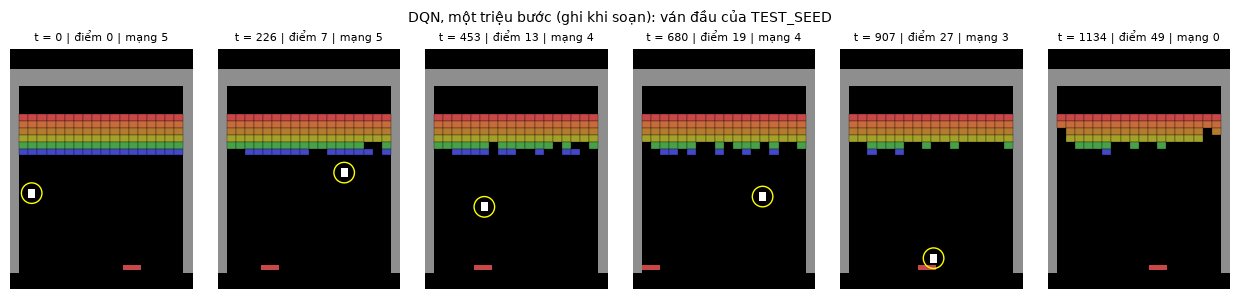

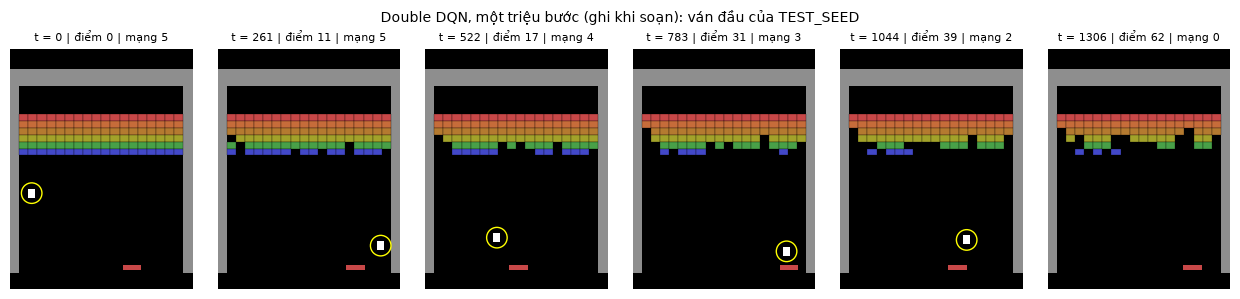

In [15]:
EPISODES = json.loads(r'''{"DQN":{"seed":1,"states":[[99,18,124,5,0],[99,22,128,5,0],[99,26,132,5,0],[87,30,136,5,0],[73,34,140,5,0],[72,38,144,5,0],[72,42,148,5,0],[72,46,152,5,0],[72,50,156,5,0],[72,54,160,5,0],[72,58,164,5,0],[72,62,168,5,0],[72,66,172,5,0],[72,70,176,5,0],[72,74,180,5,0],[72,78,184,5,0],[72,82,183,5,0],[72,86,177,5,0],[72,90,171,5,0],[72,94,165,5,0],[72,98,159,5,0],[72,102,153,5,0],[72,106,147,5,0],[72,110,141,5,0],[72,114,135,5,0],[72,118,129,5,0],[72,122,123,5,0],[72,126,117,5,0],[72,130,111,5,0],[72,134,105,5,0],[72,138,99,5,0],[72,142,93,5,0],[72,146,99,5,1],[64,150,105,5,1],[41,148,111,5,1],[19,144,117,5,1],[8,140,123,5,1],[17,136,129,5,1],[27,132,135,5,1],[39,128,141,5,1],[49,124,147,5,1],[57,120,153,5,1],[79,116,159,5,1],[89,112,165,5,1],[89,108,171,5,1],[89,104,177,5,1],[89,100,183,5,1],[89,100,183,5,1],[89,104,177,5,1],[89,108,171,5,1],[89,112,165,5,1],[89,116,159,5,1],[89,120,153,5,1],[89,124,147,5,1],[89,128,141,5,1],[89,132,135,5,1],[89,136,129,5,1],[89,140,123,5,1],[89,144,117,5,1],[89,148,111,5,1],[89,150,105,5,1],[89,146,99,5,1],[83,142,93,5,1],[61,138,87,5,1],[50,134,93,5,2],[38,130,99,5,2],[23,126,105,5,2],[22,122,111,5,2],[22,118,117,5,2],[22,114,123,5,2],[22,110,129,5,2],[22,106,135,5,2],[29,102,141,5,2],[50,98,147,5,2],[71,94,153,5,2],[73,90,159,5,2],[61,86,165,5,2],[45,82,171,5,2],[51,78,177,5,2],[66,74,183,5,2],[67,70,183,5,2],[67,66,177,5,2],[67,62,171,5,2],[67,58,165,5,2],[67,54,159,5,2],[67,50,153,5,2],[67,46,147,5,2],[67,42,141,5,2],[67,38,135,5,2],[67,34,129,5,2],[67,30,123,5,2],[67,26,117,5,2],[67,22,111,5,2],[67,18,105,5,2],[67,14,99,5,2],[67,10,93,5,2],[75,8,99,5,3],[96,12,105,5,3],[107,16,111,5,3],[95,20,117,5,3],[81,24,123,5,3],[80,28,129,5,3],[80,32,135,5,3],[80,36,141,5,3],[80,40,147,5,3],[67,44,153,5,3],[56,48,159,5,3],[56,52,165,5,3],[56,56,171,5,3],[56,60,177,5,3],[56,64,183,5,3],[56,67,182,5,3],[68,69,174,5,3],[79,71,166,5,3],[79,73,158,5,3],[79,75,150,5,3],[79,77,142,5,3],[90,79,134,5,3],[106,81,126,5,3],[107,83,118,5,3],[95,85,110,5,3],[84,87,102,5,3],[84,89,94,5,3],[84,91,98,5,4],[84,93,106,5,4],[84,95,114,5,4],[84,97,122,5,4],[84,99,130,5,4],[84,101,138,5,4],[84,103,146,5,4],[84,105,154,5,4],[84,107,162,5,4],[84,109,170,5,4],[96,111,178,5,4],[107,113,186,5,4],[107,107,178,5,4],[95,105,170,5,4],[84,103,162,5,4],[84,101,154,5,4],[84,99,146,5,4],[84,97,138,5,4],[84,95,130,5,4],[84,93,122,5,4],[84,91,114,5,4],[84,89,106,5,4],[84,87,98,5,4],[84,85,94,5,5],[84,83,102,5,5],[84,81,110,5,5],[78,79,118,5,5],[55,77,126,5,5],[39,75,134,5,5],[38,73,142,5,5],[50,71,150,5,5],[61,69,158,5,5],[61,67,166,5,5],[61,65,174,5,5],[61,63,182,5,5],[54,59,182,5,5],[33,53,174,5,5],[22,47,166,5,5],[22,41,158,5,5],[22,35,150,5,5],[22,29,142,5,5],[22,23,134,5,5],[22,17,126,5,5],[22,11,118,5,5],[22,8,110,5,5],[22,14,102,5,5],[22,20,94,5,5],[14,26,98,5,6],[8,32,106,5,6],[8,38,114,5,6],[8,44,122,5,6],[8,50,130,5,6],[8,56,138,5,6],[9,62,146,5,6],[28,68,154,5,6],[50,74,162,5,6],[66,80,170,5,6],[67,86,178,5,6],[75,92,186,5,6],[96,98,182,5,6],[94,104,174,5,6],[84,110,166,5,6],[84,116,158,5,6],[84,122,150,5,6],[84,128,142,5,6],[84,134,134,5,6],[96,140,126,5,6],[94,146,118,5,6],[73,152,110,5,6],[49,146,102,5,6],[27,140,94,5,6],[8,134,90,5,7],[8,128,98,5,7],[17,122,106,5,7],[27,116,114,5,7],[34,110,122,5,7],[43,104,130,5,7],[46,98,138,5,7],[68,92,146,5,7],[66,86,154,5,7],[43,80,162,5,7],[45,74,170,5,7],[60,68,178,5,7],[61,62,186,5,7],[49,54,182,5,7],[27,46,178,5,7],[16,38,174,5,7],[16,30,170,5,7],[16,22,166,5,7],[16,14,162,5,7],[16,6,158,5,7],[16,14,154,5,7],[16,22,150,5,7],[16,30,146,5,7],[16,38,142,5,7],[28,46,138,5,7],[37,54,134,5,7],[37,62,130,5,7],[37,70,126,5,7],[37,78,122,5,7],[37,86,118,5,7],[50,94,114,5,7],[48,102,110,5,7],[38,110,106,5,7],[38,118,102,5,7],[27,126,98,5,7],[11,134,94,5,7],[10,142,90,5,7],[10,150,92,5,8],[22,146,96,5,8],[20,138,100,5,8],[8,130,104,5,8],[17,122,108,5,8],[27,114,112,5,8],[39,106,116,5,8],[54,98,120,5,8],[55,90,124,5,8],[55,82,128,5,8],[43,74,132,5,8],[29,66,136,5,8],[28,58,140,5,8],[15,50,144,5,8],[8,42,148,5,8],[8,34,152,5,8],[8,26,156,5,8],[8,18,160,5,8],[8,10,164,5,8],[8,10,168,5,8],[8,18,172,5,8],[17,26,176,5,8],[27,34,180,5,8],[27,42,184,5,8],[34,50,188,5,8],[48,58,186,5,8],[49,66,182,5,8],[49,74,178,5,8],[49,82,174,5,8],[49,90,170,5,8],[49,98,166,5,8],[49,106,162,5,8],[49,114,158,5,8],[49,122,154,5,8],[49,130,150,5,8],[49,138,146,5,8],[49,146,142,5,8],[42,150,138,5,8],[34,142,134,5,8],[21,134,130,5,8],[8,126,126,5,8],[8,118,122,5,8],[8,110,118,5,8],[8,102,114,5,8],[8,94,110,5,8],[17,86,106,5,8],[27,78,102,5,8],[27,70,98,5,8],[27,62,94,5,8],[27,54,96,5,9],[20,46,100,5,9],[23,38,104,5,9],[44,30,108,5,9],[42,22,112,5,9],[34,14,116,5,9],[34,6,120,5,9],[34,14,124,5,9],[34,22,128,5,9],[34,30,132,5,9],[34,38,136,5,9],[34,46,140,5,9],[34,54,144,5,9],[45,62,148,5,9],[55,70,152,5,9],[55,78,156,5,9],[55,86,160,5,9],[55,94,164,5,9],[55,102,168,5,9],[43,110,172,5,9],[27,118,176,5,9],[44,126,180,5,9],[68,134,184,5,9],[90,142,188,5,9],[114,150,192,5,9],[136,146,196,5,9],[144,138,200,5,9],[144,130,204,5,9],[144,122,208,5,9],[144,114,212,5,9],[144,106,216,5,9],[144,73,127,4,9],[143,69,131,4,9],[136,65,135,4,9],[124,61,139,4,9],[101,57,143,4,9],[79,53,147,4,9],[55,49,151,4,9],[44,45,155,4,9],[44,41,159,4,9],[37,37,163,4,9],[15,33,167,4,9],[8,29,171,4,9],[8,25,175,4,9],[8,21,179,4,9],[8,17,183,4,9],[8,17,184,4,9],[8,13,178,4,9],[8,9,172,4,9],[8,9,166,4,9],[8,13,160,4,9],[8,17,154,4,9],[8,21,148,4,9],[8,25,142,4,9],[8,29,136,4,9],[8,33,130,4,9],[8,37,124,4,9],[8,41,118,4,9],[17,45,112,4,9],[27,49,106,4,9],[27,53,100,4,9],[34,57,94,4,9],[43,61,88,4,9],[43,65,91,4,10],[43,69,97,4,10],[43,73,103,4,10],[32,77,109,4,10],[34,81,115,4,10],[43,85,121,4,10],[56,89,127,4,10],[67,93,133,4,10],[67,97,139,4,10],[79,101,145,4,10],[102,105,151,4,10],[100,109,157,4,10],[79,113,163,4,10],[68,117,169,4,10],[79,121,175,4,10],[102,125,181,4,10],[124,129,184,4,10],[133,133,178,4,10],[137,137,172,4,10],[134,141,166,4,10],[124,145,160,4,10],[136,149,154,4,10],[144,149,148,4,10],[144,145,142,4,10],[134,141,136,4,10],[113,137,130,4,10],[89,133,124,4,10],[67,129,118,4,10],[56,125,112,4,10],[56,121,106,4,10],[43,117,100,4,10],[21,113,94,4,10],[8,109,97,4,11],[8,105,103,4,11],[17,101,109,4,11],[27,97,115,4,11],[39,93,121,4,11],[49,89,127,4,11],[49,85,133,4,11],[49,81,139,4,11],[49,77,145,4,11],[49,73,151,4,11],[49,69,157,4,11],[49,65,163,4,11],[49,61,169,4,11],[49,57,175,4,11],[49,53,181,4,11],[38,51,184,4,11],[23,55,178,4,11],[22,59,172,4,11],[22,63,166,4,11],[22,67,160,4,11],[22,71,154,4,11],[22,75,148,4,11],[22,79,142,4,11],[22,83,136,4,11],[22,87,130,4,11],[22,91,124,4,11],[22,95,118,4,11],[33,99,112,4,11],[43,103,106,4,11],[56,107,100,4,11],[67,111,94,4,11],[55,115,88,4,11],[33,119,91,4,12],[22,123,97,4,12],[33,127,103,4,12],[32,131,109,4,12],[34,135,115,4,12],[56,139,121,4,12],[54,143,127,4,12],[57,147,133,4,12],[79,151,139,4,12],[102,147,145,4,12],[113,143,151,4,12],[101,139,157,4,12],[79,135,163,4,12],[70,131,169,4,12],[90,127,175,4,12],[101,123,181,4,12],[114,121,184,4,12],[128,127,176,4,12],[123,133,168,4,12],[114,139,160,4,12],[125,145,152,4,12],[140,151,144,4,12],[129,145,136,4,12],[107,139,128,4,12],[84,133,120,4,12],[61,127,112,4,12],[50,121,104,4,12],[42,115,96,4,12],[21,109,92,4,13],[10,103,100,4,13],[13,97,108,4,13],[21,91,116,4,13],[21,85,124,4,13],[21,79,132,4,13],[21,73,140,4,13],[21,67,148,4,13],[21,61,156,4,13],[21,55,164,4,13],[21,49,172,4,13],[21,43,180,4,13],[33,39,184,4,13],[43,41,176,4,13],[43,43,168,4,13],[43,45,160,4,13],[43,47,152,4,13],[43,49,144,4,13],[43,51,136,4,13],[43,53,128,4,13],[43,55,120,4,13],[43,57,112,4,13],[43,59,104,4,13],[43,61,96,4,13],[43,63,88,4,13],[40,65,92,4,14],[24,67,100,4,14],[22,69,108,4,14],[22,71,116,4,14],[22,73,124,4,14],[22,75,132,4,14],[33,77,140,4,14],[56,79,148,4,14],[67,81,156,4,14],[67,83,164,4,14],[67,85,172,4,14],[79,87,180,4,14],[89,87,184,4,14],[78,81,176,4,14],[68,75,168,4,14],[68,69,160,4,14],[68,63,152,4,14],[68,57,144,4,14],[68,51,136,4,14],[68,45,128,4,14],[68,39,120,4,14],[68,33,112,4,14],[79,27,104,4,14],[89,21,96,4,14],[89,15,88,4,14],[89,9,92,4,15],[89,9,100,4,15],[89,15,108,4,15],[89,21,116,4,15],[89,27,124,4,15],[89,33,132,4,15],[89,39,140,4,15],[89,45,148,4,15],[78,51,156,4,15],[68,57,164,4,15],[68,63,172,4,15],[68,69,180,4,15],[68,69,184,4,15],[68,67,176,4,15],[68,65,168,4,15],[68,63,160,4,15],[68,61,152,4,15],[68,59,144,4,15],[68,57,136,4,15],[68,55,128,4,15],[68,53,120,4,15],[68,51,112,4,15],[68,49,104,4,15],[79,47,96,4,15],[89,45,96,4,16],[78,43,104,4,16],[55,41,112,4,16],[33,39,120,4,16],[22,37,128,4,16],[22,35,136,4,16],[22,33,144,4,16],[22,31,152,4,16],[22,29,160,4,16],[8,27,168,4,16],[8,25,176,4,16],[8,23,184,4,16],[8,29,183,4,16],[17,37,179,4,16],[27,45,175,4,16],[27,53,171,4,16],[27,61,167,4,16],[27,69,163,4,16],[27,77,159,4,16],[27,85,155,4,16],[27,93,151,4,16],[27,101,147,4,16],[27,109,143,4,16],[15,117,139,4,16],[8,125,135,4,16],[17,133,131,4,16],[14,141,127,4,16],[12,149,123,4,16],[33,145,119,4,16],[43,137,115,4,16],[43,129,111,4,16],[43,121,107,4,16],[43,113,103,4,16],[37,105,99,4,16],[15,97,95,4,16],[8,89,91,4,16],[8,81,87,4,16],[8,73,91,4,17],[8,65,95,4,17],[8,57,99,4,17],[8,49,103,4,17],[17,41,107,4,17],[14,33,111,4,17],[8,25,115,4,17],[8,17,119,4,17],[8,9,123,4,17],[8,13,127,4,17],[8,21,131,4,17],[8,29,135,4,17],[8,37,139,4,17],[8,45,143,4,17],[8,53,147,4,17],[17,61,151,4,17],[38,69,155,4,17],[49,77,159,4,17],[49,85,163,4,17],[57,93,167,4,17],[67,101,171,4,17],[75,109,175,4,17],[96,117,179,4,17],[119,125,183,4,17],[129,129,185,4,17],[129,121,181,4,17],[142,113,177,4,17],[144,105,173,4,17],[144,97,169,4,17],[144,89,165,4,17],[143,81,161,4,17],[126,73,157,4,17],[113,65,153,4,17],[102,57,149,4,17],[89,49,145,4,17],[80,41,141,4,17],[80,33,137,4,17],[77,25,133,4,17],[68,17,129,4,17],[68,9,125,4,17],[68,13,121,4,17],[68,21,117,4,17],[68,29,113,4,17],[68,37,109,4,17],[68,45,105,4,17],[68,53,101,4,17],[68,61,97,4,17],[68,69,93,4,17],[68,77,97,4,18],[68,85,101,4,18],[68,93,105,4,18],[75,101,109,4,18],[83,109,113,4,18],[83,117,117,4,18],[83,125,121,4,18],[83,133,125,4,18],[83,141,129,4,18],[83,149,133,4,18],[83,145,137,4,18],[83,137,141,4,18],[83,129,145,4,18],[83,121,149,4,18],[83,113,153,4,18],[83,105,157,4,18],[72,97,161,4,18],[62,89,165,4,18],[62,81,169,4,18],[62,73,173,4,18],[62,65,177,4,18],[74,57,181,4,18],[72,49,185,4,18],[49,41,189,4,18],[27,33,189,4,18],[8,25,185,4,18],[8,17,181,4,18],[8,9,177,4,18],[8,13,173,4,18],[8,21,169,4,18],[8,29,165,4,18],[8,37,161,4,18],[8,45,157,4,18],[8,53,153,4,18],[8,61,149,4,18],[8,69,145,4,18],[8,77,141,4,18],[17,85,137,4,18],[27,93,133,4,18],[15,101,129,4,18],[8,109,125,4,18],[17,117,121,4,18],[38,125,117,4,18],[54,133,113,4,18],[55,141,109,4,18],[43,149,105,4,18],[21,145,101,4,18],[8,137,97,4,18],[8,129,93,4,18],[8,121,97,4,19],[17,113,101,4,19],[14,105,105,4,19],[12,97,109,4,19],[33,89,113,4,19],[43,81,117,4,19],[32,73,121,4,19],[22,65,125,4,19],[29,57,129,4,19],[37,49,133,4,19],[37,41,137,4,19],[37,33,141,4,19],[37,25,145,4,19],[37,17,149,4,19],[37,9,153,4,19],[26,13,157,4,19],[16,21,161,4,19],[16,29,165,4,19],[16,37,169,4,19],[16,45,173,4,19],[28,53,177,4,19],[50,61,181,4,19],[61,69,185,4,19],[61,77,183,4,19],[61,85,179,4,19],[54,93,175,4,19],[33,101,171,4,19],[9,109,167,4,19],[8,117,163,4,19],[17,125,159,4,19],[38,133,155,4,19],[49,141,151,4,19],[62,149,147,4,19],[73,145,143,4,19],[66,137,139,4,19],[43,129,135,4,19],[21,121,131,4,19],[8,113,127,4,19],[12,105,123,4,19],[8,97,119,4,19],[17,89,115,4,19],[38,81,111,4,19],[54,73,107,4,19],[55,65,103,4,19],[68,57,99,4,19],[79,49,95,4,19],[79,41,91,4,19],[79,33,93,4,20],[67,25,97,4,20],[43,17,101,4,20],[29,9,105,4,20],[39,13,109,4,20],[37,21,113,4,20],[28,29,117,4,20],[28,37,121,4,20],[28,45,125,4,20],[28,53,129,4,20],[28,61,133,4,20],[28,69,137,4,20],[34,77,141,4,20],[32,85,145,4,20],[34,93,149,4,20],[56,101,153,4,20],[79,109,157,4,20],[89,117,161,4,20],[89,125,165,4,20],[89,133,169,4,20],[102,141,173,4,20],[113,149,177,4,20],[120,145,181,4,20],[142,137,185,4,20],[139,129,189,4,20],[119,121,190,4,20],[110,113,182,4,20],[119,105,174,4,20],[107,97,166,4,20],[96,89,158,4,20],[96,81,150,4,20],[96,73,142,4,20],[84,65,134,4,20],[61,57,126,4,20],[50,49,118,4,20],[50,41,110,4,20],[50,33,102,4,20],[62,25,94,4,20],[84,17,86,4,20],[95,9,94,4,21],[84,13,102,4,21],[61,21,110,4,21],[50,29,118,4,21],[38,37,126,4,21],[28,45,134,4,21],[28,53,142,4,21],[34,61,150,4,21],[56,69,158,4,21],[67,77,166,4,21],[79,85,174,4,21],[89,93,182,4,21],[89,101,182,4,21],[89,109,174,4,21],[89,117,166,4,21],[78,125,158,4,21],[68,133,150,4,21],[68,141,142,4,21],[55,149,134,4,21],[33,145,126,4,21],[9,137,118,4,21],[8,129,110,4,21],[8,121,102,4,21],[8,113,94,4,21],[8,105,86,4,21],[8,97,94,4,22],[8,89,102,4,22],[8,81,110,4,22],[17,73,118,4,22],[27,65,126,4,22],[27,57,134,4,22],[27,49,142,4,22],[27,41,150,4,22],[27,33,158,4,22],[20,25,166,4,22],[8,17,174,4,22],[8,9,182,4,22],[8,9,182,4,22],[8,17,174,4,22],[8,25,166,4,22],[8,33,158,4,22],[8,41,150,4,22],[8,49,142,4,22],[8,57,134,4,22],[8,65,126,4,22],[8,73,118,4,22],[17,81,110,4,22],[38,89,102,4,22],[62,97,94,4,22],[73,105,98,4,23],[73,113,106,4,23],[73,121,114,4,23],[73,129,122,4,23],[80,137,130,4,23],[89,145,138,4,23],[102,149,146,4,23],[124,141,154,4,23],[123,133,162,4,23],[114,125,170,4,23],[114,117,178,4,23],[101,109,186,4,23],[90,117,178,4,23],[90,125,170,4,23],[90,133,162,4,23],[90,141,154,4,23],[90,149,146,4,23],[90,145,138,4,23],[78,137,130,4,23],[55,129,122,4,23],[33,121,114,4,23],[9,113,106,4,23],[8,105,98,4,23],[8,97,90,4,23],[8,89,90,4,24],[8,81,98,4,24],[8,73,106,4,24],[8,65,114,4,24],[12,57,122,4,24],[21,49,130,4,24],[21,41,138,4,24],[21,33,146,4,24],[14,25,154,4,24],[8,17,162,4,24],[8,9,170,4,24],[8,13,178,4,24],[8,21,186,4,24],[8,29,178,4,24],[8,37,170,4,24],[8,45,162,4,24],[8,53,154,4,24],[8,61,146,4,24],[8,69,138,4,24],[8,77,130,4,24],[8,85,122,4,24],[17,93,114,4,24],[14,101,106,4,24],[8,109,98,4,24],[8,117,90,4,24],[8,125,90,4,25],[8,133,98,4,25],[8,141,106,4,25],[8,149,114,4,25],[8,145,122,4,25],[17,137,130,4,25],[38,129,138,4,25],[62,121,146,4,25],[73,113,154,4,25],[73,105,162,4,25],[73,97,170,4,25],[73,89,178,4,25],[73,81,186,4,25],[73,89,178,4,25],[73,97,170,4,25],[73,105,162,4,25],[73,113,154,4,25],[73,121,146,4,25],[61,129,138,4,25],[38,137,130,4,25],[15,145,122,4,25],[8,149,114,4,25],[8,141,106,4,25],[8,133,98,4,25],[8,125,94,4,26],[8,117,102,4,26],[8,109,110,4,26],[8,101,118,4,26],[12,93,126,4,26],[33,85,134,4,26],[43,77,142,4,26],[32,69,150,4,26],[9,61,158,4,26],[17,53,166,4,26],[27,45,174,4,26],[27,37,182,4,26],[27,33,182,4,26],[27,25,174,4,26],[15,17,166,4,26],[8,9,158,4,26],[8,13,150,4,26],[8,21,142,4,26],[8,29,134,4,26],[17,37,126,4,26],[27,45,118,4,26],[27,53,110,4,26],[20,61,102,4,26],[10,69,94,4,26],[22,77,94,4,27],[44,85,102,4,27],[68,93,110,4,27],[90,101,118,4,27],[114,109,126,4,27],[123,117,134,4,27],[136,125,142,4,27],[144,133,150,4,27],[144,141,158,4,27],[134,149,166,4,27],[137,145,174,4,27],[144,137,182,4,27],[134,129,190,4,27],[137,121,198,4,27],[144,113,206,4,27],[144,105,214,4,27],[124,139,125,3,27],[124,135,129,3,27],[124,131,133,3,27],[122,127,137,3,27],[114,123,141,3,27],[114,119,145,3,27],[114,115,149,3,27],[101,111,153,3,27],[79,107,157,3,27],[68,103,161,3,27],[68,99,165,3,27],[68,95,169,3,27],[68,91,173,3,27],[68,87,177,3,27],[68,83,181,3,27],[68,79,185,3,27],[68,81,181,3,27],[68,85,175,3,27],[68,89,169,3,27],[55,93,163,3,27],[33,97,157,3,27],[22,101,151,3,27],[9,105,145,3,27],[8,109,139,3,27],[8,113,133,3,27],[8,117,127,3,27],[8,121,121,3,27],[8,125,115,3,27],[8,129,109,3,27],[8,133,103,3,27],[8,137,97,3,27],[8,141,91,3,27],[8,145,88,3,28],[8,149,94,3,28],[8,149,100,3,28],[8,145,106,3,28],[8,141,112,3,28],[17,137,118,3,28],[27,133,124,3,28],[27,129,130,3,28],[34,125,136,3,28],[56,121,142,3,28],[67,117,148,3,28],[67,113,154,3,28],[67,109,160,3,28],[79,105,166,3,28],[99,101,172,3,28],[101,97,178,3,28],[89,93,184,3,28],[80,95,181,3,28],[80,99,175,3,28],[67,103,169,3,28],[43,107,163,3,28],[34,111,157,3,28],[34,115,151,3,28],[34,119,145,3,28],[34,123,139,3,28],[21,127,133,3,28],[8,131,127,3,28],[8,135,121,3,28],[8,139,115,3,28],[8,143,109,3,28],[8,147,103,3,28],[8,151,97,3,28],[8,147,91,3,28],[8,143,85,3,28],[8,139,82,3,32],[8,135,88,3,32],[17,131,94,3,32],[38,127,100,3,32],[62,123,106,3,32],[73,119,112,3,32],[85,115,118,3,32],[95,111,124,3,32],[103,107,130,3,32],[113,103,136,3,32],[113,99,142,3,32],[95,95,148,3,32],[73,91,154,3,32],[49,87,160,3,32],[51,83,166,3,32],[61,79,172,3,32],[61,75,178,3,32],[61,71,184,3,32],[61,73,181,3,32],[61,77,175,3,32],[61,81,169,3,32],[61,85,163,3,32],[61,89,157,3,32],[49,93,151,3,32],[27,97,145,3,32],[16,101,139,3,32],[8,105,133,3,32],[8,109,127,3,32],[8,113,121,3,32],[8,117,115,3,32],[8,121,109,3,32],[8,125,103,3,32],[8,129,97,3,32],[8,133,91,3,32],[8,137,85,3,32],[8,141,79,3,32],[8,147,83,3,36],[17,147,96,3,36],[38,139,110,3,36],[37,131,123,3,36],[39,123,137,3,36],[62,115,150,3,36],[84,107,164,3,36],[93,99,177,3,36],[73,95,184,3,36],[75,103,171,3,36],[83,111,157,3,36],[72,119,144,3,36],[62,127,130,3,36],[49,135,117,3,36],[35,143,103,3,36],[34,151,90,3,36],[45,143,83,3,40],[53,135,96,3,40],[46,127,110,3,40],[68,119,123,3,40],[90,111,137,3,40],[101,103,150,3,40],[89,95,164,3,40],[80,87,177,3,40],[80,79,184,3,40],[67,71,171,3,40],[51,63,157,3,40],[62,55,144,3,40],[73,47,130,3,40],[73,39,117,3,40],[73,31,103,3,40],[73,23,96,3,41],[80,15,110,3,41],[78,7,123,3,41],[55,15,137,3,41],[33,23,150,3,41],[9,31,164,3,41],[8,39,177,3,41],[17,47,191,3,41],[32,55,204,3,41],[33,63,218,3,41],[33,22,128,2,41],[33,26,132,2,41],[33,30,136,2,41],[33,34,140,2,41],[33,38,144,2,41],[33,42,148,2,41],[33,46,152,2,41],[33,50,156,2,41],[33,54,160,2,41],[33,58,164,2,41],[33,62,168,2,41],[33,66,172,2,41],[33,70,176,2,41],[44,74,180,2,41],[68,78,184,2,41],[79,78,183,2,41],[72,74,177,2,41],[62,70,171,2,41],[62,66,165,2,41],[62,62,159,2,41],[62,58,153,2,41],[62,54,147,2,41],[62,50,141,2,41],[62,46,135,2,41],[62,42,129,2,41],[62,38,123,2,41],[62,34,117,2,41],[62,30,111,2,41],[62,26,105,2,41],[62,22,99,2,41],[62,18,93,2,41],[62,14,87,2,41],[74,10,81,2,41],[96,8,87,2,45],[107,12,93,2,45],[107,16,99,2,45],[107,20,105,2,45],[107,24,111,2,45],[107,28,117,2,45],[107,32,123,2,45],[107,36,129,2,45],[107,40,135,2,45],[107,44,141,2,45],[107,48,147,2,45],[95,52,153,2,45],[84,56,159,2,45],[84,60,165,2,45],[84,64,171,2,45],[73,68,177,2,45],[49,72,183,2,45],[27,76,189,2,45],[27,80,195,2,45],[27,84,201,2,45],[27,88,207,2,45],[27,92,213,2,45],[27,139,125,1,45],[27,135,129,1,45],[39,131,133,1,45],[49,127,137,1,45],[62,123,141,1,45],[73,119,145,1,45],[73,115,149,1,45],[73,111,153,1,45],[73,107,157,1,45],[73,103,161,1,45],[73,99,165,1,45],[73,95,169,1,45],[73,91,173,1,45],[73,87,177,1,45],[73,83,181,1,45],[73,79,185,1,45],[73,75,182,1,45],[73,71,176,1,45],[73,67,170,1,45],[61,63,164,1,45],[40,59,158,1,45],[38,55,152,1,45],[38,51,146,1,45],[38,47,140,1,45],[38,43,134,1,45],[38,39,128,1,45],[38,35,122,1,45],[38,31,116,1,45],[38,27,110,1,45],[38,23,104,1,45],[38,19,98,1,45],[38,15,92,1,45],[38,11,86,1,45],[38,7,80,1,45],[27,12,79,1,49],[8,20,92,1,49],[8,28,106,1,49],[8,36,119,1,49],[8,44,133,1,49],[12,52,146,1,49],[33,60,160,1,49],[43,68,173,1,49],[56,76,187,1,49],[79,84,200,1,49],[89,92,214,1,49],[89,-1,-1,0,49]],"actions":[0,0,3,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,3,3,3,1,2,1,2,1,2,2,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,3,3,1,3,1,1,1,1,1,1,2,2,1,0,3,1,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,3,2,2,1,3,1,1,1,1,1,3,1,1,1,0,1,1,2,1,1,1,1,2,1,1,3,0,1,1,1,1,1,1,1,1,1,0,1,2,0,1,3,1,1,1,1,1,1,1,1,0,1,0,1,3,3,0,1,2,1,1,1,1,3,3,0,1,1,1,1,1,1,1,1,0,3,1,1,1,1,1,2,2,2,1,1,2,2,3,0,1,1,1,1,2,3,3,3,3,3,3,2,1,2,1,2,2,3,3,2,1,1,3,3,1,1,1,0,1,1,1,1,1,2,1,1,1,1,0,2,3,1,1,3,1,1,1,2,3,3,2,1,2,1,1,1,3,1,1,3,3,1,1,3,3,1,1,2,1,1,2,1,0,0,0,0,0,1,1,1,1,1,1,3,1,3,3,3,3,3,1,2,0,0,1,1,3,2,2,3,1,1,1,0,1,1,1,1,2,1,1,1,1,1,3,2,2,2,2,2,2,2,3,1,1,1,1,3,1,3,3,3,3,0,0,3,3,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,3,2,1,1,2,0,0,1,1,3,2,1,2,1,1,2,2,3,3,1,2,2,2,3,2,3,1,2,1,1,3,3,3,3,1,1,3,3,3,1,2,1,2,1,1,1,1,1,1,0,0,0,0,3,0,1,1,1,1,1,0,1,1,1,1,2,1,2,1,3,3,1,2,3,2,2,3,2,2,2,1,3,3,2,2,1,2,1,3,0,2,1,3,3,3,3,1,3,3,0,2,1,1,1,1,1,1,0,0,1,2,1,1,1,1,1,1,1,1,1,0,1,1,3,1,1,1,1,1,2,2,1,1,1,2,1,3,1,1,1,0,1,1,1,1,2,1,1,0,1,1,1,1,0,0,1,3,1,0,1,1,0,0,0,1,1,1,1,1,1,0,2,1,3,3,3,0,1,1,1,3,3,0,0,0,2,1,1,0,1,1,1,1,1,1,3,1,2,3,2,2,1,1,1,1,3,3,1,0,0,1,1,1,2,3,1,1,1,0,0,1,1,0,1,2,2,0,1,2,1,2,2,2,0,1,2,2,1,3,3,1,3,1,3,1,1,3,1,1,1,1,1,1,1,1,1,1,0,1,1,2,0,0,0,0,0,0,0,0,1,0,0,0,3,0,1,1,0,2,3,3,3,3,0,1,1,1,1,1,1,1,0,1,1,2,1,3,3,2,2,1,1,3,3,3,3,3,2,3,2,2,1,3,1,2,1,1,1,1,1,0,3,0,1,0,0,2,2,0,0,1,3,3,1,0,2,1,1,2,1,3,3,3,3,2,3,2,2,0,0,2,1,0,0,3,3,1,2,3,1,1,0,0,1,0,2,3,2,2,2,1,1,0,2,0,2,2,3,3,2,1,3,1,1,1,3,3,1,0,0,2,2,0,3,3,1,3,0,0,2,2,1,2,0,1,1,1,3,1,1,3,3,3,3,1,0,3,3,1,1,2,1,1,1,1,1,3,3,0,1,1,1,1,1,1,1,1,1,2,2,2,1,1,1,1,2,0,2,2,3,0,1,3,0,1,1,1,1,1,3,3,3,3,1,3,3,1,1,0,2,1,1,1,3,3,3,0,0,0,0,0,0,0,1,1,0,2,3,3,1,1,1,1,3,1,2,2,2,0,0,0,0,0,0,1,1,1,1,3,3,3,1,1,3,3,1,0,1,2,2,1,3,3,2,0,0,0,1,3,0,1,1,1,2,1,0,3,1,2,2,2,2,2,1,2,2,3,3,2,1,3,2,2,3,3,1,1,3,1,0,1,3,3,1,0,0,0,0,0,0,0,0,1,3,3,1,3,1,3,1,3,3,1,1,1,1,3,3,3,3,3,2,1,1,2,2,0,0,0,2,0,1,3,0,1,3,3,1,1,1,1,3,3,3,1,1,1,1,3,3,3,3,2,2,2,1,2,0,2,1,3,3,3,3,2,1,0,0,0,0,1,1,1,3,3,1,3,3,3,3,1,1,1,1,1,1,3,2,3,3,2,2,2,3,3,2,0,3,1,3,1,0,2,3,2,2,2,1,3,1,1,3,0,2,1,1,1,1,2,3,3,3,3,1,2,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,2,2,0,3,0,0,1,1,1,1,1,1,0,1,1,1,1,1,1,2,2,1,1,1,1,1,1,0,0,0,0,3,0,0,0,3,3,2,1,1,1,1,1,1,2,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,1,1,1,1,1,1,0,1,1,1,1,1,1,1,3,3,1,1,3,2,2,1,2,2,1,3],"grids":[[0,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111"],[32,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111101"],[63,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111"],[64,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111101111111111111111101"],[96,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111101011111111111111101"],[123,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111101011111111101111101"],[146,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111101011111111001111101"],[170,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111101001111111001111101"],[194,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111001001111111001111101"],[231,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111001001111111001111100"],[280,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111001001111011001111100"],[343,"111111111111111111111111111111111111111111111111111111111111111111111111111111011111111001001111011001111100"],[375,"111111111111111111111111111111111111111111111111111111111111111111111111111111011111111001001111011001101100"],[406,"111111111111111111111111111111111111111111111111111111111111111111111111111111011111111001001111011001111100"],[407,"111111111111111111111111111111111111111111111111111111111111111111111111111111011111101001001111011001101100"],[435,"111111111111111111111111111111111111111111111111111111111111111111111111111111011111101001001111011001001100"],[460,"111111111111111111111111111111111111111111111111111111111111111111111111111111001111101001001111011001001100"],[485,"111111111111111111111111111111111111111111111111111111111111111111111111011111001111101001001111011001001100"],[509,"111111111111111111111111111111111111111111111111111111111111111111111111011111001111101001001101011001001100"],[546,"111111111111111111111111111111111111111111111111111111111111111111111111011111001011101001001101011001001100"],[594,"111111111111111111111111111111111111111111111111111111111111111111111111011111001011101001001101001001001100"],[643,"111111111111111111111111111111111111111111111111111111111111111111111111011111001011101001001101001001001000"],[690,"111111111111111111111111111111111111111111111111111111111111111111111111011111001011101001001001001001001000"],[729,"111111111111111111111111111111111111111111111111111111111111111111111111001111001011101001001001001001001000"],[754,"111111111111111111111111111111111111111111111111111111111111111111111111001111001011001001001001001001001000"],[778,"111111111111111111111111111111111111111111111111111111111111111111111111001111001011001001001001001000001000"],[802,"111111111111111111111111111111111111111111111111111111111111111111111111001111001001001001001001001000001000"],[827,"111111111111111111111111111111111111111111111111111111111111111111111111001111001001000001001001001000001000"],[851,"111111111111111111111111111111111111111111111111111111111111111111111111001111001001000001001001001000000000"],[875,"111111111111111111111111111111111111111111111111111111111111111111111111001111001001000001001001000000000000"],[923,"111111111111111111111111111111111111111111111111111111111111111111111111001111001001000000001001000000000000"],[957,"111111111111111111111111111111111111111111111111111111111111111111111101001111001001000010001001000000000000"],[958,"111111111111111111111111111111111111111111111111111111111111111111111101001111001001000000001001000000000000"],[993,"111111111111111111111111111111111111111111111111111101111111111111111101001111001001000001001001000000000000"],[994,"111111111111111111111111111111111111111111111111111101111111111111111101001111001001000000001001000000000000"],[1009,"111111111111111111111111111111111111111111111111111101111111111111111100001111001001000000001001000000000000"],[1024,"111111111111111111111111111111111111111111111111111101111111111111111100001111001001000000000001000000000000"],[1066,"111111111111111111111111111111111111111111111111111101111111111111111100101111001001000000000001000000000000"],[1067,"111111111111111111111111111111111111111111111111111101011111111111111100001111001001000000000001000000000000"],[1123,"111111111111111111111111111111111111011111111111111101011111111111111100001111001001000000000001000000000000"]],"score":49.0,"truncated":false},"Double DQN":{"seed":1,"states":[[99,18,124,5,0],[99,22,128,5,0],[99,26,132,5,0],[99,30,136,5,0],[99,34,140,5,0],[99,38,144,5,0],[99,42,148,5,0],[99,46,152,5,0],[99,50,156,5,0],[99,54,160,5,0],[99,58,164,5,0],[87,62,168,5,0],[76,66,172,5,0],[76,70,176,5,0],[76,74,180,5,0],[76,78,184,5,0],[76,78,183,5,0],[76,74,177,5,0],[76,70,171,5,0],[76,66,165,5,0],[76,62,159,5,0],[76,58,153,5,0],[76,54,147,5,0],[79,50,141,5,0],[100,46,135,5,0],[122,42,129,5,0],[144,38,123,5,0],[144,34,117,5,0],[142,30,111,5,0],[129,26,105,5,0],[128,22,99,5,0],[128,18,93,5,0],[128,14,99,5,1],[128,10,105,5,1],[128,8,111,5,1],[128,12,117,5,1],[128,16,123,5,1],[128,20,129,5,1],[128,24,135,5,1],[116,28,141,5,1],[93,32,147,5,1],[77,36,153,5,1],[88,40,159,5,1],[86,44,165,5,1],[76,48,171,5,1],[76,52,177,5,1],[65,56,183,5,1],[41,56,183,5,1],[30,52,177,5,1],[30,48,171,5,1],[42,44,165,5,1],[66,40,159,5,1],[85,36,153,5,1],[80,32,147,5,1],[59,28,141,5,1],[48,24,135,5,1],[48,20,129,5,1],[35,16,123,5,1],[24,12,117,5,1],[24,8,111,5,1],[24,10,105,5,1],[24,14,99,5,1],[24,18,93,5,1],[24,22,87,5,1],[24,26,93,5,2],[24,30,99,5,2],[24,34,105,5,2],[24,38,111,5,2],[24,42,117,5,2],[24,46,123,5,2],[24,50,129,5,2],[24,54,135,5,2],[31,58,141,5,2],[41,62,147,5,2],[41,66,153,5,2],[41,70,159,5,2],[41,74,165,5,2],[41,78,171,5,2],[49,82,177,5,2],[71,86,183,5,2],[81,90,183,5,2],[89,94,177,5,2],[104,98,171,5,2],[93,102,165,5,2],[82,106,159,5,2],[82,110,153,5,2],[82,114,147,5,2],[82,118,141,5,2],[82,122,135,5,2],[82,126,129,5,2],[82,130,123,5,2],[82,134,117,5,2],[82,138,111,5,2],[82,142,105,5,2],[82,146,99,5,2],[82,150,93,5,2],[82,148,99,5,3],[82,144,105,5,3],[82,140,111,5,3],[82,136,117,5,3],[82,132,123,5,3],[82,128,129,5,3],[82,124,135,5,3],[82,120,141,5,3],[82,116,147,5,3],[82,112,153,5,3],[82,108,159,5,3],[82,104,165,5,3],[82,100,171,5,3],[82,96,177,5,3],[82,92,183,5,3],[82,91,182,5,3],[94,93,174,5,3],[105,95,166,5,3],[105,97,158,5,3],[105,99,150,5,3],[105,101,142,5,3],[117,103,134,5,3],[132,105,126,5,3],[133,107,118,5,3],[133,109,110,5,3],[133,111,102,5,3],[144,113,94,5,3],[144,115,98,5,4],[144,117,106,5,4],[144,119,114,5,4],[144,121,122,5,4],[142,123,130,5,4],[121,125,138,5,4],[112,127,146,5,4],[112,129,154,5,4],[112,131,162,5,4],[112,133,170,5,4],[123,135,178,5,4],[133,137,186,5,4],[133,135,178,5,4],[133,133,170,5,4],[133,131,162,5,4],[133,129,154,5,4],[133,127,146,5,4],[133,125,138,5,4],[133,123,130,5,4],[133,121,122,5,4],[133,119,114,5,4],[133,117,106,5,4],[133,115,98,5,4],[144,113,90,5,4],[144,111,90,5,5],[144,109,98,5,5],[144,107,106,5,5],[144,105,114,5,5],[144,103,122,5,5],[144,101,130,5,5],[142,99,138,5,5],[121,97,146,5,5],[99,95,154,5,5],[76,93,162,5,5],[66,91,170,5,5],[72,89,178,5,5],[81,87,186,5,5],[81,89,178,5,5],[81,87,170,5,5],[81,85,162,5,5],[81,83,154,5,5],[81,81,146,5,5],[81,79,138,5,5],[81,77,130,5,5],[81,75,122,5,5],[81,73,114,5,5],[81,71,106,5,5],[81,69,98,5,5],[81,67,94,5,6],[81,65,102,5,6],[81,63,110,5,6],[81,61,118,5,6],[81,59,126,5,6],[81,57,134,5,6],[70,55,142,5,6],[60,53,150,5,6],[60,51,158,5,6],[47,49,166,5,6],[31,47,174,5,6],[42,45,182,5,6],[40,43,190,5,6],[19,41,182,5,6],[20,39,174,5,6],[18,37,166,5,6],[8,35,158,5,6],[8,33,150,5,6],[17,31,142,5,6],[27,29,134,5,6],[27,27,126,5,6],[15,25,118,5,6],[8,23,110,5,6],[8,21,102,5,6],[8,19,94,5,6],[17,17,86,5,6],[27,15,82,5,10],[27,13,90,5,10],[27,11,98,5,10],[27,9,106,5,10],[27,8,114,5,10],[27,10,122,5,10],[27,12,130,5,10],[27,14,138,5,10],[20,16,146,5,10],[8,18,154,5,10],[8,20,162,5,10],[8,22,170,5,10],[8,24,178,5,10],[17,26,186,5,10],[38,34,182,5,10],[37,42,178,5,10],[28,50,174,5,10],[15,58,170,5,10],[8,66,166,5,10],[8,74,162,5,10],[8,82,158,5,10],[8,90,154,5,10],[8,98,150,5,10],[8,106,146,5,10],[8,114,142,5,10],[8,122,138,5,10],[8,130,134,5,10],[8,138,130,5,10],[8,146,126,5,10],[8,150,122,5,10],[8,142,118,5,10],[8,134,114,5,10],[8,126,110,5,10],[8,118,106,5,10],[8,110,102,5,10],[8,102,98,5,10],[17,94,94,5,10],[38,86,96,5,11],[49,78,100,5,11],[49,70,104,5,11],[49,62,108,5,11],[49,54,112,5,11],[49,46,116,5,11],[49,38,120,5,11],[49,30,124,5,11],[49,22,128,5,11],[49,14,132,5,11],[49,6,136,5,11],[38,14,140,5,11],[15,22,144,5,11],[8,30,148,5,11],[8,38,152,5,11],[8,46,156,5,11],[8,54,160,5,11],[8,62,164,5,11],[17,70,168,5,11],[38,78,172,5,11],[49,86,176,5,11],[57,94,180,5,11],[79,102,184,5,11],[102,110,186,5,11],[113,118,182,5,11],[113,126,178,5,11],[113,134,174,5,11],[113,142,170,5,11],[113,150,166,5,11],[113,146,162,5,11],[113,138,158,5,11],[113,130,154,5,11],[113,122,150,5,11],[113,114,146,5,11],[113,106,142,5,11],[113,98,138,5,11],[113,90,134,5,11],[113,82,130,5,11],[113,74,126,5,11],[113,66,122,5,11],[113,58,118,5,11],[101,50,114,5,11],[90,42,110,5,11],[78,34,106,5,11],[68,26,102,5,11],[68,18,98,5,11],[68,10,94,5,11],[68,10,96,5,12],[68,18,100,5,12],[68,26,104,5,12],[68,34,108,5,12],[68,42,112,5,12],[68,50,116,5,12],[68,58,120,5,12],[68,66,124,5,12],[55,74,128,5,12],[38,82,132,5,12],[32,90,136,5,12],[15,98,140,5,12],[33,106,144,5,12],[56,114,148,5,12],[67,122,152,5,12],[67,130,156,5,12],[67,138,160,5,12],[79,146,164,5,12],[78,150,168,5,12],[61,142,172,5,12],[79,134,176,5,12],[102,126,180,5,12],[113,118,184,5,12],[101,110,184,5,12],[90,102,180,5,12],[97,94,176,5,12],[112,86,172,5,12],[101,78,168,5,12],[85,70,164,5,12],[84,62,160,5,12],[84,54,156,5,12],[73,46,152,5,12],[62,38,148,5,12],[62,30,144,5,12],[49,22,140,5,12],[27,14,136,5,12],[8,6,132,5,12],[8,14,128,5,12],[8,22,124,5,12],[8,30,120,5,12],[8,38,116,5,12],[8,46,112,5,12],[8,54,108,5,12],[8,62,104,5,12],[8,70,100,5,12],[8,78,96,5,12],[8,86,94,5,13],[8,94,98,5,13],[8,102,102,5,13],[8,110,106,5,13],[8,118,110,5,13],[8,126,114,5,13],[8,134,118,5,13],[8,142,122,5,13],[8,150,126,5,13],[8,146,130,5,13],[8,138,134,5,13],[8,130,138,5,13],[17,122,142,5,13],[38,114,146,5,13],[62,106,150,5,13],[78,98,154,5,13],[67,90,158,5,13],[46,82,162,5,13],[51,74,166,5,13],[66,66,170,5,13],[67,58,174,5,13],[55,50,178,5,13],[33,42,182,5,13],[22,34,186,5,13],[22,42,182,5,13],[22,50,178,5,13],[29,58,174,5,13],[50,66,170,5,13],[61,74,166,5,13],[61,82,162,5,13],[61,90,158,5,13],[61,98,154,5,13],[61,106,150,5,13],[61,114,146,5,13],[61,122,142,5,13],[49,130,138,5,13],[38,138,134,5,13],[27,146,130,5,13],[16,150,126,5,13],[16,142,122,5,13],[8,134,118,5,13],[8,126,114,5,13],[8,118,110,5,13],[8,110,106,5,13],[8,102,102,5,13],[8,94,98,5,13],[12,86,94,5,13],[33,78,90,5,13],[43,70,94,5,14],[43,62,98,5,14],[43,54,102,5,14],[43,46,106,5,14],[43,38,110,5,14],[32,30,114,5,14],[22,22,118,5,14],[22,14,122,5,14],[22,6,126,5,14],[22,14,130,5,14],[22,22,134,5,14],[22,30,138,5,14],[22,38,142,5,14],[22,46,146,5,14],[22,54,150,5,14],[22,62,154,5,14],[33,70,158,5,14],[56,78,162,5,14],[79,86,166,5,14],[89,94,170,5,14],[89,102,174,5,14],[89,110,178,5,14],[89,118,182,5,14],[102,126,186,5,14],[124,134,187,5,14],[135,142,179,5,14],[135,150,171,5,14],[135,146,163,5,14],[135,138,155,5,14],[124,130,147,5,14],[101,122,139,5,14],[90,114,131,5,14],[90,106,123,5,14],[90,98,115,5,14],[90,90,107,5,14],[90,82,99,5,14],[90,74,91,5,14],[78,66,91,5,15],[68,58,99,5,15],[68,50,107,5,15],[68,42,115,5,15],[55,34,123,5,15],[44,26,131,5,15],[44,18,139,5,15],[32,10,147,5,15],[9,10,155,5,15],[8,18,163,5,15],[8,26,171,5,15],[8,34,179,5,15],[17,42,187,5,15],[38,50,195,5,15],[47,58,203,5,15],[27,66,211,5,15],[16,139,125,4,15],[8,135,129,4,15],[8,131,133,4,15],[17,127,137,4,15],[38,123,141,4,15],[62,119,145,4,15],[78,115,149,4,15],[79,111,153,4,15],[67,107,157,4,15],[49,103,161,4,15],[68,99,165,4,15],[79,95,169,4,15],[79,91,173,4,15],[79,87,177,4,15],[79,83,181,4,15],[79,79,185,4,15],[72,73,183,4,15],[49,67,179,4,15],[27,61,175,4,15],[8,55,171,4,15],[8,49,167,4,15],[8,43,163,4,15],[8,37,159,4,15],[8,31,155,4,15],[8,25,151,4,15],[8,19,147,4,15],[8,13,143,4,15],[8,7,139,4,15],[8,13,135,4,15],[8,19,131,4,15],[8,25,127,4,15],[8,31,123,4,15],[8,37,119,4,15],[8,43,115,4,15],[8,49,111,4,15],[8,55,107,4,15],[8,61,103,4,15],[8,67,99,4,15],[8,73,95,4,15],[8,79,91,4,15],[8,85,87,4,15],[8,91,91,4,16],[8,97,95,4,16],[8,103,99,4,16],[17,109,103,4,16],[27,115,107,4,16],[27,121,111,4,16],[27,127,115,4,16],[27,133,119,4,16],[27,139,123,4,16],[27,145,127,4,16],[27,151,131,4,16],[27,145,135,4,16],[27,139,139,4,16],[27,133,143,4,16],[39,127,147,4,16],[49,121,151,4,16],[49,115,155,4,16],[62,109,159,4,16],[73,103,163,4,16],[73,97,167,4,16],[73,91,171,4,16],[73,85,175,4,16],[73,79,179,4,16],[73,73,183,4,16],[61,68,184,4,16],[38,64,178,4,16],[15,60,172,4,16],[8,56,166,4,16],[8,52,160,4,16],[8,48,154,4,16],[17,44,148,4,16],[38,40,142,4,16],[62,36,136,4,16],[84,32,130,4,16],[102,28,124,4,16],[84,24,118,4,16],[61,20,112,4,16],[50,16,106,4,16],[38,12,100,4,16],[39,8,94,4,16],[62,10,88,4,16],[84,14,91,4,17],[95,18,97,4,17],[95,22,103,4,17],[95,26,109,4,17],[95,30,115,4,17],[95,34,121,4,17],[95,38,127,4,17],[95,42,133,4,17],[84,46,139,4,17],[74,50,145,4,17],[74,54,151,4,17],[74,58,157,4,17],[74,62,163,4,17],[74,66,169,4,17],[74,70,175,4,17],[74,74,181,4,17],[74,76,184,4,17],[74,72,178,4,17],[74,68,172,4,17],[74,64,166,4,17],[74,60,160,4,17],[74,56,154,4,17],[74,52,148,4,17],[85,48,142,4,17],[108,44,136,4,17],[119,40,130,4,17],[112,36,124,4,17],[89,32,118,4,17],[67,28,112,4,17],[46,24,106,4,17],[44,20,100,4,17],[44,16,94,4,17],[44,12,88,4,17],[44,8,82,4,17],[44,10,76,4,17],[37,17,85,4,21],[28,25,98,4,21],[28,33,112,4,21],[28,41,125,4,21],[39,49,139,4,21],[62,57,152,4,21],[60,65,166,4,21],[50,73,179,4,21],[50,81,193,4,21],[50,89,206,4,21],[50,97,220,4,21],[50,22,128,3,21],[50,26,132,3,21],[50,30,136,3,21],[50,34,140,3,21],[50,38,144,3,21],[50,42,148,3,21],[50,46,152,3,21],[50,50,156,3,21],[50,54,160,3,21],[50,58,164,3,21],[50,62,168,3,21],[50,66,172,3,21],[50,70,176,3,21],[62,74,180,3,21],[73,78,184,3,21],[73,82,183,3,21],[73,86,177,3,21],[73,90,171,3,21],[73,94,165,3,21],[73,98,159,3,21],[73,102,153,3,21],[73,106,147,3,21],[73,110,141,3,21],[73,114,135,3,21],[73,118,129,3,21],[73,122,123,3,21],[73,126,117,3,21],[61,130,111,3,21],[50,134,105,3,21],[50,138,99,3,21],[38,142,93,3,21],[23,146,99,3,22],[22,150,105,3,22],[22,148,111,3,22],[22,144,117,3,22],[22,140,123,3,22],[22,136,129,3,22],[22,132,135,3,22],[22,128,141,3,22],[33,124,147,3,22],[56,120,153,3,22],[79,116,159,3,22],[94,112,165,3,22],[95,108,171,3,22],[95,104,177,3,22],[95,100,183,3,22],[95,96,183,3,22],[95,92,177,3,22],[95,88,171,3,22],[95,84,165,3,22],[95,80,159,3,22],[95,76,153,3,22],[95,72,147,3,22],[95,68,141,3,22],[95,64,135,3,22],[95,60,129,3,22],[84,56,123,3,22],[74,52,117,3,22],[61,48,111,3,22],[63,44,105,3,22],[73,40,99,3,22],[73,36,93,3,22],[73,32,99,3,23],[73,28,105,3,23],[73,24,111,3,23],[73,20,117,3,23],[73,16,123,3,23],[73,12,129,3,23],[73,8,135,3,23],[73,10,141,3,23],[66,14,147,3,23],[43,18,153,3,23],[21,22,159,3,23],[8,26,165,3,23],[8,30,171,3,23],[8,34,177,3,23],[17,38,183,3,23],[38,43,184,3,23],[37,49,180,3,23],[28,55,176,3,23],[20,61,172,3,23],[8,67,168,3,23],[8,73,164,3,23],[8,79,160,3,23],[8,85,156,3,23],[8,91,152,3,23],[8,97,148,3,23],[8,103,144,3,23],[8,109,140,3,23],[8,115,136,3,23],[8,121,132,3,23],[8,127,128,3,23],[8,133,124,3,23],[8,139,120,3,23],[8,145,116,3,23],[8,151,112,3,23],[8,145,108,3,23],[8,139,104,3,23],[8,133,100,3,23],[8,127,96,3,23],[8,121,94,3,24],[8,115,98,3,24],[8,109,102,3,24],[8,103,106,3,24],[8,97,110,3,24],[8,91,114,3,24],[8,85,118,3,24],[17,79,122,3,24],[27,73,126,3,24],[34,67,130,3,24],[53,61,134,3,24],[55,55,138,3,24],[43,49,142,3,24],[21,43,146,3,24],[8,37,150,3,24],[8,31,154,3,24],[8,25,158,3,24],[8,19,162,3,24],[8,13,166,3,24],[8,7,170,3,24],[8,13,174,3,24],[8,19,178,3,24],[8,25,182,3,24],[17,31,186,3,24],[25,37,178,3,24],[29,43,170,3,24],[50,49,162,3,24],[61,55,154,3,24],[61,61,146,3,24],[74,67,138,3,24],[83,73,130,3,24],[83,79,122,3,24],[83,85,114,3,24],[83,91,106,3,24],[83,97,98,3,24],[72,103,94,3,25],[57,109,102,3,25],[56,115,110,3,25],[56,121,118,3,25],[68,127,126,3,25],[90,133,134,3,25],[106,139,142,3,25],[107,145,150,3,25],[107,151,158,3,25],[107,145,166,3,25],[115,139,174,3,25],[123,133,182,3,25],[123,131,182,3,25],[123,133,174,3,25],[123,135,166,3,25],[123,137,158,3,25],[123,139,150,3,25],[123,141,142,3,25],[123,143,134,3,25],[123,145,126,3,25],[123,147,118,3,25],[123,149,110,3,25],[123,151,102,3,25],[123,149,94,3,25],[123,147,86,3,25],[123,145,94,3,26],[123,143,102,3,26],[123,141,110,3,26],[123,139,118,3,26],[123,137,126,3,26],[112,135,134,3,26],[89,133,142,3,26],[91,131,150,3,26],[101,129,158,3,26],[101,127,166,3,26],[101,125,174,3,26],[101,123,182,3,26],[114,123,186,3,26],[123,129,178,3,26],[123,135,170,3,26],[123,141,162,3,26],[123,147,154,3,26],[123,150,146,3,26],[123,144,138,3,26],[123,138,130,3,26],[123,132,122,3,26],[123,126,114,3,26],[123,120,106,3,26],[123,114,98,3,26],[123,108,94,3,27],[123,102,102,3,27],[112,96,110,3,27],[102,90,118,3,27],[102,84,126,3,27],[89,78,134,3,27],[67,72,142,3,27],[58,66,150,3,27],[67,60,158,3,27],[67,54,166,3,27],[55,48,174,3,27],[33,42,182,3,27],[22,42,182,3,27],[29,48,174,3,27],[26,54,166,3,27],[18,60,158,3,27],[38,66,150,3,27],[62,72,142,3,27],[84,78,134,3,27],[100,84,126,3,27],[101,90,118,3,27],[101,96,110,3,27],[101,102,102,3,27],[101,108,94,3,27],[101,114,86,3,27],[101,120,82,3,31],[101,126,90,3,31],[101,132,98,3,31],[101,138,106,3,31],[101,144,114,3,31],[101,150,122,3,31],[101,147,130,3,31],[101,141,138,3,31],[101,135,146,3,31],[89,129,154,3,31],[80,123,162,3,31],[91,117,170,3,31],[101,111,178,3,31],[89,105,186,3,31],[91,102,191,3,31],[114,110,187,3,31],[128,118,183,3,31],[129,126,179,3,31],[129,134,175,3,31],[129,142,171,3,31],[129,150,167,3,31],[129,146,163,3,31],[129,138,159,3,31],[129,130,155,3,31],[129,122,151,3,31],[129,114,147,3,31],[129,106,143,3,31],[129,98,139,3,31],[129,90,135,3,31],[129,82,131,3,31],[129,74,127,3,31],[129,66,123,3,31],[118,58,119,3,31],[108,50,115,3,31],[100,42,111,3,31],[85,34,107,3,31],[84,26,103,3,31],[84,18,99,3,31],[84,10,95,3,31],[84,10,91,3,31],[84,18,87,3,31],[84,26,85,3,32],[84,34,89,3,32],[73,42,93,3,32],[49,50,97,3,32],[38,58,101,3,32],[38,66,105,3,32],[27,74,109,3,32],[16,82,113,3,32],[16,90,117,3,32],[28,98,121,3,32],[50,106,125,3,32],[74,114,129,3,32],[88,122,133,3,32],[89,130,137,3,32],[89,138,141,3,32],[89,146,145,3,32],[89,150,149,3,32],[89,142,153,3,32],[89,134,157,3,32],[89,126,161,3,32],[89,118,165,3,32],[89,110,169,3,32],[89,102,173,3,32],[89,94,177,3,32],[89,86,181,3,32],[78,78,185,3,32],[55,70,183,3,32],[33,62,179,3,32],[9,54,175,3,32],[8,46,171,3,32],[8,38,167,3,32],[8,30,163,3,32],[8,22,159,3,32],[8,14,155,3,32],[8,6,151,3,32],[8,14,147,3,32],[8,22,143,3,32],[8,30,139,3,32],[8,38,135,3,32],[8,46,131,3,32],[8,54,127,3,32],[8,62,123,3,32],[8,70,119,3,32],[8,78,115,3,32],[8,86,111,3,32],[8,94,107,3,32],[8,102,103,3,32],[8,110,99,3,32],[8,118,95,3,32],[8,126,91,3,32],[8,134,93,3,33],[8,142,97,3,33],[8,150,101,3,33],[8,146,105,3,33],[8,138,109,3,33],[8,130,113,3,33],[8,122,117,3,33],[8,114,121,3,33],[8,106,125,3,33],[8,98,129,3,33],[8,90,133,3,33],[8,82,137,3,33],[17,74,141,3,33],[38,66,145,3,33],[37,58,149,3,33],[23,50,153,3,33],[14,42,157,3,33],[8,34,161,3,33],[8,26,165,3,33],[12,18,169,3,33],[8,10,173,3,33],[8,10,177,3,33],[8,18,181,3,33],[8,26,185,3,33],[17,34,189,3,33],[14,42,187,3,33],[8,50,183,3,33],[8,58,179,3,33],[8,66,175,3,33],[8,74,171,3,33],[8,82,167,3,33],[8,90,163,3,33],[8,98,159,3,33],[8,106,155,3,33],[8,114,151,3,33],[8,122,147,3,33],[8,130,143,3,33],[8,138,139,3,33],[8,146,135,3,33],[8,150,131,3,33],[8,142,127,3,33],[8,134,123,3,33],[8,126,119,3,33],[8,118,115,3,33],[8,110,111,3,33],[8,102,107,3,33],[8,94,103,3,33],[8,86,99,3,33],[8,78,95,3,33],[8,70,91,3,33],[8,62,87,3,33],[8,54,91,3,34],[8,46,95,3,34],[8,38,99,3,34],[8,30,103,3,34],[8,22,107,3,34],[8,14,111,3,34],[8,6,115,3,34],[8,14,119,3,34],[8,22,123,3,34],[8,30,127,3,34],[8,38,131,3,34],[8,46,135,3,34],[8,54,139,3,34],[8,62,143,3,34],[8,70,147,3,34],[12,78,151,3,34],[33,86,155,3,34],[56,94,159,3,34],[79,102,163,3,34],[102,110,167,3,34],[100,118,171,3,34],[103,126,175,3,34],[124,134,179,3,34],[135,142,183,3,34],[128,150,187,3,34],[120,146,191,3,34],[120,138,195,3,34],[120,130,199,3,34],[120,122,203,3,34],[131,114,207,3,34],[144,106,211,3,34],[139,98,215,3,34],[108,139,125,2,34],[95,135,129,2,34],[84,131,133,2,34],[84,127,137,2,34],[84,123,141,2,34],[84,119,145,2,34],[84,115,149,2,34],[84,111,153,2,34],[73,107,157,2,34],[55,103,161,2,34],[74,99,165,2,34],[83,95,169,2,34],[83,91,173,2,34],[83,87,177,2,34],[83,83,181,2,34],[72,79,185,2,34],[62,83,183,2,34],[74,89,179,2,34],[83,95,175,2,34],[83,101,171,2,34],[83,107,167,2,34],[83,113,163,2,34],[83,119,159,2,34],[96,125,155,2,34],[107,131,151,2,34],[107,137,147,2,34],[119,143,143,2,34],[142,149,139,2,34],[144,149,135,2,34],[144,143,131,2,34],[144,137,127,2,34],[144,131,123,2,34],[144,125,119,2,34],[144,119,115,2,34],[144,113,111,2,34],[144,107,107,2,34],[144,101,103,2,34],[144,95,99,2,34],[144,89,95,2,34],[144,83,91,2,34],[134,77,87,2,34],[113,71,91,2,35],[89,65,95,2,35],[67,59,99,2,35],[69,53,103,2,35],[66,47,107,2,35],[43,41,111,2,35],[29,35,115,2,35],[28,29,119,2,35],[28,23,123,2,35],[28,17,127,2,35],[15,11,131,2,35],[8,8,135,2,35],[8,14,139,2,35],[8,20,143,2,35],[8,26,147,2,35],[8,32,151,2,35],[8,38,155,2,35],[8,44,159,2,35],[8,50,163,2,35],[12,56,167,2,35],[33,62,171,2,35],[56,68,175,2,35],[67,74,179,2,35],[67,80,183,2,35],[79,85,184,2,35],[89,89,178,2,35],[89,93,172,2,35],[89,97,166,2,35],[89,101,160,2,35],[89,105,154,2,35],[89,109,148,2,35],[89,113,142,2,35],[89,117,136,2,35],[89,121,130,2,35],[89,125,124,2,35],[89,129,118,2,35],[89,133,112,2,35],[89,137,106,2,35],[89,141,100,2,35],[89,145,94,2,35],[102,149,88,2,35],[113,149,82,2,35],[113,145,85,2,39],[120,141,91,2,39],[134,137,97,2,39],[135,133,103,2,39],[135,129,109,2,39],[135,125,115,2,39],[135,121,121,2,39],[135,117,127,2,39],[124,113,133,2,39],[101,109,139,2,39],[79,105,145,2,39],[68,101,151,2,39],[68,97,157,2,39],[68,93,163,2,39],[79,89,169,2,39],[89,85,175,2,39],[83,81,181,2,39],[61,80,185,2,39],[63,86,181,2,39],[84,92,177,2,39],[95,98,173,2,39],[95,104,169,2,39],[95,110,165,2,39],[95,116,161,2,39],[95,122,157,2,39],[95,128,153,2,39],[95,134,149,2,39],[95,140,145,2,39],[95,146,141,2,39],[95,152,137,2,39],[95,146,133,2,39],[95,140,129,2,39],[95,134,125,2,39],[95,128,121,2,39],[95,122,117,2,39],[95,116,113,2,39],[95,110,109,2,39],[95,104,105,2,39],[95,98,101,2,39],[95,92,97,2,39],[95,86,93,2,39],[95,80,89,2,39],[95,74,85,2,39],[84,68,81,2,39],[61,62,85,2,43],[38,56,89,2,43],[15,50,93,2,43],[8,44,97,2,43],[8,38,101,2,43],[8,32,105,2,43],[8,26,109,2,43],[8,20,113,2,43],[8,14,117,2,43],[8,8,121,2,43],[8,11,125,2,43],[8,17,129,2,43],[8,23,133,2,43],[8,29,137,2,43],[8,35,141,2,43],[8,41,145,2,43],[8,47,149,2,43],[8,53,153,2,43],[8,59,157,2,43],[17,65,161,2,43],[38,71,165,2,43],[62,77,169,2,43],[73,83,173,2,43],[73,89,177,2,43],[85,95,181,2,43],[95,101,185,2,43],[95,104,180,2,43],[95,106,172,2,43],[95,108,164,2,43],[95,110,156,2,43],[108,112,148,2,43],[122,114,140,2,43],[123,116,132,2,43],[123,118,124,2,43],[123,120,116,2,43],[123,122,108,2,43],[117,124,100,2,43],[95,126,92,2,43],[97,128,88,2,44],[119,130,96,2,44],[129,132,104,2,44],[129,134,112,2,44],[129,136,120,2,44],[129,138,128,2,44],[126,140,136,2,44],[120,142,144,2,44],[120,144,152,2,44],[120,146,160,2,44],[120,148,168,2,44],[131,150,176,2,44],[144,150,184,2,44],[144,148,180,2,44],[129,146,172,2,44],[120,144,164,2,44],[120,142,156,2,44],[120,140,148,2,44],[120,138,140,2,44],[120,136,132,2,44],[120,134,124,2,44],[120,132,116,2,44],[120,130,108,2,44],[120,128,100,2,44],[120,126,92,2,44],[126,124,84,2,44],[144,122,84,2,48],[144,120,92,2,48],[144,118,100,2,48],[144,116,108,2,48],[144,114,116,2,48],[144,112,124,2,48],[144,110,132,2,48],[140,108,140,2,48],[119,106,148,2,48],[97,104,156,2,48],[86,102,164,2,48],[86,100,172,2,48],[86,98,180,2,48],[86,97,184,2,48],[93,99,176,2,48],[106,101,168,2,48],[107,103,160,2,48],[107,105,152,2,48],[96,107,144,2,48],[86,109,136,2,48],[73,111,128,2,48],[51,113,120,2,48],[40,115,112,2,48],[40,117,104,2,48],[40,119,96,2,48],[47,121,88,2,48],[68,123,80,2,48],[92,126,77,2,52],[103,134,91,2,52],[103,142,104,2,52],[103,150,118,2,52],[96,146,131,2,52],[73,138,145,2,52],[75,130,158,2,52],[98,122,172,2,52],[107,114,185,2,52],[101,106,178,2,52],[79,98,165,2,52],[68,90,151,2,52],[68,82,138,2,52],[68,74,124,2,52],[68,66,111,2,52],[68,58,97,2,52],[68,50,97,2,53],[68,42,111,2,53],[68,34,124,2,53],[68,26,138,2,53],[68,18,151,2,53],[56,10,165,2,53],[33,10,178,2,53],[10,14,185,2,53],[8,6,172,2,53],[8,14,158,2,53],[8,22,145,2,53],[8,30,131,2,53],[8,38,118,2,53],[8,46,104,2,53],[8,54,91,2,53],[8,62,84,2,57],[8,70,97,2,57],[8,78,111,2,57],[8,86,124,2,57],[17,94,138,2,57],[38,102,151,2,57],[62,110,165,2,57],[84,118,178,2,57],[105,126,192,2,57],[107,134,205,2,57],[119,142,219,2,57],[129,22,128,1,57],[118,26,132,1,57],[95,30,136,1,57],[97,34,140,1,57],[107,38,144,1,57],[95,42,148,1,57],[84,46,152,1,57],[96,50,156,1,57],[107,54,160,1,57],[100,58,164,1,57],[79,62,168,1,57],[63,66,172,1,57],[62,70,176,1,57],[62,74,180,1,57],[74,78,184,1,57],[83,77,184,1,57],[81,71,180,1,57],[61,65,176,1,57],[63,59,172,1,57],[84,53,168,1,57],[93,47,164,1,57],[84,41,160,1,57],[96,35,156,1,57],[107,29,152,1,57],[107,23,148,1,57],[107,17,144,1,57],[95,11,140,1,57],[84,8,136,1,57],[84,14,132,1,57],[78,20,128,1,57],[68,26,124,1,57],[68,32,120,1,57],[68,38,116,1,57],[68,44,112,1,57],[68,50,108,1,57],[68,56,104,1,57],[68,62,100,1,57],[68,68,96,1,57],[68,74,92,1,57],[68,80,88,1,57],[68,86,84,1,57],[60,92,86,1,58],[63,98,90,1,58],[73,104,94,1,58],[61,110,98,1,58],[38,116,102,1,58],[15,122,106,1,58],[17,128,110,1,58],[14,134,114,1,58],[8,140,118,1,58],[17,146,122,1,58],[14,149,126,1,58],[8,143,130,1,58],[8,137,134,1,58],[8,131,138,1,58],[17,125,142,1,58],[38,119,146,1,58],[62,113,150,1,58],[81,107,154,1,58],[72,101,158,1,58],[62,95,162,1,58],[62,89,166,1,58],[62,83,170,1,58],[62,77,174,1,58],[62,71,178,1,58],[62,65,182,1,58],[54,59,186,1,58],[33,55,180,1,58],[9,51,174,1,58],[8,47,168,1,58],[8,43,162,1,58],[8,39,156,1,58],[8,35,150,1,58],[8,31,144,1,58],[8,27,138,1,58],[8,23,132,1,58],[8,19,126,1,58],[8,15,120,1,58],[8,11,114,1,58],[8,7,108,1,58],[8,11,102,1,58],[8,15,96,1,58],[8,19,90,1,58],[8,23,84,1,58],[8,27,84,1,62],[8,31,90,1,62],[8,35,96,1,62],[8,39,102,1,62],[8,43,108,1,62],[8,47,114,1,62],[8,51,120,1,62],[17,55,126,1,62],[38,59,132,1,62],[62,63,138,1,62],[73,67,144,1,62],[73,71,150,1,62],[73,75,156,1,62],[73,79,162,1,62],[73,83,168,1,62],[73,87,174,1,62],[85,91,180,1,62],[108,95,186,1,62],[106,99,192,1,62],[109,103,198,1,62],[119,107,204,1,62],[119,111,210,1,62],[119,115,216,1,62],[119,-1,-1,0,62]],"actions":[0,0,1,1,0,1,1,0,0,0,3,0,1,1,1,1,1,1,1,1,1,1,2,2,2,2,0,3,1,1,0,0,1,1,1,1,1,1,3,3,0,2,3,0,0,3,3,1,0,2,2,0,3,3,1,0,3,1,1,1,1,1,0,1,1,1,1,1,1,1,1,2,1,1,1,0,0,2,2,0,2,1,3,1,1,0,1,1,1,1,1,1,1,1,1,0,1,0,0,1,1,1,0,0,0,0,1,1,1,1,0,2,1,1,1,0,2,0,2,1,0,2,2,1,1,3,3,3,1,1,1,1,2,1,1,1,1,1,1,1,1,1,1,0,1,2,0,1,1,1,1,1,3,3,3,3,1,2,1,0,1,1,0,1,1,1,1,1,0,1,0,0,0,0,1,1,3,0,1,3,0,2,3,3,2,3,3,3,2,1,1,3,1,1,0,2,0,0,1,1,1,1,1,1,3,3,3,3,0,2,2,3,1,3,1,3,1,1,0,0,0,3,3,3,1,1,1,1,1,1,1,1,2,2,1,1,1,1,1,1,1,1,1,1,3,3,0,3,3,1,0,2,2,1,2,2,2,0,1,1,1,1,0,0,0,0,0,1,1,1,0,1,0,0,3,1,3,0,0,0,1,1,1,1,1,1,1,1,3,2,3,2,2,2,1,1,1,2,3,2,2,2,1,3,0,2,0,3,0,1,1,3,0,1,3,3,3,3,3,1,1,1,1,1,0,0,0,1,1,1,1,1,1,1,1,1,3,3,2,2,2,1,3,1,2,0,0,3,3,1,1,3,2,2,1,1,1,1,0,0,1,3,1,3,0,1,3,3,1,1,1,1,2,2,0,1,1,1,1,3,1,1,1,1,1,1,0,1,0,0,2,2,2,1,1,1,0,2,2,1,1,1,0,3,3,1,1,0,1,1,1,3,1,1,1,3,1,1,3,3,3,3,1,2,2,3,3,1,3,1,2,2,2,0,0,3,2,2,1,1,1,1,1,3,3,3,3,3,3,3,3,3,3,3,3,3,3,1,1,1,1,1,1,1,0,1,1,1,1,1,1,2,1,1,1,1,0,1,1,1,1,0,2,0,0,2,1,0,1,0,1,1,3,3,3,3,3,3,2,2,2,2,3,3,3,1,3,2,2,2,0,1,1,1,1,1,1,3,1,1,1,1,0,0,1,1,1,1,1,1,1,1,2,2,1,3,3,3,1,1,1,1,1,1,3,1,1,1,2,2,3,1,1,1,1,1,1,1,0,1,1,1,1,0,0,0,1,0,2,1,1,1,1,1,1,1,0,0,0,1,0,0,3,1,0,3,0,1,1,1,1,1,1,1,2,2,2,0,0,1,1,1,1,1,1,1,1,1,1,1,1,3,1,3,2,1,1,1,1,1,1,1,1,1,1,3,3,3,3,3,3,2,2,3,1,3,3,3,1,1,1,0,0,0,3,3,1,1,1,1,0,0,0,0,0,0,1,3,1,1,1,1,2,1,2,0,1,3,3,3,3,3,1,1,3,3,1,1,2,3,2,2,1,1,2,1,1,1,1,1,3,1,1,1,2,2,1,0,1,1,2,1,1,1,0,1,1,1,0,0,0,0,0,0,0,1,1,1,1,1,3,3,2,1,1,1,1,2,1,1,1,1,0,0,0,0,0,0,0,0,1,3,1,1,3,3,2,1,1,3,3,0,2,3,2,2,2,2,1,1,1,1,0,0,1,1,1,1,1,1,1,1,0,3,1,2,1,3,2,2,1,1,1,0,1,0,0,0,1,0,1,0,1,0,1,1,3,1,3,1,1,1,1,1,0,1,1,3,3,1,1,3,1,1,2,2,2,0,1,1,1,0,1,1,1,1,0,0,1,1,3,3,3,3,3,3,3,3,3,1,1,1,1,1,3,1,0,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,3,3,0,0,2,2,3,1,3,3,3,2,3,3,3,3,2,3,3,3,1,3,3,1,1,1,1,1,3,1,3,1,1,1,1,1,1,1,1,1,0,0,1,1,0,3,1,1,1,3,3,1,1,3,3,3,3,1,2,2,2,2,2,3,2,2,1,3,1,1,1,1,2,1,3,3,3,1,0,0,0,0,0,3,2,2,0,1,1,1,3,1,2,0,0,0,0,0,2,1,1,2,0,0,0,0,0,0,0,0,0,0,0,0,0,3,3,3,3,2,3,3,1,1,1,1,3,1,3,3,2,3,3,3,3,2,2,2,1,1,2,0,0,0,1,1,1,1,0,0,1,1,1,1,1,0,2,0,0,2,1,1,1,1,1,1,3,3,3,0,0,0,2,1,3,3,2,2,0,0,0,1,0,1,1,1,1,0,0,0,0,1,1,1,1,1,1,0,0,1,0,3,3,3,3,1,1,1,1,3,1,1,1,1,1,1,1,0,3,3,0,2,2,2,1,1,2,0,0,0,0,1,2,1,0,1,1,1,3,3,2,2,1,1,1,1,3,1,1,1,1,2,2,3,3,0,0,0,0,0,0,0,0,1,0,2,2,1,1,2,2,3,3,3,3,3,1,1,1,1,2,0,0,1,3,0,3,3,1,1,1,2,2,2,1,1,1,3,3,2,2,1,3,3,0,1,1,1,0,0,0,0,0,1,3,3,3,3,3,1,3,1,1,1,0,1,3,3,2,2,2,2,1,1,2,1,3,3,2,1,3,1,2,0,3,3,0,0,0,2,1,3,3,2,2,3,0,2,1,1,1,3,0,0,3,0,1,1,1,0,0,0,0,0,1,1,3,2,0,3,3,3,2,3,3,2,3,3,3,3,2,2,2,1,3,1,1,1,0,0,0,3,3,3,3,3,3,1,1,1,1,1,1,1,1,1,1,3,3,3,1,3,3,3,3,3,2,2,2,1,1,1,1,1,0,2,2,3,2,1,1,1,1],"grids":[[0,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111"],[32,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111101111111111111111"],[64,"111111111111111111111111111111111111111111111111111111111111111111111111101111111111111111101111111111111111"],[96,"111111111111111111111111111111111111111111111111111111111111111111111111101111111111111111101111111111111110"],[123,"111111111111111111111111111111111111111111111111111111111111111111111111101111111111111111101111111111101110"],[147,"111111111111111111111111111111111111111111111111111111111111111111111111101111111111101111101111111111101110"],[171,"111111111111111111111111111111111111111111111111111111111111111111111111101111111111101111101111101111101110"],[197,"111111111111111111111111111111111111111111111111111111011111111111111111101111111111101111101111101111101110"],[234,"111111111111111111111111111111111111111111111111111111011111111111111111101111111111101111101111101101101110"],[281,"111111111111111111111111111111111111111111111111111111011111111111111111101111111111101111001111101101101110"],[327,"111111111111111111111111111111111111111111111111111111011111111111111111101111111111101111001111101001101110"],[375,"111111111111111111111111111111111111111111111111111111011111111111111111101111111111101111001111100001101110"],[412,"111111111111111111111111111111111111111111111111111111011111111111111111101111101111101111001111100001101110"],[469,"111111111111111111111111111111111111111111111111111111011111111111111111101111101011101111001111100001101110"],[509,"111111111111111111111111111111111111111111111111111111011111111111111111101111101011101111101111100001101110"],[510,"111111111111111111111111111111111111111111111111111111011111111111111111001111101011101111001111100001101110"],[544,"111111111111111111111111111111111111111111111111111111111111111111111111001111101011101111001111100001101110"],[545,"111111111111111111111111111111111111011111111111111111011111111111111111001111101011101111001111100001101110"],[587,"111111111111111111111111111111111111011111111111111111011111111111111111001111101011101111001111100001101100"],[618,"111111111111111111111111111111111111011111111111111111011111111111111111001111101011101111001011100001101100"],[656,"111111111111111111111111111111111111011111111111111111011111111111111111001111101011101111001011100001100100"],[691,"111111111111111111111111111111111111011111111111111111011111111111111111001111101011101111001011100000100100"],[716,"111111111111111111111111111111111111011111111111111111011111111111111111001111101011101110001011100000100100"],[740,"111111111111111111111111111111111111011111111111111111011111111111111111001111101011101110001011100000000100"],[765,"111111111111111111111111111111111111011111111111111111011111111111101111001111101011101110001011100000000100"],[805,"111111111111111111111111111111111111011111111111111111011111111111101111001111101011101110011011100000000100"],[806,"111111111111111111111111111111111111011111111111111111011111111111101111000111101011101110001011100000000100"],[807,"111111111111111111111111111111111111011111111111111111011111111111101111000111101011101110001111100000000100"],[808,"111111111111111111111111111111111111011111111111111111011111111111101111000111101011101110001011100000000100"],[856,"111111111111111111111111111111111111011111111111111111011111111111101111000111101011101110001011100000000000"],[907,"111111111111111111111111111111111111011111111111111111011111111111101111000111001011101110001011100000000000"],[980,"111111111111111111111111111111111111011111111111111111011111111111101111000111000011101110001011100000000000"],[1022,"111111111111111111111111111111111111011111111111111111011111111111101110000111000011101110001011100000000000"],[1066,"111111111111111111111111111111111111011111111111111111011111101111101110000111000011101110001011100000000000"],[1104,"111111111111111111111111111111111111011111111111111111011111101111101110000111000011100110001011100000000000"],[1130,"111111111111111111111111111111111111011111111111111111011111101111100110000111000011101110001011100000000000"],[1131,"111111111111111111111111111111111111011111111111111111011111101111100110000111000011100110001011100000000000"],[1157,"111111111111111111111111111111111111011111111111110111011111101111100110000111000011100110001011100000000000"],[1173,"111111111111111111111111111111111111011111111111110111011111101111100110000111000011100110001010100000000000"],[1188,"111111111111111111111111111111111111011111111111110111011111001111100110000111000011100110001010100000000000"],[1240,"111111111111111111111111111111111111011111111111110111011111001111100110000111000001100110001010100000000000"],[1241,"111111111111111111111111111111111111011111111111110111011111001111100110000111000001100110001010100001000000"],[1242,"111111111111111111111111111111111111011111111111110111011111001111100110000111000001100110001010100000000000"],[1281,"111111111111111111111111111111111111011111111111110111011111001111100110000111000001100110011010100000000000"],[1282,"111111111111111111111111111111111111011111111111110111011111001111100110000111000001100110001010100000000000"],[1283,"111111111111111111111111111111111111011111111111110111010111001111100110001111000001100110001010100000000000"],[1284,"111111111111111111111111111111111111011111111111110111010111001111100110000111000001100110001010100000000000"]],"score":62.0,"truncated":false},"REINFORCE":{"run":"lr1e-5_norm","game_seed":30006,"states":[[99,83,125,5,0],[99,87,129,5,0],[111,91,133,5,0],[134,95,137,5,0],[143,99,141,5,0],[144,103,145,5,0],[144,107,149,5,0],[144,111,153,5,0],[144,115,157,5,0],[144,119,161,5,0],[144,123,165,5,0],[144,127,169,5,0],[144,131,173,5,0],[144,135,177,5,0],[144,139,181,5,0],[144,143,185,5,0],[144,139,183,5,0],[144,133,179,5,0],[144,127,175,5,0],[144,121,171,5,0],[144,115,167,5,0],[144,109,163,5,0],[144,103,159,5,0],[144,97,155,5,0],[144,91,151,5,0],[144,85,147,5,0],[144,79,143,5,0],[144,73,139,5,0],[144,67,135,5,0],[144,61,131,5,0],[144,55,127,5,0],[144,49,123,5,0],[144,43,119,5,0],[144,37,115,5,0],[144,31,111,5,0],[144,25,107,5,0],[144,19,103,5,0],[144,13,99,5,0],[144,7,95,5,0],[144,13,95,5,1],[144,19,99,5,1],[144,25,103,5,1],[144,31,107,5,1],[144,37,111,5,1],[144,43,115,5,1],[144,49,119,5,1],[144,55,123,5,1],[144,61,127,5,1],[144,67,131,5,1],[144,73,135,5,1],[144,79,139,5,1],[144,85,143,5,1],[144,91,147,5,1],[144,97,151,5,1],[144,103,155,5,1],[144,109,159,5,1],[144,115,163,5,1],[144,121,167,5,1],[144,127,171,5,1],[144,133,175,5,1],[144,139,179,5,1],[144,145,183,5,1],[144,145,184,5,1],[144,141,178,5,1],[144,137,172,5,1],[144,133,166,5,1],[144,129,160,5,1],[144,125,154,5,1],[144,121,148,5,1],[144,117,142,5,1],[144,113,136,5,1],[144,109,130,5,1],[144,105,124,5,1],[144,101,118,5,1],[144,97,112,5,1],[144,93,106,5,1],[144,89,100,5,1],[144,85,94,5,1],[144,81,97,5,2],[144,77,103,5,2],[144,73,109,5,2],[144,69,115,5,2],[144,65,121,5,2],[144,61,127,5,2],[144,57,133,5,2],[144,53,139,5,2],[144,49,145,5,2],[144,45,151,5,2],[144,41,157,5,2],[144,37,163,5,2],[144,33,169,5,2],[144,29,175,5,2],[144,25,181,5,2],[144,21,187,5,2],[144,17,193,5,2],[144,13,199,5,2],[144,9,205,5,2],[144,5,211,5,2],[144,1,217,5,2],[144,83,125,4,2],[144,87,129,4,2],[144,91,133,4,2],[144,95,137,4,2],[144,99,141,4,2],[144,103,145,4,2],[144,107,149,4,2],[144,111,153,4,2],[144,115,157,4,2],[144,119,161,4,2],[144,123,165,4,2],[144,127,169,4,2],[144,131,173,4,2],[144,135,177,4,2],[144,139,181,4,2],[144,143,185,4,2],[144,139,183,4,2],[144,133,179,4,2],[144,127,175,4,2],[144,121,171,4,2],[144,115,167,4,2],[144,109,163,4,2],[144,103,159,4,2],[144,97,155,4,2],[144,91,151,4,2],[144,85,147,4,2],[144,79,143,4,2],[144,73,139,4,2],[144,67,135,4,2],[144,61,131,4,2],[144,55,127,4,2],[144,49,123,4,2],[144,43,119,4,2],[144,37,115,4,2],[144,31,111,4,2],[144,25,107,4,2],[144,19,103,4,2],[144,13,99,4,2],[144,7,95,4,2],[144,13,91,4,2],[144,19,91,4,3],[144,25,95,4,3],[144,31,99,4,3],[144,37,103,4,3],[144,43,107,4,3],[144,49,111,4,3],[144,55,115,4,3],[144,61,119,4,3],[144,67,123,4,3],[144,73,127,4,3],[144,79,131,4,3],[144,85,135,4,3],[144,91,139,4,3],[144,97,143,4,3],[144,103,147,4,3],[144,109,151,4,3],[144,115,155,4,3],[144,121,159,4,3],[144,127,163,4,3],[144,133,167,4,3],[144,139,171,4,3],[144,145,175,4,3],[144,151,179,4,3],[144,145,183,4,3],[144,139,187,4,3],[144,133,191,4,3],[144,127,195,4,3],[144,121,199,4,3],[144,115,203,4,3],[144,109,207,4,3],[144,103,211,4,3],[144,97,215,4,3],[144,83,125,3,3],[144,87,129,3,3],[144,91,133,3,3],[144,95,137,3,3],[144,99,141,3,3],[144,103,145,3,3],[144,107,149,3,3],[144,111,153,3,3],[144,115,157,3,3],[144,119,161,3,3],[144,123,165,3,3],[144,127,169,3,3],[144,131,173,3,3],[144,135,177,3,3],[144,139,181,3,3],[144,143,185,3,3],[144,140,183,3,3],[144,134,179,3,3],[144,128,175,3,3],[144,122,171,3,3],[144,116,167,3,3],[144,110,163,3,3],[144,104,159,3,3],[144,98,155,3,3],[144,92,151,3,3],[144,86,147,3,3],[144,80,143,3,3],[144,74,139,3,3],[144,68,135,3,3],[144,62,131,3,3],[144,56,127,3,3],[144,50,123,3,3],[144,44,119,3,3],[144,38,115,3,3],[144,32,111,3,3],[144,26,107,3,3],[144,20,103,3,3],[144,14,99,3,3],[144,8,95,3,3],[144,11,91,3,3],[144,17,87,3,3],[144,23,91,3,4],[144,29,95,3,4],[144,35,99,3,4],[144,41,103,3,4],[144,47,107,3,4],[144,53,111,3,4],[144,59,115,3,4],[144,65,119,3,4],[144,71,123,3,4],[144,77,127,3,4],[144,83,131,3,4],[144,89,135,3,4],[144,95,139,3,4],[144,101,143,3,4],[144,107,147,3,4],[144,113,151,3,4],[144,119,155,3,4],[144,125,159,3,4],[144,131,163,3,4],[144,137,167,3,4],[144,143,171,3,4],[144,149,175,3,4],[144,149,179,3,4],[144,143,183,3,4],[144,137,187,3,4],[144,131,191,3,4],[144,125,195,3,4],[144,119,199,3,4],[144,113,203,3,4],[144,107,207,3,4],[144,101,211,3,4],[144,95,215,3,4],[144,83,125,2,4],[144,87,129,2,4],[144,91,133,2,4],[144,95,137,2,4],[144,99,141,2,4],[144,103,145,2,4],[144,107,149,2,4],[144,111,153,2,4],[144,115,157,2,4],[144,119,161,2,4],[144,123,165,2,4],[144,127,169,2,4],[144,131,173,2,4],[144,135,177,2,4],[144,139,181,2,4],[144,143,185,2,4],[144,139,183,2,4],[144,133,179,2,4],[144,127,175,2,4],[144,121,171,2,4],[144,115,167,2,4],[144,109,163,2,4],[144,103,159,2,4],[144,97,155,2,4],[144,91,151,2,4],[144,85,147,2,4],[144,79,143,2,4],[144,73,139,2,4],[144,67,135,2,4],[144,61,131,2,4],[144,55,127,2,4],[144,49,123,2,4],[144,43,119,2,4],[144,37,115,2,4],[144,31,111,2,4],[144,25,107,2,4],[144,19,103,2,4],[144,13,99,2,4],[144,7,95,2,4],[144,13,91,2,4],[144,19,87,2,4],[144,25,85,2,5],[144,31,89,2,5],[144,37,93,2,5],[144,43,97,2,5],[144,49,101,2,5],[144,55,105,2,5],[144,61,109,2,5],[144,67,113,2,5],[144,73,117,2,5],[144,79,121,2,5],[144,85,125,2,5],[144,91,129,2,5],[144,97,133,2,5],[144,103,137,2,5],[144,109,141,2,5],[144,115,145,2,5],[144,121,149,2,5],[144,127,153,2,5],[144,133,157,2,5],[144,139,161,2,5],[144,145,165,2,5],[144,151,169,2,5],[144,145,173,2,5],[144,139,177,2,5],[144,133,181,2,5],[144,127,185,2,5],[144,121,189,2,5],[144,115,193,2,5],[144,109,197,2,5],[144,103,201,2,5],[144,97,205,2,5],[144,91,209,2,5],[144,85,213,2,5],[144,79,217,2,5],[144,83,125,1,5],[144,87,129,1,5],[144,91,133,1,5],[144,95,137,1,5],[144,99,141,1,5],[144,103,145,1,5],[144,107,149,1,5],[144,111,153,1,5],[144,115,157,1,5],[144,119,161,1,5],[144,123,165,1,5],[144,127,169,1,5],[144,131,173,1,5],[144,135,177,1,5],[144,139,181,1,5],[144,143,185,1,5],[144,140,183,1,5],[144,134,179,1,5],[144,128,175,1,5],[144,122,171,1,5],[144,116,167,1,5],[144,110,163,1,5],[144,104,159,1,5],[144,98,155,1,5],[144,92,151,1,5],[144,86,147,1,5],[144,80,143,1,5],[144,74,139,1,5],[144,68,135,1,5],[144,62,131,1,5],[144,56,127,1,5],[144,50,123,1,5],[144,44,119,1,5],[144,38,115,1,5],[144,32,111,1,5],[144,26,107,1,5],[144,20,103,1,5],[144,14,99,1,5],[144,8,95,1,5],[144,11,91,1,5],[144,17,87,1,5],[144,23,83,1,5],[144,29,83,1,9],[144,35,87,1,9],[144,41,91,1,9],[144,47,95,1,9],[144,53,99,1,9],[144,59,103,1,9],[144,65,107,1,9],[144,71,111,1,9],[144,77,115,1,9],[144,83,119,1,9],[144,89,123,1,9],[144,95,127,1,9],[144,101,131,1,9],[144,107,135,1,9],[144,113,139,1,9],[144,119,143,1,9],[144,125,147,1,9],[144,131,151,1,9],[144,137,155,1,9],[144,143,159,1,9],[144,149,163,1,9],[144,149,167,1,9],[144,143,171,1,9],[144,137,175,1,9],[144,131,179,1,9],[144,125,183,1,9],[144,119,187,1,9],[144,113,191,1,9],[144,107,195,1,9],[144,101,199,1,9],[144,95,203,1,9],[144,89,207,1,9],[144,83,211,1,9],[144,77,215,1,9],[144,-1,-1,0,9]],"actions":[0,2,2,0,2,2,1,0,2,1,2,2,0,2,2,2,2,2,2,1,2,0,2,2,1,2,2,2,2,0,2,2,2,2,2,2,2,1,2,2,2,2,2,2,2,2,0,2,2,2,2,2,2,2,0,2,2,2,2,2,2,2,2,0,2,2,2,2,2,0,1,1,0,2,2,3,1,1,2,2,2,2,2,2,2,2,1,2,2,0,2,2,2,2,0,2,2,2,2,2,1,2,2,2,1,1,1,2,2,2,1,0,2,0,2,2,2,2,1,2,2,2,2,2,0,2,2,2,2,1,2,2,2,2,1,0,0,2,2,2,2,1,1,0,0,2,2,2,2,1,2,0,2,1,2,1,2,2,1,0,2,2,0,2,2,2,1,2,2,2,2,2,3,2,2,0,2,2,2,2,1,2,2,2,1,2,2,0,2,2,2,2,1,1,2,2,1,2,2,2,2,2,2,2,2,2,2,2,1,2,2,2,2,2,1,2,2,1,0,2,2,2,2,0,2,1,0,2,2,2,2,0,2,3,2,2,2,2,0,2,2,2,2,0,1,2,2,2,1,2,0,0,1,2,3,2,2,2,2,2,2,2,2,2,2,2,2,1,2,2,2,2,2,2,2,2,2,1,2,2,0,0,2,2,2,2,2,0,0,2,2,0,2,3,2,0,2,2,2,2,2,2,2,1,2,2,0,2,1,2,0,2,2,2,1,2,2,2,2,2,3,2,2,2,2,2,1,2,2,2,1,2,2,2,2,2,0,2,0,2,2,2,1,1,1,2,2,2,2,2,2,2,2,2,2,0,2,2,2,2,2,2,2,2,2,0,2,2,1,2,2,1,2,2,2,2,2,2,2,2,0,2,2,2,2,2,2,2,1,2,2,2,2,2,2],"grids":[[0,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111"],[39,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111011111111111111111"],[78,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111011111111011111111"],[139,"111111111111111111111111111111111111111111111111111111111111111111111111111111111111111111001111111011111111"],[212,"111111111111111111111111111111111111111111111111111111111111111111111111101111111111111111001111111011111111"],[284,"111111111111111111111111111111111111111111111111111111111111111111111111101111111111111111011111111011111111"],[285,"111111111111111111111111111111111111111111111111111111111111111111111111100111111111111111001111111011111111"],[361,"111111111111111111111111111111111111111111111111111111110111111111111111100111111111111111001111111011111111"]],"score":9.0,"truncated":false}}''')

EP_SAVED = {k: dict(v, states=np.array(v["states"]), actions=np.array(v["actions"])) for k, v in EPISODES.items()}
eps_show = {"chọn đều": ep_random, "Double DQN, 40 000 bước (mục 6)": ep_live}
for name in ["DQN", "Double DQN"]:
    if name in EP_SAVED:
        e = EP_SAVED[name]; eps_show[f"{name}, 1M bước, hạt giống {e['seed']} (ghi khi soạn)"] = e
        print(f"{name}: hạt giống {e['seed']}, {len(e['actions'])} bước, điểm {e['score']:.0f}")
display(breakout_player(eps_show))
R_dqn = np.diff(EP_SAVED["DQN"]["states"][:, 4])                       # phần thưởng gốc từng bước của ván DQN
vals = sorted(set(R_dqn[R_dqn > 0].tolist()))
print("phần thưởng gốc dương gặp trong ván DQN:", vals, "-> sau khi cắt:", sorted(set(np.sign(vals).tolist())))
assert set(np.sign(R_dqn).tolist()) <= {0.0, 1.0}
for name in ["DQN", "Double DQN"]:
    if name in EP_SAVED:
        breakout_strip(EP_SAVED[name], 6, f"{name}, một triệu bước (ghi khi soạn): ván đầu của TEST_SEED")

## 8. REINFORCE trên Breakout

**Vấn đề.** Notebook thứ nhất cho thấy REINFORCE thuần học được CartPole nhưng không học được Flappy Bird trong vài triệu bước, và phương sai của $\widehat g$ lớn so với độ dài gradient. Breakout có phần thưởng thưa hơn: một mạng của chính sách chọn đều thường kết thúc mà không phá được gạch nào, nên lợi tức của cả lượt bằng $0$ và lượt đó không đóng góp gì vào $\widehat g$.

**Cài đặt.** Hàm `train_reinforce_atari` dùng Thuật toán 09.25 với cùng quy ước huấn luyện như DQN: một lượt huấn luyện là một mạng (kết thúc khi mất mạng hoặc hết ván), phần thưởng cắt về dấu, $\gamma=0{,}99$, có $\gamma^t$, cập nhật sau mỗi lượt ($K=1$) bằng Adam. Chính sách là softmax trên bốn đầu ra của cùng mạng Nature CNN. Hàm mất mát thay thế $L(\theta)=-\sum_t\gamma^tG_t\log\pi_\theta(A_t\mid O_t)$ được tính theo từng đoạn $256$ bước để giới hạn bộ nhớ; gradient của các đoạn cộng dồn trước một bước Adam. Hàm ghi entropy trung bình $\mathcal H(\pi_\theta(\cdot\mid O_t))$ trên mỗi lượt: $\log4\approx1{,}386$ khi chính sách chọn đều, $0$ khi tất định. Với `normalize=True`, $G_t$ được thay bằng $(G_t-\bar G)/(s_G+\varepsilon)$ trong từng lượt, như cấu hình `pytorch/examples` của notebook thứ nhất (mục 10), nhưng vẫn giữ $\gamma^t$.

Ô mã dưới kiểm bằng tính tay trên một lượt ba bước, $\tilde R=(0;\,1;\,0)$, $\gamma=0{,}99$: $G=(0{,}99;\,1;\,0)$, trọng số $\gamma^tG_t=(0{,}99;\,0{,}99;\,0)$; lượt toàn phần thưởng $0$ cho trọng số $0$ ở mọi bước, kể cả sau chuẩn hóa. Sau đó ô mã chạy $25\,000$ bước với $\alpha=10^{-5}$ (khoảng $2$–$3$ phút).

trọng số gamma^t G_t: [0.99 0.99 0.  ] | lượt toàn 0: [0. 0. 0. 0. 0.]


92 giây | 727 lượt huấn luyện (mạng), 145 ván | lượt có phần thưởng > 0: 21% | entropy 50 lượt đầu 1.386, 50 lượt cuối 1.386


REINFORCE, 25 000 bước, lấy mẫu    điểm   1.27 ±  0.25 (sd  1.39, 30 ván) | dài TB    170 bước | cắt ngắn   0%
Tham chiếu khi soạn (torch 2.15.0+cpu, hai luồng): 727 lượt huấn luyện, 21% lượt có phần thưởng > 0, entropy 1,386 ở 50 lượt đầu và 50 lượt cuối; điểm 1,27 ± 0,25


Trình phát: 2 ván, HTML nhúng 13 kB


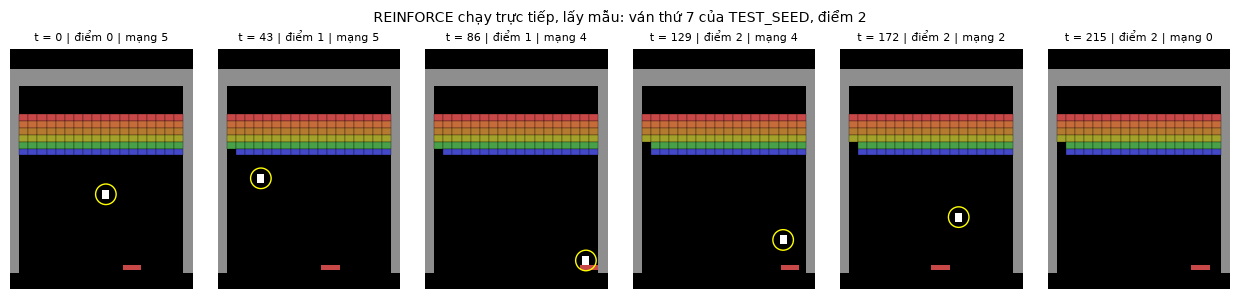

In [16]:
def reinforce_weights(rs, gamma, normalize=False, discount_t=True):
    # Trọng số của log pi(A_t | O_t) trong L(theta): gamma^t G_t (hoặc G_t chuẩn hóa trong lượt)
    G = np.zeros(len(rs)); acc = 0.0
    for k in range(len(rs) - 1, -1, -1):
        acc = rs[k] + gamma * acc; G[k] = acc
    if normalize:
        G = (G - G.mean()) / (G.std(ddof=1) + np.finfo(np.float32).eps) if len(G) > 1 else 0.0 * G
    return G * (gamma ** np.arange(len(rs)) if discount_t else 1.0)


w = reinforce_weights([0.0, 1.0, 0.0], 0.99)
print("trọng số gamma^t G_t:", w.round(4), "| lượt toàn 0:", reinforce_weights([0.0] * 5, 0.99, normalize=True))
assert np.allclose(w, [0.99, 0.99, 0.0]) and np.all(reinforce_weights([0.0] * 5, 0.99, normalize=True) == 0)


def train_reinforce_atari(cfg, seed=1, eval_every=None):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    env = make_breakout(); n_act = env.action_space.n
    net = NatureCNN(n_act).to(DEVICE)                        # logit h_theta(O), (b, 4)
    opt = torch.optim.Adam(net.parameters(), lr=cfg["lr"])
    T, K = cfg["T"], cfg.get("K", 1)
    ep, t, score, n_life, t0 = 0, 0, 0.0, 0, time.time()
    o, info = env.reset(seed=20_000 + 100_000 * seed)
    log = dict(ep_t=[], ep_score=[], entropy=[], life_ret=[])
    opt.zero_grad()
    while t < T:
        obs, acts, rs = [], [], []
        while True:                                           # bước 1: một lượt huấn luyện = một mạng
            with torch.no_grad():
                p = torch.softmax(net(obs_tensor(o))[0], -1).cpu().numpy().astype(float)
            a = int(min(np.searchsorted(np.cumsum(p), rng.random() * p.sum(), side="right"), n_act - 1))
            obs.append(np.asarray(o)); acts.append(a)
            o, r, term, trunc, info = env.step(a)
            score += r; rs.append(float(np.sign(r))); t += 1
            if term or trunc or info["life_lost"]:
                break
        if term or trunc:
            log["ep_t"].append(t); log["ep_score"].append(score); score = 0.0; ep += 1
            o, info = env.reset(seed=20_000 + 100_000 * seed + ep)
        w = reinforce_weights(rs, GAMMA, cfg.get("normalize", False))   # bước 2-3
        O = torch.from_numpy(np.stack(obs)); A = torch.tensor(acts).to(DEVICE); ent = 0.0
        for s in range(0, len(rs), 256):                      # theo đoạn 256 bước
            lp = torch.log_softmax(net(O[s:s + 256].to(DEVICE)), -1)   # (<=256, 4)
            ent += float(-(lp.exp() * lp).sum().detach())
            (-(torch.as_tensor(w[s:s + 256], dtype=torch.float32, device=DEVICE) * lp.gather(1, A[s:s + 256, None]).squeeze(1)).sum() / K).backward()
        n_life += 1; log["entropy"].append(ent / len(rs)); log["life_ret"].append(sum(rs))
        if n_life % K == 0:                                   # bước 4
            opt.step(); opt.zero_grad()
    log.update(n_episodes=ep, n_lives=n_life, train_secs=time.time() - t0)
    return net, log


net_rf, log_rf = train_reinforce_atari(dict(T=25_000, lr=1e-5), seed=AGENT_SEED)
H = np.array(log_rf["entropy"])
print(f"{log_rf['train_secs']:.0f} giây | {log_rf['n_lives']} lượt huấn luyện (mạng), {log_rf['n_episodes']} ván | "
      f"lượt có phần thưởng > 0: {np.mean(np.array(log_rf['life_ret']) > 0):.0%} | entropy 50 lượt đầu {H[:50].mean():.3f}, 50 lượt cuối {H[-50:].mean():.3f}")
res_rf = evaluate(net_rf, N_TEST, TEST_SEED, eps=None, kind="pi")
summarize("REINFORCE, 25 000 bước, lấy mẫu", res_rf)
print("Tham chiếu khi soạn (torch 2.15.0+cpu, hai luồng): 727 lượt huấn luyện, 21% lượt có phần thưởng > 0, "
      "entropy 1,386 ở 50 lượt đầu và 50 lượt cuối; điểm 1,27 ± 0,25")
def sample_pi(net):
    # chính sách lấy mẫu từ pi_theta = softmax(h_theta(O_t))
    def pol(o, rng):
        with torch.no_grad():
            p = torch.softmax(net(obs_tensor(o))[0], -1).cpu().numpy().astype(float)
        return int(min(np.searchsorted(np.cumsum(p), rng.random() * p.sum(), side="right"), 3))
    return pol


# Ván thứ 7 của TEST_SEED (TEST_SEED + 6): ván đầu cho 0 điểm với mọi chính sách chưa học đỡ bóng
ep_rf = record_breakout(sample_pi(net_rf), TEST_SEED + 6)
ep_random7 = record_breakout(lambda o, rng: int(rng.integers(4)), TEST_SEED + 6)
display(breakout_player({"chọn đều": ep_random7, "REINFORCE, 25 000 bước, lấy mẫu": ep_rf}))
breakout_strip(ep_rf, 6, f"REINFORCE chạy trực tiếp, lấy mẫu: ván thứ 7 của TEST_SEED, điểm {ep_rf['score']:.0f}")

**Ba lần chạy một triệu bước.** Không nguồn nào được kiểm có cấu hình REINFORCE trên Atari. Khi soạn, REINFORCE được chạy ba lần trên Breakout với hạt giống $1$, cùng mạng và tiền xử lý; hai lần đầu khác nhau ở bước học, lần thứ ba khác lần thứ hai ở phép chuẩn hóa lợi tức:

| Lần chạy | $\alpha$ | Chuẩn hóa lợi tức | Ghi chú |
|---|---|---|---|
| `lr1e-4` | $10^{-4}$ (bằng $\eta$ của DQN) | không | dừng thủ công ở khoảng $2\cdot10^5$ bước khi entropy đã về gần $0$ và điểm kiểm định bằng $0$; chỉ có nhật ký ở hai mốc |
| `lr1e-5` | $10^{-5}$ | không | Thuật toán 09.25 với $\gamma^t$; $10^6$ bước; $\alpha$ chọn nhỏ hơn mười lần sau khi lần `lr1e-4` sụp |
| `lr1e-5_norm` | $10^{-5}$ | có, trong từng lượt | giữ $\alpha$ của lần thứ hai để hai lần chỉ khác ở phép chuẩn hóa |

Ô mã dưới vẽ entropy trung bình của $50$ lượt huấn luyện gần nhất và điểm trung bình của $5$ ván `VALID_SEED` ở mỗi mốc $10^5$ bước, rồi in kết quả trên $30$ ván `TEST_SEED` của chính sách cuối (lấy mẫu và tham lam). Ô mã tiếp theo so hai chính sách đó với bốn chính sách hành động hằng (luôn `NOOP`, luôn `FIRE`, luôn `RIGHT`, luôn `LEFT`), đánh giá trực tiếp trên cùng $30$ ván, in tần suất hành động của hai chính sách REINFORCE trên các ván đó (đo khi soạn, nhúng sẵn), rồi phát một ván của chính sách luôn `RIGHT` và một ván ghi khi soạn của REINFORCE một triệu bước (kèm dải ảnh). Ván đầu của `TEST_SEED` cho $0$ điểm với mọi chính sách chưa học đỡ bóng (vợt không chạm bóng lần nào), nên các trình phát của mục này dùng ván thứ $7$ (`TEST_SEED + 6`), nơi luôn `RIGHT` được $9$ điểm.

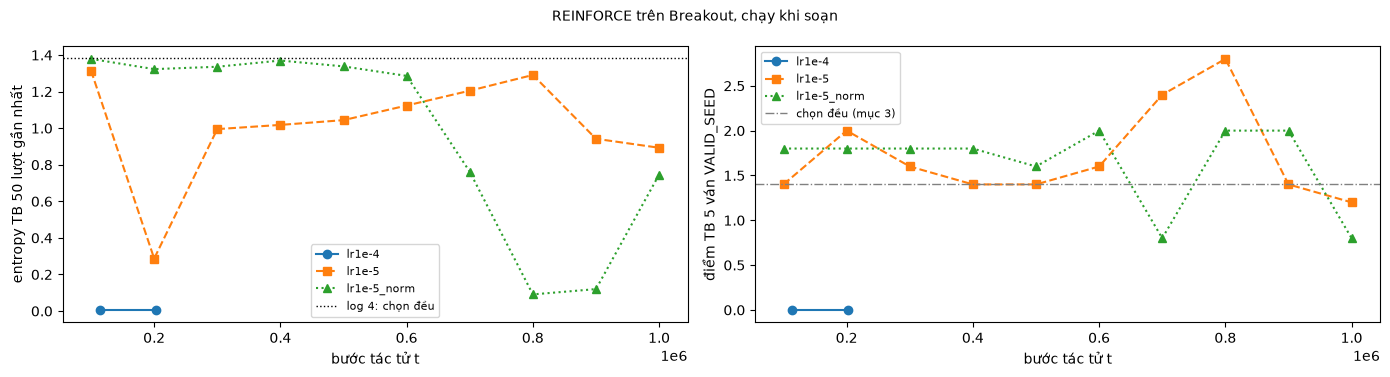

lr1e-4       dừng ở bước 202289: entropy 0.006, điểm kiểm định 0.0
lr1e-5       cuối, lấy mẫu   điểm  2.33 ± 0.39 (30 ván) | 25417 lượt huấn luyện, 2.6 giờ
lr1e-5       cuối, tham lam  điểm  2.43 ± 0.49 (30 ván) | 25417 lượt huấn luyện, 2.6 giờ
lr1e-5_norm  cuối, lấy mẫu   điểm  2.40 ± 0.44 (30 ván) | 26040 lượt huấn luyện, 2.6 giờ
lr1e-5_norm  cuối, tham lam  điểm  2.43 ± 0.49 (30 ván) | 26040 lượt huấn luyện, 2.6 giờ


In [17]:
RF = TABLES["rf"]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for (name, R), (ls, mk) in zip(RF.items(), [("-", "o"), ("--", "s"), (":", "^")]):
    P = np.array(R["prog"])
    axes[0].plot(P[:, 0], P[:, 3], ls=ls, marker=mk, label=name); axes[1].plot(P[:, 0], P[:, 2], ls=ls, marker=mk, label=name)
axes[0].axhline(np.log(4), color="k", ls=":", lw=1, label="log 4: chọn đều")
axes[0].set_ylabel("entropy TB 50 lượt gần nhất")
axes[1].axhline(res_random["score"].mean(), color="gray", ls="-.", lw=1, label="chọn đều (mục 3)")
axes[1].set_ylabel("điểm TB 5 ván VALID_SEED")
for ax in axes:
    ax.set_xlabel("bước tác tử t"); ax.legend(fontsize=8)
fig.suptitle("REINFORCE trên Breakout, chạy khi soạn", fontsize=10); fig.tight_layout(); plt.show()
for name, R in RF.items():
    if not R["done"]:
        print(f"{name:<12} dừng ở bước {R['prog'][-1][0]}: entropy {R['prog'][-1][3]:.3f}, điểm kiểm định {R['prog'][-1][2]:.1f}")
        continue
    for kind, lab in [("final_stoch", "cuối, lấy mẫu"), ("final_greedy", "cuối, tham lam")]:
        sc = np.array(R["eval"][kind]["score"])
        print(f"{name:<12} {lab:<15} điểm {sc.mean():5.2f} ± {sc.std(ddof=1) / np.sqrt(len(sc)):4.2f} ({len(sc)} ván) | "
              f"{R['n_lives']} lượt huấn luyện, {R['train_secs'] / 3600:.1f} giờ")

luôn NOOP  điểm  0.00 ± 0.00 | dài TB    120 bước


luôn FIRE  điểm  0.00 ± 0.00 | dài TB    117 bước


luôn RIGHT điểm  2.43 ± 0.49 | dài TB    217 bước


luôn LEFT  điểm  1.57 ± 0.57 | dài TB   1043 bước
Tham chiếu khi soạn: NOOP 0,00; FIRE 0,00; RIGHT 2,43 ± 0,49 (dài 217); LEFT 1,57 (dài 1043)
lr1e-5       tần suất hành động (NOOP, FIRE, RIGHT, LEFT): tham lam [0.0, 0.0, 1.0, 0.0], lấy mẫu [0.056, 0.301, 0.631, 0.011] | điểm tham lam trùng luôn RIGHT ở cả 30 ván: True
lr1e-5_norm  tần suất hành động (NOOP, FIRE, RIGHT, LEFT): tham lam [0.0, 0.0, 1.0, 0.0], lấy mẫu [0.128, 0.106, 0.755, 0.011] | điểm tham lam trùng luôn RIGHT ở cả 30 ván: True


Trình phát: 2 ván, HTML nhúng 23 kB


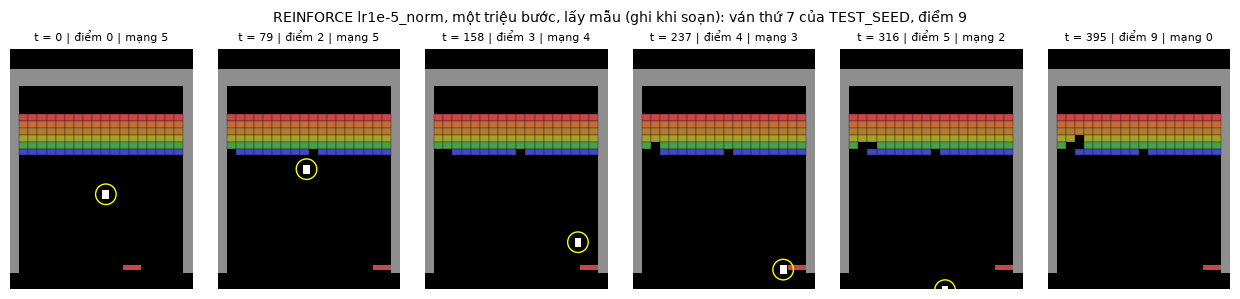

In [18]:
const_res = {}
for a, name in enumerate(["NOOP", "FIRE", "RIGHT", "LEFT"]):
    env_k = make_breakout(); sc, L = [], []
    for e in range(N_TEST):                                   # cùng 30 ván TEST_SEED, hành động hằng a
        o, _ = env_k.reset(seed=TEST_SEED + e); total, n = 0.0, 0
        while True:
            o, r, term, trunc, info = env_k.step(a); total += r; n += 1
            if term or trunc:
                break
        sc.append(total); L.append(n)
    const_res[name] = np.array(sc)
    print(f"luôn {name:<5} điểm {const_res[name].mean():5.2f} ± {const_res[name].std(ddof=1) / np.sqrt(N_TEST):4.2f} | dài TB {np.mean(L):6.0f} bước")
print("Tham chiếu khi soạn: NOOP 0,00; FIRE 0,00; RIGHT 2,43 ± 0,49 (dài 217); LEFT 1,57 (dài 1043)")
for name in ["lr1e-5", "lr1e-5_norm"]:
    F_ = TABLES["rf_freq"][name]; g = np.array(RF[name]["eval"]["final_greedy"]["score"])
    print(f"{name:<12} tần suất hành động (NOOP, FIRE, RIGHT, LEFT): tham lam {np.round(F_['greedy']['freq'], 3).tolist()}, "
          f"lấy mẫu {np.round(F_['stoch']['freq'], 3).tolist()} | điểm tham lam trùng luôn RIGHT ở cả 30 ván: "
          f"{bool(np.array_equal(g, const_res['RIGHT']))}")
eps_rf = {"luôn RIGHT (= tham lam của hai lần 1M)": record_breakout(lambda o, rng: 2, TEST_SEED + 6)}   # ván thứ 7
if "REINFORCE" in EP_SAVED:
    e = EP_SAVED["REINFORCE"]; eps_rf[f"REINFORCE {e['run']}, 1M bước, lấy mẫu (ghi khi soạn)"] = e
display(breakout_player(eps_rf))
if "REINFORCE" in EP_SAVED:
    breakout_strip(EP_SAVED["REINFORCE"], 6, f"REINFORCE {EP_SAVED['REINFORCE']['run']}, một triệu bước, lấy mẫu (ghi khi soạn): "
                   f"ván thứ 7 của TEST_SEED, điểm {EP_SAVED['REINFORCE']['score']:.0f}")

**Đọc kết quả.** Các số dưới đây là số khi soạn.

- **Lần chạy trực tiếp.** Sau $727$ lượt huấn luyện với $\alpha=10^{-5}$, entropy trung bình vẫn là $1{,}386$, tức chính sách gần như vẫn chọn đều, và điểm $1{,}27\pm0{,}25$ ngang chính sách chọn đều. Chỉ khoảng $21\%$ lượt có phần thưởng dương; các lượt còn lại cho $\widehat g=0$.
- **`lr1e-4`.** Ở mốc ghi đầu tiên ($113\,629$ bước), entropy đã là $0{,}006$ và điểm kiểm định bằng $0$; nhật ký không cho biết thời điểm sụp chính xác hơn. Chính sách khi đó gần như tất định và không phá được gạch nào, nên hầu hết lượt về sau có $G_t=0$, $\widehat g=0$, và chính sách gần như không đổi. Phần thưởng đã cắt không âm, nên mọi trọng số $\gamma^tG_t$ không âm và hướng $\widehat g$ đẩy log xác suất của các hành động đã chọn trong những lượt có phần thưởng lên; một cơ chế phù hợp với số liệu là vài cập nhật như vậy với bước học lớn đẩy chính sách về gần tất định trước khi nó học được cách giữ bóng. Lần chạy này được dừng thủ công ở khoảng $2\cdot10^5$ bước và được công bố như kết quả bị loại.
- **`lr1e-5`.** Entropy giảm xuống $0{,}29$ ở $2\cdot10^5$ bước rồi tăng lại quanh $1{,}0$–$1{,}3$ và kết thúc ở $0{,}89$. Chính sách cuối đạt $2{,}33\pm0{,}39$ điểm khi lấy mẫu và $2{,}43\pm0{,}49$ khi tham lam.
- **`lr1e-5_norm`.** Entropy giữ gần $\log4$ tới khoảng $6\cdot10^5$ bước, rơi về $0{,}09$–$0{,}12$ ở $8$–$9\cdot10^5$ bước rồi lên $0{,}75$; chính sách cuối đạt $2{,}40\pm0{,}44$ điểm khi lấy mẫu.
- **Chính sách tham lam suy biến.** Chính sách tham lam của cả hai lần chạy $\alpha=10^{-5}$ chọn `RIGHT` ở mọi bước của $30$ ván, và cho đúng chuỗi điểm của chính sách luôn `RIGHT` ($2{,}43\pm0{,}49$, cao nhất trong bốn chính sách hằng; luôn `NOOP` và luôn `FIRE` được $0$). Khi lấy mẫu, `RIGHT` chiếm $63\%$ và $75\%$ số bước. Điểm khoảng $1$ trên chính sách chọn đều vì vậy đo một hành vi gần hằng, không đo việc học đỡ bóng: lợi thế nhỏ đó có được từ việc dồn vợt về phía phải.

Sau một triệu bước, REINFORCE với $\alpha=10^{-5}$, có hoặc không chuẩn hóa lợi tức, chỉ học được một hành vi gần hằng; với $\alpha=10^{-4}$, chính sách đã gần tất định với điểm $0$ ở mốc $1{,}1\cdot10^5$ bước. Cùng ngân sách, DQN và Double DQN (mục 7) đạt $42$–$66$ điểm ở bốn trong sáu lần chạy. Bài 10 xây tiếp từ Định lý 09.23 bằng đường cơ sở để giảm phương sai và bằng hàm giá trị học được (actor–critic). Các cài đặt gradient chính sách trên Atari trong RL Baselines3 Zoo còn thêm hệ số entropy và nhiều môi trường song song (A2C: $16$ môi trường, hệ số entropy $0{,}01$, $10^7$ bước); đó là kỹ thuật cài đặt, không có trong ghi chú.

## 9. Đối chiếu với lý thuyết

**Bài toán huấn luyện và bài toán đánh giá.** DQN và Double DQN tối ưu giá trị của một bài toán khác với bài toán chấm điểm: phần thưởng cắt về $\{0,1\}$, mỗi lần mất mạng là trạng thái kết thúc. Một chính sách tối ưu cho bài toán huấn luyện phá gạch càng sớm càng tốt và giữ bóng trong mỗi mạng; nó không phân biệt gạch $1$ điểm với gạch $7$ điểm. Phép đo $Q_0-G_0$ ở mục 6–7 dùng $G_t$ của bài toán huấn luyện, vì $Q_\theta$ ước lượng đại lượng đó; điểm trên ván đầy đủ đo chất lượng theo bài toán gốc.

**Quan sát và giả thiết Markov.** Bốn khung xếp chồng cho vận tốc của bóng, nên $O_t$ gần đủ Markov hơn một khung đơn (Ví dụ 08.4). Lặp hành động ngẫu nhiên làm động lực ngẫu nhiên, và hành động thực hiện ở khung kế phụ thuộc hành động trước, một biến không có trực tiếp trong $O_t$; giả thiết Markov vì vậy chỉ thỏa gần đúng. Mệnh đề 08.8 cần quan sát đủ Markov, và Mệnh đề 09.2, 09.4 nói về độ chệch tại một quan sát cố định với ước lượng không chệch; mạng sau một triệu bước không thỏa giả thiết không chệch (Tình huống 09.1 của ghi chú; Nhận xét 09.6 cho phần giả thiết độc lập).

**REINFORCE.** Hệ quả 09.26 cho $\widehat g$ không chệch dưới (G1)–(G4) với lượt sinh bởi chính $\pi_{\theta_{\mathrm{old}}}$. Khi huấn luyện, mỗi lượt kết thúc ở một lần mất mạng trong khi ván còn tiếp tục, nên $G_t$ của một lượt không tính phần thưởng của các mạng sau. Trạng thái đầu của mỗi mạng sau mạng thứ nhất (lưới gạch còn lại, vị trí vợt) lại do các mạng trước sinh ra, tức phụ thuộc $\theta$; (G1) đòi phân phối trạng thái đầu $\rho_0$ không phụ thuộc $\theta$, nên không thỏa. $\widehat g$ khi đó là ước lượng không chệch của gradient lợi tức một mạng chỉ khi coi phân phối trạng thái đầu của mạng là cố định, và hướng cập nhật không là gradient không chệch của một hàm mục tiêu cố định. Nếu coi cả ván là một lượt, như khi đánh giá, (G1) thỏa với trạng thái đầu của ván, nhưng phải dùng lợi tức của cả ván, phương sai còn lớn hơn và mỗi ván chỉ cho một cập nhật. Phần thưởng thưa làm phần lớn lượt có $G_t=0$ ở mọi bước và không đóng góp gì; ở các lượt còn lại, mọi trọng số $\gamma^tG_t$ đều không âm. Hệ quả 09.26 không nói gì về phương sai hay tốc độ học; ba lần chạy ở mục 8 là bằng chứng thực nghiệm cho giới hạn mà Bài 10 xử lý bằng đường cơ sở và hàm giá trị học được (actor–critic).

## 10. Tổng kết

Notebook dựng lại đầy đủ đường đi của DQN trên Atari với ảnh làm quan sát: tiền xử lý $210\times160\times3\to4\times84\times84$, ba quy ước chỉ dùng khi huấn luyện (mất mạng là kết thúc, cắt phần thưởng, cắt ngắn $27\,000$ bước), bộ nhớ phát lại lưu mỗi khung một lần ($7$ KB thay cho $56$ KB mỗi mẫu), mạng Nature CNN $1\,686\,180$ tham số và mục tiêu Double DQN với mặt nạ mất mạng ($y=2{,}485$ thay cho $3{,}475$ của DQN trong ví dụ tính tay). Lần chạy trực tiếp $40\,000$ bước không cho chính sách tốt hơn chọn đều một cách phân biệt được (khi soạn: $1{,}60\pm0{,}52$ ở hai lần chạy trùng nhau, $0{,}60\pm0{,}11$ ở một lần chạy khi máy tải nặng, so với $1{,}40\pm0{,}18$), như kỳ vọng. Sau một triệu bước, bốn trong sáu lần chạy DQN và Double DQN đạt $42$–$66$ điểm trên ván đầy đủ với $\epsilon_{\mathrm{ev}}=0{,}05$; DQN hạt giống $3$ đạt $19{,}4$ (mốc kiểm định tốt nhất $35{,}0$), còn Double DQN hạt giống $2$ không học được ($1{,}7$). Với chính sách tham lam, DQN đánh giá cao ở cả ba hạt giống ($Q_0-G_0$ từ $0{,}91$ tới $1{,}76$); ở hai hạt giống đã học được, Double DQN đánh giá cao ít hơn ($0{,}47$ và $0{,}30$, so với $0{,}91$ và $1{,}42$ của DQN ở cùng hạt giống); ở hạt giống $2$, giá trị và lợi tức của Double DQN đều gần $0$. Với ba hạt giống, hiệu chưa phân biệt được ở mức $5\%$. REINFORCE với $\alpha=10^{-5}$, có hoặc không chuẩn hóa lợi tức, sau một triệu bước chỉ học được một hành vi gần hằng (chính sách tham lam luôn chọn `RIGHT`, $2{,}43$ điểm); với $\alpha=10^{-4}$, chính sách đã gần tất định với điểm $0$ ở mốc $1{,}1\cdot10^5$ bước.

**Kết quả theo mục.** Mục 2: chuỗi tiền xử lý và ba quy ước chỉ dùng khi huấn luyện. Mục 3: đánh giá trên ván đầy đủ, kiểm địa chỉ RAM, trình phát. Mục 4: Nature CNN và bộ nhớ phát lại theo khung. Mục 5: mục tiêu Double DQN với mặt nạ mất mạng. Mục 6: Double DQN chạy trực tiếp. Mục 7: DQN và Double DQN một triệu bước. Mục 8: REINFORCE.

**Giả thiết hay bị quên.** Mất mạng là kết thúc chỉ trong mục tiêu khi huấn luyện, môi trường không đặt lại; mẫu chuyển cuối của ván bị cắt ngắn không có $O'$; điểm đánh giá là điểm gốc trên ván đầy đủ, khác bài toán mà $Q_\theta$ học; ba hạt giống chỉ cho kiểm định với $\mathrm{df}=2$.

In [19]:
print(f"Tổng thời gian chạy notebook: {time.time() - T_START:.0f} giây ({(time.time() - T_START) / 60:.1f} phút)")

Tổng thời gian chạy notebook: 663 giây (11.0 phút)


## 11. Gợi mở tìm hiểu và cải tiến

Mỗi nhiệm vụ cần nhiều giờ CPU; trên Colab có GPU, biến `DEVICE` (mục 1) tự chuyển mạng và mini-batch sang GPU, rút ngắn đáng kể thời gian của bước tối ưu; khi so hai cấu hình, dùng ít nhất ba hạt giống và chỉ báo kết quả cuối trên `TEST_SEED`. Ô mã cuối mục có khung hàm cho nhiệm vụ 1, 2 và 4; ô đó chỉ kiểm trên số liệu tính tay của mục 5 và 8.

1. **Huber và cắt chuẩn gradient.** RL Baselines3 Zoo dùng hàm mất mát Huber và cắt chuẩn gradient ở $10$ (hàm `dqn_loss_huber`). Chạy Double DQN với hai thay đổi này, $5\cdot10^5$ bước, và so đường học với mục 7.
2. **Không coi mất mạng là kết thúc.** Dopamine không dùng quy ước này. Đặt `z = float(term)` trong `train_dqn_atari` (hàm `train_z`) và so đường học trong $5\cdot10^5$ bước đầu với mục 7 và với mốc Dopamine.
3. **Chu kỳ đồng bộ dài.** Dopamine đồng bộ sau $8000$ bước môi trường ($C=2000$ bước tối ưu với $F=4$). Đo $Q_0-G_0$ của DQN và Double DQN với $C=250$ và $C=2000$, như nhiệm vụ 1 của notebook thứ nhất.
4. **REINFORCE với hệ số entropy.** Cộng $\beta\,\mathcal H(\pi_\theta(\cdot\mid O_t))$ vào hàm mục tiêu (trừ khỏi $L$), với $\beta\in\{0{,}001;0{,}01\}$ như A2C của RL Baselines3 Zoo, và theo dõi entropy theo bước. Hàm `entropy_bonus_loss` là khung. Nêu vì sao hệ số này đổi hàm mục tiêu so với Định nghĩa 09.14.
5. **Phương sai trên Breakout.** Sao chép `grad_samples` từ notebook thứ nhất (mục 12), thay `run_episode` bằng vòng thu một mạng của `train_reinforce_atari`, và áp dụng cho chính sách khởi tạo trên Breakout với $M=50$ mạng. Đếm tỉ lệ mạng có $\widehat g=0$, báo tổng phương sai $V$ và ước lượng hiệu chỉnh $\lVert\bar g\rVert^2-V/M$, và chỉ so tỉ số $V/\lVert\bar g\rVert^2$ với CartPole khi ước lượng hiệu chỉnh dương.

In [20]:
def dqn_loss_huber(q_net, tgt_net, batch, gamma, double=True):
    # Nhiệm vụ 1: như dqn_loss nhưng dùng Huber; cắt chuẩn gradient đặt sau L.backward():
    #   nn.utils.clip_grad_norm_(q_net.parameters(), 10.0)
    O, A, R, O2, Z = batch
    q = q_net(O).gather(1, A.unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        q2 = tgt_net(O2)
        boot = q2.gather(1, q_net(O2).argmax(1, keepdim=True)).squeeze(1) if double else q2.max(1).values
        y = R + gamma * (1 - Z) * boot
    return nn.functional.smooth_l1_loss(q, y), q.detach(), y


def train_z(term, life_lost, use_life_loss=True):
    # Nhiệm vụ 2: cờ Z dùng trong mục tiêu
    return float(term or (life_lost and use_life_loss))


def entropy_bonus_loss(logits, A, w, beta):
    # Nhiệm vụ 4: L = - sum_t w_t log pi(A_t | O_t) - beta * sum_t H(pi(. | O_t)); logits (T, m), A (T,), w (T,)
    lp = torch.log_softmax(logits, -1)
    H = -(lp.exp() * lp).sum(1)
    return -(torch.as_tensor(w, dtype=torch.float32) * lp.gather(1, A[:, None]).squeeze(1)).sum() - beta * H.sum()


L_h, _, y_h = dqn_loss_huber(on, tg, batch3, 0.99)
assert torch.allclose(y_h, torch.tensor([2.485, 0.0, 1.0]))            # cùng mục tiêu như mục 5
assert train_z(False, True) == 1.0 and train_z(False, True, use_life_loss=False) == 0.0
lg = torch.zeros(3, 4)                                                   # chính sách chọn đều: H = log 4 mỗi bước
L_e = entropy_bonus_loss(lg, torch.tensor([0, 1, 2]), np.zeros(3), beta=0.01)
print(f"Huber, y = {y_h.numpy().round(3)} | entropy_bonus_loss với w = 0: {L_e.item():.5f} = -0,01 * 3 * log 4 = {-0.03 * np.log(4):.5f}")
assert abs(L_e.item() + 0.03 * np.log(4)) < 1e-6

Huber, y = [2.485 0.    1.   ] | entropy_bonus_loss với w = 0: -0.04159 = -0,01 * 3 * log 4 = -0.04159


### Tài liệu tham khảo

**Tài liệu của học phần**

- Ghi chú Bài 09: Mệnh đề 09.2, 09.4; Thuật toán 09.5, 09.25; Nhận xét 09.6; Định nghĩa 09.14; Định lý 09.23; Hệ quả 09.26.
- Ghi chú Bài 08: Nhận xét 08.2, Ví dụ 08.4, Thuật toán 08.13, Mệnh đề 08.8.
- Notebook thực hành thứ nhất của Bài 09 (`thuc-hanh-double-dqn-reinforce-cartpole-lunarlander-flappybird.ipynb`): mục 5, 8–10, 12.

**Bài báo**

- R. J. Williams, "Simple statistical gradient-following algorithms for connectionist reinforcement learning", *Machine Learning* 8, 1992, 229–256.
- V. Mnih và cộng sự, "Human-level control through deep reinforcement learning", *Nature* 518, 2015, 529–533 (mục Methods: tiền xử lý, kiến trúc, $\epsilon$ đánh giá $0{,}05$).
- H. van Hasselt, A. Guez, D. Silver, "Deep Reinforcement Learning with Double Q-learning", *AAAI*, 2016, arXiv:1509.06461 (cùng siêu tham số cho DQN và Double DQN; Breakout trong bảng điểm phụ lục).
- M. C. Machado và cộng sự, "Revisiting the Arcade Learning Environment: Evaluation Protocols and Open Problems for General Agents", *JAIR* 61, 2018, 523–562 (sticky actions).
- A. Anand, E. Racah, S. Ozair, Y. Bengio, M.-A. Côté, R. D. Hjelm, "Unsupervised State Representation Learning in Atari", *NeurIPS*, 2019 (bộ chú thích AtariARI: địa chỉ RAM của vợt và bóng trong Breakout).
- P. S. Castro, S. Moitra, C. Gelada, S. Kumar, M. G. Bellemare, "Dopamine: A Research Framework for Deep Reinforcement Learning", arXiv:1812.06110, 2018.

**Phần mềm và cấu hình**

- CleanRL `cleanrl/dqn_atari.py`, commit `fe8d8a03c4`: https://github.com/vwxyzjn/cleanrl/blob/fe8d8a03c41a7ef5b523e2e354bd01c363e786bb/cleanrl/dqn_atari.py.
- RL Baselines3 Zoo `hyperparams/dqn.yml`, `hyperparams/a2c.yml` (mục `atari`), commit `61956d90d9`: https://github.com/DLR-RM/rl-baselines3-zoo/tree/61956d90d9f8ac126043ed4024efa12a462d97e1/hyperparams.
- Dopamine `dopamine/jax/agents/dqn/configs/dqn.gin` và `baselines/atari/data/breakout.json`, commit `5873f5494e`: https://github.com/google/dopamine/tree/5873f5494ee0c2d7c016d0ab2ad530354fec59d0.
- Gymnasium 1.x (`AtariPreprocessing`, `FrameStackObservation`); Arcade Learning Environment, gói `ale-py`.